# 10 — VCG V3: từng bước tách T, consensus và so sánh V1/V2/V3

Notebook này chạy từ raw PTB, không yêu cầu output của notebook khác. Mỗi bước có markdown mô tả **đầu vào → thao tác → đầu ra**, cell số liệu và hình kiểm tra. Phần đánh giá cuối dùng cùng code/schema với phụ lục được thêm ở notebook 05 (V1) và 09 (V2).

~~~text
resources.json + ptbdb-files.json + split_manifest.csv
      ↓ kiểm kê / kiểm chứng dữ liệu
raw Frank XYZ → QC → morphology + detection → QRS anchors
      ↓
PQ baseline → median beat → QRS boundaries (giữ V1)
      ├─ V1: tangent ST/TP + threshold
      ├─ V2: quadratic-spline WT → single-lead → TLS onset/offset
      └─ C : magnitude-baseline threshold
      ↓
V3: joint complete-link consensus → candidate / accepted tách riêng
      ↓
QRS/T loops → PCA / 12 features → cùng bộ đánh giá cho mọi method
~~~

PTB hiện chưa có nhãn độc lập T-on/T-off trong project. Vì vậy **coverage, agreement, stability và feature sensitivity** đo khả năng trả kết quả và tính nhất quán. Chúng không xác nhận độ chính xác biên T. MI/HC có nhãn chẩn đoán nên metric phân loại được tính ở option cuối, với ý nghĩa khác.

## 0. Cách chạy và các notebook để đối chiếu

Chọn kernel có các package trong requirements.txt. Nếu thiếu package, chạy thủ công cell cài thư viện bên dưới rồi restart kernel. Chạy các cell từ trên xuống; các cell định nghĩa hàm dài có thể thu gọn, các cell visual luôn hiển thị bằng display/plt.

| Chế độ | Thiết lập | Kết quả |
|---|---|---|
| Xem từng bước một ca | CX_RUN_COHORT=False (chỉ khi chủ động đổi) | Raw/QC/QRS/V1/V2/C/V3, loop, features, robustness demo |
| Kiểm tra cohort nhỏ | True; LIMIT=20; SCOPE=train_valid | Cùng 20 record chọn xác định cho mọi method |
| Full train/valid | True; LIMIT=None; SCOPE=train_valid | So sánh options trên tập phát triển |
| Báo cáo sau khi khóa method | True; LIMIT=None; SCOPE=all | Mọi record trong split; test chỉ dùng báo cáo cuối |
| Downstream MI/HC | Full all + CX_RUN_ML=True | Cùng split/model, record và patient metrics |
| Lưu bảng/hình | CX_SAVE_REPORTS / CX_SAVE_FIGURES=True | Output riêng theo notebook + run_tag + protocol hash |

V1 chi tiết: [05](05_QRS_T_Loops_Step_by_Step.ipynb), feature split V1: [06](06_PTB_VCG_12_Features_Train_Valid_Test.ipynb); V2 chi tiết: [09](09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment.ipynb). Các notebook 05/09 được bổ sung cùng phụ lục đánh giá cuối để bạn chạy cả ba và so CSV cùng schema.

Cần cùng CX_DEMO_ID, CX_SECONDS, config, scope, cohort limit và protocol ID giữa ba lần chạy. Đổi cấu hình thì Restart & Run All để tránh state cũ. Không chạy create_v3_notebook.py để giữ nội dung notebook đã chỉnh trực tiếp.

### Chạy hết dữ liệu đang sử dụng và tránh leakage

Mặc định phần đánh giá chạy **mọi record trong `data/split_manifest.csv`** (hiện 448 MI/HC), không giới hạn 20 record. Mỗi record dùng tối đa `CX_SECONDS=30` giây như pipeline hiện hành; “toàn bộ cohort” không có nghĩa đọc hết thời lượng từng recording. Các hình từng bước phía trên dùng một ca minh họa, không thay thế đánh giá cohort.

- Cùng raw, median, QRS, RR, split và tiêu chí cho V1/V2/C/V3; mỗi method giữ đủ các record kể cả lỗi. Notebook 05 có báo cáo riêng V1, 09 riêng V2, 10 riêng V3; bảng chung chứa mọi method.
- Train, valid và test có bảng/hình riêng; kiểm tra patient ID trùng split sẽ dừng. Không gộp ba split thành một điểm chất lượng tổng.
- Các option chỉ sweep trên train/valid và hiển thị riêng từng split. Cấu hình mặc định V3 đã cố định trước khi chạy; code không chọn option theo test. Khi đổi phương pháp, dùng train/valid và khóa lại trước một lần báo cáo test mới.
- Imputer, scaler, Logistic Regression chỉ fit train; valid/test chỉ transform/predict, ngưỡng MI=0.5 cố định. Nhãn MI/HC không truyền vào delineation.
- Noise, beat bootstrap và feature sensitivity mặc định chạy trên toàn bộ cohort, dùng cùng seeds/scenarios cho các method; số liệu vẫn tách theo split. Đây là kiểm tra độ ổn định, chưa là accuracy biên T.
- Mỗi notebook tự chạy độc lập từ raw. Checkpoint chung ở `outputs/vcg_shared_comparison/_cache/<protocol>` kiểm tra hash header/waveform và protocol/package/config trước khi tái sử dụng. Lần đầu lâu hơn; tiến độ in mỗi 10 record. Thời gian lấy từ cache là thời gian lần tính đầu, không dùng để xếp hạng tốc độ giữa notebook.
- Kết quả tự lưu CSV/PNG dưới `outputs/vcg_shared_comparison/<notebook>/<run_tag_protocol>/`; `methods/V1`, `methods/V2`, `methods/C`, `methods/V3` là báo cáo riêng. Cell cuối đối chiếu manifest và kết quả số giữa ba lần chạy nếu đã có đủ file.

Khởi động lại kernel rồi chạy từ trên xuống. Có thể chạy riêng phụ lục đánh giá của 05/09 khi raw đã có. Không cần chạy script sinh notebook. Muốn thử nhanh, đổi `CX_COHORT_LIMIT=20`; kết quả khi đó được ghi protocol khác và không dùng làm báo cáo toàn bộ. Không bật khảo sát option trên test.


In [1]:
# Chỉ bỏ dấu # nếu kernel thiếu package; không cần khi môi trường đã đủ.
# %pip install -r requirements.txt

## 1. Cấu hình tập trung — đọc trước khi chạy

Cửa sổ raw mặc định 30 giây; fs lấy từ header, không giả định luôn 1000 Hz. Tolerance là ms và được đổi sang native sample. Candidate duration dùng màn kiểm tra chung 60–400 ms; khoảng này là heuristic review, không được ép kéo dài T để pass.

V3 hiện là thử nghiệm do project đề xuất, khác phương pháp trong bài Almeida. V1 và C có tương quan; V2 dùng cùng QRS/RR nhưng không nhận nhãn hoặc V1 T marks. Đọc [METHOD_REPRODUCTION.md](METHOD_REPRODUCTION.md) để xem các adaptation WT/TLS.

In [2]:
CX_NOTEBOOK = "10_VCG_V3_Consensus_T_Delineation.ipynb"
from pathlib import Path
from dataclasses import asdict, replace
from itertools import combinations, product
import hashlib, json, sys, time, copy, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CX_ROOT = next((p for p in [Path.cwd(), Path.cwd() / "VCG", *Path.cwd().parents]
                if (p / "vcg_pipeline.py").is_file()), None)
if CX_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục vcg/VCG hoặc vcg.")
CX_ROOT = CX_ROOT.resolve()
if str(CX_ROOT) not in sys.path: sys.path.insert(0, str(CX_ROOT))
from vcg_preprocessing import Config, assess_input_quality, welch_xyz
from vcg_pipeline import (FEATURE_NAMES, load_xyz, preprocess_xyz, detect_qrs_anchors,
    representative_beat, delineate_loops, cut_loop, extract_features, spatial_speed,
    project_pca, flattest_pq, ms_samples, plot_delineation)
from vcg_t_almeida import AlmeidaConfig, delineate_t, wavelet_transform, json_safe

# Cùng các giá trị này trong 05, 09 và 10 để so sánh được.
CX_DATA_ROOT = CX_ROOT / "content/ptbdb/physionet.org/files/ptbdb/1.0.0"
CX_DEMO_ID = "patient104/s0306lre"
CX_RUN_COHORT = True
CX_COHORT_LIMIT = None           # None = toàn bộ phạm vi đã chọn
CX_SCOPE = "all"       # train_valid / test / all
CX_SECONDS = 30.0
CX_TOLERANCE_MS = 25.0
CX_MIN_VOTES = 2
CX_DURATION_MS = (60.0, 400.0)  # màn kiểm tra chung; không clip/ép kéo dài sóng
CX_NOISE_LEVELS = (0.005, 0.01, 0.02)
CX_SEEDS = (0, 1, 2, 3, 4)
CX_RUN_STABILITY = True        # toàn cohort, tách split; noise lên median
CX_RUN_BOOTSTRAP = True        # toàn cohort; resample các beat đã giữ
CX_BOOTSTRAP_REPEATS = 10
CX_RUN_SENSITIVITY = True
CX_RUN_ML = True              # chỉ có ý nghĩa khi đủ cohort train/val/test
CX_SAVE_REPORTS = True
CX_SAVE_FIGURES = True
CX_RUN_COHORT_OPTIONS = True   # chỉ train/valid; không sweep test
CX_REUSE_CACHE = True
CX_RAW_IDENTITIES = {}
CX_FOCUS_METHOD = "V3"
CX_RUN_TAG = "full_cohort_01"   # đổi khi thay cấu hình hoặc thực hiện final test
CX_V1_CFG, CX_V2_CFG = Config(seconds=CX_SECONDS), AlmeidaConfig()
CX_METHODS = ("V1", "V2", "C", "V3")
CX_COLORS = {"V1":"#d97706", "V2":"#7c3aed", "C":"#0891b2", "V3":"#dc2765"}
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"font.family":"DejaVu Sans", "figure.dpi":105, "font.size":10})

def cx_file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""): h.update(block)
    return h.hexdigest()

def cx_signal_hash(xyz):
    return hashlib.sha256(np.ascontiguousarray(xyz, dtype="<f8").tobytes()).hexdigest()

def cx_index(value, n):
    try: return np.isfinite(value) and int(value) == value and 0 <= int(value) < n
    except (TypeError, ValueError, OverflowError): return False

def cx_ms(value, st):
    return (int(value)-st["rep"]["anchor"])*1000/st["fs"] if cx_index(value,len(st["rep"]["xyz"])) else np.nan

CX_SPLIT = pd.read_csv(CX_ROOT / "data/split_manifest.csv")
CX_SPLIT["split"] = CX_SPLIT["split"].replace({"valid":"val", "validation":"val"})
assert CX_SPLIT.record_id.is_unique, "record_id lặp trong split manifest"
assert CX_SPLIT.groupby("patient_id").split.nunique().max() == 1, "Patient leakage!"
assert CX_SPLIT.groupby("patient_id").label_name.nunique().max() == 1, "Patient label mismatch"
assert CX_SPLIT.label_name.isin(["MI","HC"]).all()
_cx_notebook = json.loads((CX_ROOT/CX_NOTEBOOK).read_text(encoding="utf-8"))
_cx_shared_sources = ["".join(c["source"]) for c in _cx_notebook["cells"]
                      if "cx_shared_definition" in c.get("metadata",{}).get("tags",[])]
CX_SHARED_CODE_SHA256 = hashlib.sha256("\n".join(_cx_shared_sources).encode()).hexdigest()
cx_config = dict(shared_code_sha256=CX_SHARED_CODE_SHA256, protocol="vcg-shared-split-cohort-2.0", seconds=CX_SECONDS,
    tolerance_ms=CX_TOLERANCE_MS, min_votes=CX_MIN_VOTES, duration_ms=CX_DURATION_MS,
    v1=asdict(CX_V1_CFG), v2=asdict(CX_V2_CFG), scope=CX_SCOPE,
    noise_levels=CX_NOISE_LEVELS, seeds=CX_SEEDS, cohort_limit=CX_COHORT_LIMIT,
    run_stability=CX_RUN_STABILITY, run_bootstrap=CX_RUN_BOOTSTRAP, bootstrap_repeats=CX_BOOTSTRAP_REPEATS,
    run_sensitivity=CX_RUN_SENSITIVITY, run_ml=CX_RUN_ML, cohort_options=CX_RUN_COHORT_OPTIONS,
    ml_feature_policy="valid", classifier="balanced LogisticRegression; threshold=.5; train-only preprocessing",
    packages={p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","matplotlib","wfdb","scikit-learn")},
    files_manifest_sha256=cx_file_hash(CX_ROOT/"data/ptbdb-files.json"),
    resources_sha256=cx_file_hash(CX_ROOT/"data/resources.json"),
    split_sha256=cx_file_hash(CX_ROOT/"data/split_manifest.csv"),
    source_sha256={p:cx_file_hash(CX_ROOT/p) for p in
        ["vcg_pipeline.py","vcg_preprocessing.py","vcg_t_almeida.py"]})
CX_PROTOCOL_ID = hashlib.sha256(json.dumps(cx_config,sort_keys=True).encode()).hexdigest()[:16]
CX_OUT = CX_ROOT/"outputs"/"vcg_shared_comparison"/Path(CX_NOTEBOOK).stem/(CX_RUN_TAG+"_"+CX_PROTOCOL_ID)
CX_CACHE = CX_ROOT/"outputs/vcg_shared_comparison/_cache"/CX_PROTOCOL_ID
CX_RESULTS = {}
def cx_show(fig, name):
    # Nhúng PNG tĩnh để VS Code/Jupyter không phụ thuộc widget/backend hiện tại.
    from io import BytesIO
    from IPython.display import Image
    fig.canvas.draw()
    with BytesIO() as png:
        fig.savefig(png,format="png",dpi=plt.rcParams["figure.dpi"],bbox_inches="tight")
        display(Image(data=png.getvalue()))
    if CX_SAVE_FIGURES:
        CX_OUT.mkdir(parents=True, exist_ok=True)
        fig.savefig(CX_OUT/(name+".png"), dpi=180, bbox_inches="tight")
    plt.close(fig)
print("Root:", CX_ROOT, "\nData:", CX_DATA_ROOT, "\nProtocol:", CX_PROTOCOL_ID)
print("Output:", CX_OUT, "\nCohort:", CX_RUN_COHORT, "| scope:", CX_SCOPE)
print("Mặc định FULL manifest:",len(CX_SPLIT),"record | riêng:",CX_FOCUS_METHOD,"| split tách biệt; checkpoint:",CX_CACHE)


Root: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG 
Data: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\content\ptbdb\physionet.org\files\ptbdb\1.0.0 
Protocol: 5689e262aabaf89b
Output: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\10_VCG_V3_Consensus_T_Delineation\full_cohort_01_5689e262aabaf89b 
Cohort: True | scope: all
Mặc định FULL manifest: 448 record | riêng: V3 | split tách biệt; checkpoint: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\_cache\5689e262aabaf89b


### Các hàm dùng chung cho cả ba notebook

Cell sau chứa reader raw → median, adapter V1/V2/C, consensus và evaluator. Toàn bộ thuật toán có thể mở cell để đọc; các cell bước phía dưới gọi từng phần và in intermediates. Hash của chính các cell shared được đưa vào protocol ID để phát hiện khác code giữa ba notebook.

**Consensus:** xét mọi nhóm ≥ min_votes; cùng nhóm phải có max–min ≤ tolerance cho cả T-on và T-off. Ưu tiên nhóm nhiều thành viên, rồi ít dispersion; median xác định pair. Flags từ voters và QC input vẫn được giữ. Không đủ phiếu trả unresolved, không fallback âm thầm về V1.

In [3]:
def cx_load_state(rid):
    started = time.perf_counter()
    raw = load_xyz(CX_DATA_ROOT / rid, CX_V1_CFG.seconds)
    fs = raw["fs"]
    morph, detection, prep = preprocess_xyz(raw["xyz"], fs, CX_V1_CFG, return_diagnostics=True)
    detector = detect_qrs_anchors(morph, detection, fs, CX_V1_CFG)
    rep = representative_beat(morph, detector["anchors"], fs, CX_V1_CFG, quality=prep["input_quality"])
    common_flags = sorted(set(detector["flags"] + rep["quality_flags"] +
                             prep.get("warnings", [])))
    if rep["n_used"] < 5: common_flags.append("few_representative_beats")
    if rep["n_excluded"]/max(len(detector["anchors"]),1) > .4:
        common_flags.append("many_excluded_beats")
    return dict(record_id=rid, raw=raw, fs=fs, morph=morph, detection=detection,
                preprocessing=prep, detector=detector, rep=rep,
                common_flags=sorted(set(common_flags)),
                shared_seconds=time.perf_counter()-started)

def cx_order(st, b):
    n = len(st["rep"]["xyz"])
    q0,q1,on,off = [b.get(k) for k in ("qrs_on","qrs_off","t_on","t_off")]
    if not all(cx_index(v,n) for v in (q0,q1,on,off)): return False
    if not q0 < st["rep"]["anchor"] < q1 < on < off: return False
    peaks = b.get("peaks", [])
    return all(cx_index(p,n) and on < p < off for p in peaks if p is not None)

def cx_hard_flags(st, b, valid, plausible):
    # QC/morphology warnings remain visible but do not erase a valid
    # candidate. Only data/pipeline/order failures block accepted.
    hard=[];quality=st.get("preprocessing",{}).get("input_quality",{})
    if quality.get("invalid_samples",0):hard.append("input_qc_fail")
    if not valid:hard.append("invalid_or_missing_T_pair")
    if valid and not plausible:hard.append("duration_review")
    for f in b.get("flags",[]):
        if f.startswith(("missing_","no_","error","invalid_","threshold_crossing_missing")):hard.append(f)
    return sorted(set(hard))

def cx_derivative(st, q):
    # C là magnitude-baseline threshold kiểm tra chéo, không phải detector độc lập.
    from scipy.signal import savgol_filter, find_peaks
    fs,rep=st["fs"],st["rep"]; xyz=rep["xyz"]; n=len(xyz)
    out=dict(method="C",status="unresolved",flags=[],qrs_on=q.get("qrs_on"),qrs_off=q.get("qrs_off"),
             t_on=None,t_off=None,peaks=[],trace={})
    if not cx_index(q.get("qrs_off"),n):
        out["flags"]=["missing_qrs_off"]; return out
    win=min(n if n%2 else n-1, max(5,ms_samples(21,fs)|1))
    smooth=savgol_filter(np.linalg.norm(xyz,axis=1),win,3)
    lo=int(q["qrs_off"])+ms_samples(20,fs)
    hi=min(n-1,rep["anchor"]+int(min(.60,.70*rep["rr_seconds"])*fs))
    if hi-lo < ms_samples(100,fs):
        out["flags"]=["short_t_window"]; return out
    pq=smooth[slice(*rep["pq"])]
    base=float(np.median(pq)); noise=max(float(1.4826*np.median(abs(pq-base))),1e-6)
    peaks,props=find_peaks(smooth[lo:hi+1],prominence=max(3*noise,1e-6),
                           distance=ms_samples(40,fs))
    peaks=peaks+lo
    out["trace"]=dict(smooth=smooth,search=(lo,hi),baseline=base,noise=noise)
    if not len(peaks):
        out["flags"]=["no_t_peak"]; return out
    peak=int(peaks[np.argmax(props["prominences"])])
    threshold=base+max(3*noise,.08*max(smooth[peak]-base,0)); run=ms_samples(20,fs)
    def crossing(start,stop,step):
        count=0
        for i in range(start,stop+step,step):
            count=count+1 if smooth[i] <= threshold else 0
            if count >= run: return i-run+1 if step>0 else i+run-1
        return None
    out.update(t_on=crossing(peak,lo,-1), t_off=crossing(peak,hi,1), peaks=[peak])
    out["trace"].update(threshold=threshold,peak=peak)
    if smooth[peak]-base<=5*noise: out["flags"].append("t_low_amplitude")
    if out["t_on"] is None or out["t_off"] is None: out["flags"].append("threshold_crossing_missing")
    out["status"]="detected" if cx_order(st,out) else "unresolved"
    return out

def cx_candidates(st):
    rep,fs=st["rep"],st["fs"]
    started=time.perf_counter(); q=delineate_loops(rep,fs,CX_V1_CFG)
    v1=dict(method="V1",status="detected",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
            t_on=q["t_on"],t_off=q["t_off"],peaks=[q["t_peak"]] if q["t_peak"] is not None else [],
            flags=list(q["flags"]),trace=q)
    if not cx_order(st,v1): v1["status"]="unresolved"
    v1["algorithm_seconds"]=time.perf_counter()-started
    started=time.perf_counter()
    v2=dict(method="V2",status="unresolved",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
            t_on=None,t_off=None,peaks=[],flags=[],trace={})
    if cx_index(q["qrs_on"],len(rep["xyz"])) and cx_index(q["qrs_off"],len(rep["xyz"])):
        try:
            trace=delineate_t(rep["xyz"],fs,rep["anchor"],q["qrs_on"],q["qrs_off"],
                              rep["rr_seconds"],CX_V2_CFG)
            peaks=[]
            for boundary,pick in (("t_on",0),("t_off",-1)):
                pp=trace.get("branches",{}).get(boundary,{}).get("peaks",[])
                if pp: peaks.append(pp[pick])
            v2.update(status=trace["status"],t_on=trace.get("t_on_sample"),t_off=trace.get("t_off_sample"),
                      flags=list(trace.get("review_flags",[])),peaks=peaks,trace=trace)
            if trace.get("failure_reason"): v2["flags"].append(trace["failure_reason"])
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
            v2.update(status="error",flags=[type(exc).__name__+": "+str(exc)])
    else: v2["flags"]=["missing_qrs"]
    v2["algorithm_seconds"]=time.perf_counter()-started
    started=time.perf_counter(); c=cx_derivative(st,v1)
    c["algorithm_seconds"]=time.perf_counter()-started
    return {"V1":v1,"V2":v2,"C":c}

def cx_consensus(st, candidates, tolerance_ms=None, min_votes=None, members=("V1","V2","C")):
    # Chọn một nhóm phương pháp hỗ trợ CẢ cặp biên.
    # Complete-link: max-min <= tolerance ở cả onset và offset; tránh chuỗi nối xa.
    tolerance_ms=CX_TOLERANCE_MS if tolerance_ms is None else float(tolerance_ms)
    min_votes=CX_MIN_VOTES if min_votes is None else int(min_votes)
    assert tolerance_ms>0 and 2<=min_votes<=len(members)
    start=time.perf_counter(); fs=st["fs"]
    q=candidates["V1"]
    out=dict(method="V3",status="unresolved",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
             t_on=None,t_off=None,peaks=[],flags=[],trace={})
    usable=[m for m in members if candidates[m]["status"] in ("detected","needs_review")
            and cx_order(st,candidates[m])]
    groups=[]
    for size in range(min_votes,len(usable)+1):
        for g in combinations(usable,size):
            on=np.array([candidates[m]["t_on"] for m in g]); off=np.array([candidates[m]["t_off"] for m in g])
            if max(np.ptp(on),np.ptp(off))*1000/fs <= tolerance_ms + 1e-9:
                groups.append((g,on,off))
    out["trace"].update(usable=usable,tolerance_ms=tolerance_ms,min_votes=min_votes)
    if not groups:
        out["flags"]=["no_joint_boundary_agreement"]
    else:
        # Tie không phụ thuộc nhãn; ít dispersion nhất rồi alphabet.
        groups.sort(key=lambda e:(-len(e[0]),float(np.std(e[1])+np.std(e[2])),e[0]))
        g,on,off=groups[0]
        out.update(t_on=int(np.floor(np.median(on)+.5)),t_off=int(np.floor(np.median(off)+.5)))
        out["trace"].update(voters=list(g),votes=len(g),
            on_spread_ms=float(np.std(on)*1000/fs),off_spread_ms=float(np.std(off)*1000/fs),
            on_range_ms=float(np.ptp(on)*1000/fs),off_range_ms=float(np.ptp(off)*1000/fs))
        # Mỗi candidate giữ peak riêng; không chế tạo "consensus peak" cho V2.
        member_peaks=[p for m in g for p in candidates[m].get("peaks",[]) if p is not None]
        if not all(out["t_on"]<p<out["t_off"] for p in member_peaks):
            out["flags"].append("consensus_excludes_member_peak")
        out["flags"] += [m+":"+f for m in g for f in candidates[m].get("flags",[])]
        duration=(out["t_off"]-out["t_on"])*1000/fs
        if not CX_DURATION_MS[0]<=duration<=CX_DURATION_MS[1]: out["flags"].append("duration_review")
        out["status"]="detected" if cx_order(st,out) and not out["flags"] else "needs_review"
    out["algorithm_seconds"]=time.perf_counter()-start
    out["flags"]=sorted(set(out["flags"]))
    return out

def cx_all(st):
    candidates=cx_candidates(st)
    candidates["V3"]=cx_consensus(st,candidates)
    return candidates

def cx_evaluate(st,b):
    rep,fs=st["rep"],st["fs"]; xyz=rep["xyz"]; n=len(xyz)
    valid=cx_order(st,b)
    q0,q1,on,off=[b.get(k) for k in ("qrs_on","qrs_off","t_on","t_off")]
    duration=(off-on)*1000/fs if valid else np.nan
    plausible=bool(valid and CX_DURATION_MS[0]<=duration<=CX_DURATION_MS[1])
    flags=sorted(set(st["common_flags"]+b.get("flags",[])))
    if not valid: flags.append("invalid_or_missing_T_pair")
    if valid and not plausible: flags.append("duration_review")
    hard_flags=cx_hard_flags(st,b,valid,plausible)
    accepted=bool(valid and plausible and not hard_flags and b["status"] in ("detected","needs_review"))
    speed=spatial_speed(xyz,fs,CX_V1_CFG)
    qloop=cut_loop(xyz,q0,q1) if all(cx_index(v,n) for v in (q0,q1)) else None
    # Candidate feature để chẩn đoán; accepted-feature được mask riêng khi export/ML.
    tloop=cut_loop(xyz,on,off) if valid else None
    features=extract_features(qloop,tloop,fs,CX_V1_CFG,speeds={
        "QRS":speed[q0:q1+1] if qloop is not None else None,
        "T":speed[on:off+1] if tloop is not None else None})
    pqmag=np.linalg.norm(xyz[slice(*rep["pq"])],axis=1)
    noise=max(float(1.4826*np.median(abs(pqmag-np.median(pqmag)))),1e-9)
    p=project_pca(tloop) if tloop is not None else None
    tr=b.get("trace",{})
    row=dict(record_id=st["record_id"],patient_id=st["record_id"].split("/")[0],method=b["method"],
        protocol_id=CX_PROTOCOL_ID,signal_sha256=cx_signal_hash(xyz),fs_hz=fs,anchor=rep["anchor"],
        native_status=b["status"],boundary_present=all(cx_index(v,n) for v in (on,off)),
        onset_present=cx_index(on,n),offset_present=cx_index(off,n),
        valid_pair=valid,duration_plausible=plausible,accepted=accepted,hard_flags=";".join(hard_flags),
        t_on_ms=cx_ms(on,st),t_off_ms=cx_ms(off,st),qrs_on_ms=cx_ms(q0,st),qrs_off_ms=cx_ms(q1,st),
        duration_ms=duration,flags=";".join(sorted(set(flags))),
        common_flags=";".join(st["common_flags"]),method_flags=";".join(b.get("flags",[])),
        feature_complete=bool(np.isfinite(list(features.values())).all()),
        n_used=rep["n_used"],n_excluded=rep["n_excluded"],median_rr_ms=rep["rr_seconds"]*1000,
        shared_seconds=st.get("shared_seconds",0),algorithm_seconds=b.get("algorithm_seconds",np.nan),
        total_method_seconds=b.get("algorithm_seconds",np.nan),
        pq_noise_proxy_mV=noise,
        amplitude_to_PQ_noise_proxy=(features["T_MaxVec"]/noise if valid else np.nan),
        loop_closure_mV=(float(np.linalg.norm(tloop[-1]-tloop[0])) if valid else np.nan),
        closure_normalized=(float(np.linalg.norm(tloop[-1]-tloop[0]))/max(features["T_MaxVec"],1e-9) if valid else np.nan),
        pca_variance_2d=(p["variance"] if p else np.nan),
        votes=tr.get("votes",np.nan),on_spread_ms=tr.get("on_spread_ms",np.nan),off_spread_ms=tr.get("off_spread_ms",np.nan),
        **features)
    # V3 end-to-end cost = shared preprocessing + tất cả candidate + aggregation.
    return row,dict(qrs_loop=qloop,t_loop=tloop,features=features,accepted=accepted,flags=flags)

def cx_record_rows(st,results):
    rows=[]
    for name,b in results.items():
        row,_=cx_evaluate(st,b)
        row["total_method_seconds"]=st.get("shared_seconds",0)+(
            sum(results[m].get("algorithm_seconds",0) for m in ("V1","V2","C","V3"))
            if name=="V3" else results["V1"].get("algorithm_seconds",0)+b.get("algorithm_seconds",0)
            if name in ("V2","C") else b.get("algorithm_seconds",0))
        rows.append(row)
    return rows

def cx_failure_row(rid, method):
    # Giữ cùng schema khi mọi record đều lỗi: bảng/plot vẫn có cột numeric.
    numeric = ("fs_hz", "anchor", "t_on_ms", "t_off_ms", "qrs_on_ms", "qrs_off_ms",
        "duration_ms", "n_used", "n_excluded", "median_rr_ms", "shared_seconds",
        "algorithm_seconds", "total_method_seconds", "pq_noise_proxy_mV",
        "amplitude_to_PQ_noise_proxy", "loop_closure_mV", "closure_normalized",
        "pca_variance_2d", "votes", "on_spread_ms", "off_spread_ms")
    row = dict.fromkeys((*numeric, *FEATURE_NAMES), np.nan)
    row.update(record_id=rid, patient_id=rid.split("/")[0], method=method,
        protocol_id=CX_PROTOCOL_ID, signal_sha256=None, native_status="error",
        accepted=False, hard_flags="input_or_pipeline_error", valid_pair=False, boundary_present=False, onset_present=False,
        offset_present=False, feature_complete=False, duration_plausible=False,
        flags="input_or_pipeline_error", common_flags="input_or_pipeline_error", method_flags="")
    return row



In [4]:
def cx_summary(frame):
    rows=[]
    for method,g in frame.groupby("method",sort=False):
        row=dict(method=method,attempted=len(g),patients=g.patient_id.nunique())
        for c in ("onset_present","offset_present","boundary_present","valid_pair","duration_plausible","accepted","feature_complete"):
            row[c+"_n"]=int(g[c].fillna(False).astype(bool).sum())
            row[c+"_pct"]=100*row[c+"_n"]/len(g)
        row["error_n"]=int(g.native_status.eq("error").sum())
        for c in ("duration_ms","closure_normalized","pca_variance_2d","algorithm_seconds","total_method_seconds"):
            if c in g:
                x=pd.to_numeric(g[c],errors="coerce").dropna()
                row[c+"_n"]=len(x)
                row[c+"_median"]=x.median()
                row[c+"_p90"]=x.quantile(.9)
        rows.append(row)
    return pd.DataFrame(rows)

def cx_pairwise(frame):
    from scipy.stats import spearmanr
    rows=[]; details=[]
    for left,right in combinations(frame.method.unique(),2):
        a=frame[frame.method.eq(left)]; b=frame[frame.method.eq(right)]
        p=a.merge(b,on=["record_id","patient_id"],suffixes=("_a","_b"),validate="one_to_one")
        good=p.valid_pair_a.fillna(False).astype(bool)&p.valid_pair_b.fillna(False).astype(bool)
        r=dict(left=left,right=right,attempted_pairs=len(p),valid_pairs=int(good.sum()),
               both_accepted=int((p.accepted_a.fillna(False)&p.accepted_b.fillna(False)).sum()))
        q=p[good].copy()
        if not q.empty:
            assert (q.signal_sha256_a==q.signal_sha256_b).all(), "Không cùng median XYZ"
            for boundary in ("t_on_ms","t_off_ms"):
                delta=q[boundary+"_b"]-q[boundary+"_a"]
                r[boundary+"_bias"]=delta.mean()
                r[boundary+"_median_signed"]=delta.median()
                r[boundary+"_median_abs"]=delta.abs().median()
                r[boundary+"_p90_abs"]=delta.abs().quantile(.9)
                r[boundary+"_sd"]=delta.std(ddof=1)
                r[boundary+"_loa_low"]=delta.mean()-1.96*delta.std(ddof=1)
                r[boundary+"_loa_high"]=delta.mean()+1.96*delta.std(ddof=1)
                for tol in (10,20,25,40,50):
                    r[boundary+f"_within_{tol}ms_pct"]=100*delta.abs().le(tol).mean()
            intersection=np.maximum(0,np.minimum(q.t_off_ms_a,q.t_off_ms_b)-np.maximum(q.t_on_ms_a,q.t_on_ms_b))
            la=q.t_off_ms_a-q.t_on_ms_a; lb=q.t_off_ms_b-q.t_on_ms_b
            union=la+lb-intersection
            q["interval_iou"]=intersection/union
            q["interval_dice"]=2*intersection/(la+lb)
            r["median_iou"]=q.interval_iou.median(); r["median_dice"]=q.interval_dice.median()
            r["duration_median_abs_difference_ms"]=(lb-la).abs().median()
            for feature in FEATURE_NAMES:
                va=pd.to_numeric(q[feature+"_a"],errors="coerce")
                vb=pd.to_numeric(q[feature+"_b"],errors="coerce")
                ok=np.isfinite(va)&np.isfinite(vb)
                r[feature+"_paired_n"]=int(ok.sum())
                r[feature+"_median_abs_delta"]=(vb-va)[ok].abs().median()
                r[feature+"_median_relative_delta_pct"]=(100*(vb-va)/va.abs().where(va.abs()>1e-9))[ok].median()
                r[feature+"_spearman"]=(spearmanr(va[ok],vb[ok]).statistic if ok.sum()>=3 and va[ok].nunique()>1 and vb[ok].nunique()>1 else np.nan)
            for _,v in q.iterrows():
                details.append(dict(record_id=v.record_id,patient_id=v.patient_id,left=left,right=right,
                    on_delta_ms=v.t_on_ms_b-v.t_on_ms_a,off_delta_ms=v.t_off_ms_b-v.t_off_ms_a,
                    on_mean_ms=(v.t_on_ms_a+v.t_on_ms_b)/2,off_mean_ms=(v.t_off_ms_a+v.t_off_ms_b)/2,
                    interval_iou=v.interval_iou,interval_dice=v.interval_dice))
        rows.append(r)
    return pd.DataFrame(rows),pd.DataFrame(details)

def cx_patient_ci(frame, repeats=500):
    # Cluster bootstrap: resample patients; retain every record within each sampled patient.
    rng=np.random.default_rng(2026); rows=[]
    for method,g in frame.groupby("method"):
        patients=g.patient_id.unique()
        if len(patients)<10:
            rows.append(dict(method=method,metric="accepted_rate",estimate=g.accepted.mean(),
                             low=np.nan,high=np.nan,patients=len(patients),note="too_few_patients_for_CI")); continue
        blocks=[g[g.patient_id.eq(p)] for p in patients]; values=[]
        for _ in range(repeats):
            chosen=[blocks[i] for i in rng.integers(0,len(blocks),len(blocks))]
            values.append(sum(v.accepted.sum() for v in chosen)/sum(len(v) for v in chosen))
        rows.append(dict(method=method,metric="accepted_rate",estimate=g.accepted.mean(),
            low=np.quantile(values,.025),high=np.quantile(values,.975),patients=len(patients),
            note="95% percentile patient-cluster bootstrap; descriptive"))
    return pd.DataFrame(rows)

def cx_perturb(st, base_results):
    rows=[]; xyz=st["rep"]["xyz"]
    # Một scalar robust scale từ median đã bỏ baseline theo từng trục.
    sigma=max(float(1.4826*np.median(abs(xyz-np.median(xyz,axis=0)))),1e-9)
    for level,seed in product(CX_NOISE_LEVELS,CX_SEEDS):
        clone=dict(st); clone["rep"]=dict(st["rep"])
        clone["rep"]["xyz"]=xyz+np.random.default_rng(seed).normal(0,sigma*level,xyz.shape)
        changed=cx_all(clone)
        for method,r in changed.items():
            original=base_results[method]; row,_=cx_evaluate(clone,r)
            base_valid=cx_order(st,original); valid=cx_order(clone,r)
            rows.append(dict(method=method,level=level,seed=seed,sigma_mV=sigma*level,
                base_valid=base_valid,perturbed_valid=valid,accepted=row["accepted"],
                native_status=r["status"],status_changed=r["status"]!=original["status"],
                on_delta_ms=(cx_ms(r["t_on"],clone)-cx_ms(original["t_on"],st) if base_valid and valid else np.nan),
                off_delta_ms=(cx_ms(r["t_off"],clone)-cx_ms(original["t_off"],st) if base_valid and valid else np.nan)))
    return pd.DataFrame(rows)

def cx_bootstrap(st,base_results):
    rng=np.random.default_rng(2026); rows=[]; beats=st["rep"]["beats"]
    for repeat in range(CX_BOOTSTRAP_REPEATS):
        clone=dict(st); clone["rep"]=dict(st["rep"])
        median=np.median(beats[rng.integers(0,len(beats),len(beats))],axis=0)
        median=median-np.median(median[slice(*st["rep"]["pq"])],axis=0)
        clone["rep"]["xyz"]=median
        # QRS detector raw không chạy lại; QRS boundary trên median mới có thể thay đổi.
        rs=cx_all(clone)
        for method,r in rs.items():
            base=base_results[method]; valid=cx_order(clone,r) and cx_order(st,base)
            rows.append(dict(method=method,repeat=repeat,valid=valid,
                on_delta_ms=cx_ms(r.get("t_on"),clone)-cx_ms(base.get("t_on"),st) if valid else np.nan,
                off_delta_ms=cx_ms(r.get("t_off"),clone)-cx_ms(base.get("t_off"),st) if valid else np.nan))
    return pd.DataFrame(rows)

def cx_sensitivity(st,results):
    rows=[]; baseline={m:cx_evaluate(st,b)[0] for m,b in results.items()}
    for method,b in results.items():
        base_valid=cx_order(st,b)
        for scenario,so,sf in cx_shift_scenarios():
            valid=False; row={}
            if base_valid:
                moved=dict(b,t_on=b['t_on']+round(so*st['fs']/1000),t_off=b['t_off']+round(sf*st['fs']/1000))
                valid=cx_order(st,moved); row,_=cx_evaluate(st,moved)
            for feature in FEATURE_NAMES:
                base=baseline[method][feature]; val=row.get(feature,np.nan) if valid else np.nan
                delta=val-base
                rows.append(dict(method=method,scenario=scenario,on_shift_ms=so,off_shift_ms=sf,
                    represented_on_shift_ms=round(so*st['fs']/1000)*1000/st['fs'],
                    represented_off_shift_ms=round(sf*st['fs']/1000)*1000/st['fs'],
                    valid=valid,reason='' if valid else 'invalid_baseline' if not base_valid else 'order_peak_or_array_boundary',
                    feature=feature,baseline=base,value=val,delta=delta,abs_delta=abs(delta),
                    relative_delta_pct=100*delta/abs(base) if np.isfinite(base) and abs(base)>1e-9 else np.nan))
    return pd.DataFrame(rows)

def cx_options(st,results):
    rows=[]
    for tol in (10.,25.,40.):
        for members,votes in [(("V1","V2","C"),2),(("V1","V2","C"),3),
                              (("V1","V2"),2),(("V2","C"),2),(("V1","C"),2)]:
            r=cx_consensus(st,results,tol,votes,members)
            row,_=cx_evaluate(st,r)
            row.update(option="+".join(members)+f" | votes={votes} | tol={tol:g}ms")
            rows.append(row)
    return pd.DataFrame(rows)


def cx_assert_split(frame):
    required={"record_id","patient_id","label_name","split"}
    if not required.issubset(frame.columns): raise ValueError("Manifest thiếu cột: "+str(required-set(frame.columns)))
    if frame.empty or not frame.record_id.is_unique: raise ValueError("Manifest rỗng hoặc record ID lặp")
    if not frame.split.isin(["train","val","test"]).all(): raise ValueError("Split không hợp lệ")
    if not frame.label_name.isin(["MI","HC"]).all(): raise ValueError("Nhãn không hợp lệ")
    if frame[list(required)].isna().any().any(): raise ValueError("Manifest có giá trị trống")
    if not frame.patient_id.eq(frame.record_id.str.split('/').str[0]).all(): raise ValueError("Patient ID khác đường dẫn record")
    if frame.groupby("patient_id").split.nunique().max()!=1: raise ValueError("Patient leakage giữa train/valid/test")
    if frame.groupby("patient_id").label_name.nunique().max()!=1: raise ValueError("Patient có nhãn mâu thuẫn")

def cx_select_records():
    cx_assert_split(CX_SPLIT)
    selected=CX_SPLIT.copy()
    if CX_SCOPE=="train_valid": selected=selected[selected.split.isin(["train","val"])]
    elif CX_SCOPE=="test": selected=selected[selected.split.eq("test")]
    elif CX_SCOPE!="all": raise ValueError("CX_SCOPE phải là train_valid/test/all")
    selected=selected.sort_values("record_id").copy()
    selected["_rank"]=selected.groupby(["split","label_name"]).cumcount()
    selected=selected.sort_values(["_rank","split","label_name"]).drop(columns="_rank")
    if CX_COHORT_LIMIT is not None:
        if int(CX_COHORT_LIMIT)!=CX_COHORT_LIMIT or CX_COHORT_LIMIT<1: raise ValueError("Limit phải là số nguyên dương hoặc None")
        selected=selected.head(int(CX_COHORT_LIMIT))
    if selected.empty: raise ValueError("Không có record trong scope")
    return selected.reset_index(drop=True)

def cx_stamp(rid):
    # Hash đúng file waveform được header tham chiếu, một lần/record/phiên.
    if rid not in CX_RAW_IDENTITIES:
        import wfdb
        record=CX_DATA_ROOT/rid
        header=wfdb.rdheader(str(record))
        paths=[record.with_suffix('.hea')]+[record.parent/name for name in sorted(set(header.file_name))]
        identity={str(p.relative_to(CX_DATA_ROOT)):cx_file_hash(p) for p in paths}
        CX_RAW_IDENTITIES[rid]=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()
    return CX_RAW_IDENTITIES[rid]

def cx_checkpoint(rid, stage, compute):
    stamp=cx_stamp(rid)
    path=CX_CACHE/stage/(rid.replace('/','_')+'.json')
    if CX_REUSE_CACHE and path.is_file():
        try:
            saved=json.loads(path.read_text(encoding="utf-8"))
            if saved['protocol_id']==CX_PROTOCOL_ID and saved['raw_sha256']==stamp and saved['stage']==stage:
                return saved['rows'],True
        except (ValueError,KeyError,TypeError): pass
    rows=compute()
    if CX_REUSE_CACHE:
        path.parent.mkdir(parents=True,exist_ok=True)
        import tempfile, os
        with tempfile.NamedTemporaryFile(mode='w',encoding='utf-8',dir=path.parent,suffix='.tmp',delete=False) as stream:
            json.dump(json_safe(dict(protocol_id=CX_PROTOCOL_ID,raw_sha256=stamp,stage=stage,rows=rows)),stream,ensure_ascii=False,allow_nan=False)
            temporary=stream.name
        os.replace(temporary,path)
    return rows,False

def cx_run_cohort():
    selected=cx_select_records(); rows=[]; errors=[]; reused=0
    for i,rid in enumerate(selected.record_id,1):
        try:
            def compute():
                st=cx_load_state(rid)
                return cx_record_rows(st,cx_all(st))
            result,cached=cx_checkpoint(rid,'baseline',compute)
            if len(result)!=len(CX_METHODS) or {r['method'] for r in result}!=set(CX_METHODS):
                raise ValueError('Checkpoint thiếu method')
            rows.extend(result); reused+=int(cached)
        except Exception as exc:
            errors.append(dict(record_id=rid,error=type(exc).__name__+': '+str(exc)))
            rows.extend(cx_failure_row(rid,m) for m in CX_METHODS)
        if i==1 or i%10==0 or i==len(selected):
            print(f'Baseline {i}/{len(selected)} | cache {reused} | failures {len(errors)}',flush=True)
    return pd.DataFrame(rows),pd.DataFrame(errors,columns=['record_id','error']),selected

def cx_failure_task(rid,stage):
    baseline_frame=globals().get('cx_eval')
    known_valid=({v.method:bool(v.valid_pair) for v in baseline_frame[baseline_frame.record_id.eq(rid)].itertuples()}
                 if baseline_frame is not None and not baseline_frame.empty else {})
    if stage=='stability':
        return [dict(method=m,level=l,seed=s,base_valid=known_valid.get(m,False),perturbed_valid=False,accepted=False,
            native_status='error',status_changed=np.nan,on_delta_ms=np.nan,off_delta_ms=np.nan)
            for m,l,s in product(CX_METHODS,CX_NOISE_LEVELS,CX_SEEDS)]
    if stage=='bootstrap':
        return [dict(method=m,repeat=r,valid=False,on_delta_ms=np.nan,off_delta_ms=np.nan)
                for m,r in product(CX_METHODS,range(CX_BOOTSTRAP_REPEATS))]
    if stage=='sensitivity':
        return [dict(method=m,scenario=sc,on_shift_ms=so,off_shift_ms=sf,valid=False,
            reason='input_or_pipeline_error',feature=f,baseline=np.nan,value=np.nan,
            delta=np.nan,abs_delta=np.nan,relative_delta_pct=np.nan)
            for m,(sc,so,sf),f in product(CX_METHODS,cx_shift_scenarios(),FEATURE_NAMES)]
    rows=[]
    for tol,members,votes in cx_option_specs():
        row=cx_failure_row(rid,'V3')
        row['option']='+'.join(members)+f' | votes={votes} | tol={tol:g}ms'; rows.append(row)
    return rows

def cx_run_task(stage,selected):
    if stage=='options' and not selected.split.isin(['train','val']).all():
        raise ValueError('Không khảo sát option trên test')
    rows=[]; errors=[]; reused=0
    functions={'stability':cx_perturb,'bootstrap':cx_bootstrap,'sensitivity':cx_sensitivity,'options':cx_options}
    for i,r in enumerate(selected.itertuples(index=False),1):
        try:
            def compute():
                st=cx_load_state(r.record_id); rs=cx_all(st)
                return functions[stage](st,rs).to_dict('records')
            values,cached=cx_checkpoint(r.record_id,stage,compute); reused+=int(cached)
        except Exception as exc:
            errors.append(dict(record_id=r.record_id,stage=stage,error=type(exc).__name__+': '+str(exc)))
            values=cx_failure_task(r.record_id,stage)
        rows.extend(dict(v,record_id=r.record_id,patient_id=r.patient_id,split=r.split,label_name=r.label_name) for v in values)
        if i==1 or i%10==0 or i==len(selected):
            print(f'{stage} {i}/{len(selected)} | cache {reused} | failures {len(errors)}',flush=True)
    return pd.DataFrame(rows),pd.DataFrame(errors,columns=['record_id','stage','error'])

def cx_shift_scenarios():
    return [('baseline',0,0)]+[(sc,so,sf) for shift in (-20,-10,-5,5,10,20)
        for sc,so,sf in [('on_only',shift,0),('off_only',0,shift),('translate',shift,shift)]]

def cx_option_specs():
    return [(tol,members,votes) for tol in (10.,25.,40.) for members,votes in
        [(('V1','V2','C'),2),(('V1','V2','C'),3),(('V1','V2'),2),(('V2','C'),2),(('V1','C'),2)]]

def cx_split_summary(frame):
    return pd.concat([cx_summary(g).assign(split=s) for s,g in frame.groupby('split',sort=False)],ignore_index=True)

def cx_preview(table,n=16):
    print(f'{len(table):,} dòng; hiển thị {min(n,len(table))}; bảng đầy đủ được lưu CSV.')
    display(table.head(n))


def cx_cohort_sweep(selected):
    return cx_run_task("options",selected)[0]


## 2. Đọc các manifest trong data/ và kiểm kê raw PTB

Input: resources.json chứa archive/parts/URL/SHA256; ptbdb-files.json chứa đường dẫn tương đối + bytes + SHA256 từng file; split_manifest.csv chứa record/patient/MI-HC/split. Đây là manifest, không phải waveform. Raw nằm dưới content/ptbdb/physionet.org/files/ptbdb/1.0.0.

Cell kiểm tra file tồn tại và kích thước; bật CX_DEEP_VERIFY để đọc SHA256 toàn bộ (~GB, lâu hơn). Dataset có thể có file README phụ không nằm trong manifest; thống kê missing chỉ dựa trên expected files. Dòng record availability yêu cầu đủ .hea/.dat/.xyz cho record.

Nếu thiếu dữ liệu, cell kế tiếp có option tải từ resource đã khai báo bằng ensure_dataset. Mặc định tắt để bạn kiểm soát lần tải.

In [5]:
cx_resources=json.loads((CX_ROOT/"data/resources.json").read_text(encoding="utf-8"))["ptbdb"]
cx_files=json.loads((CX_ROOT/"data/ptbdb-files.json").read_text(encoding="utf-8"))
CX_DEEP_VERIFY=False
audit=[]
for name,info in cx_files.items():
    p=CX_DATA_ROOT/name; exists=p.is_file()
    size_ok=exists and p.stat().st_size==info["bytes"]
    sha_ok=(cx_file_hash(p)==info["sha256"]) if CX_DEEP_VERIFY and size_ok else None
    audit.append(dict(path=name,suffix=Path(name).suffix,present=exists,size_ok=size_ok,sha_ok=sha_ok))
cx_file_audit=pd.DataFrame(audit)
display(cx_file_audit.groupby("suffix").agg(expected=("path","size"),present=("present","sum"),correct_size=("size_ok","sum")))
display(pd.DataFrame([dict(archive=cx_resources["filename"],GB=cx_resources["bytes"]/1e9,
    parts=len(cx_resources["parts"]),recordings=cx_resources["recordings"],upstream=cx_resources["upstream"])]))
cx_bad=cx_file_audit[~cx_file_audit.size_ok | cx_file_audit.sha_ok.eq(False)]
display(cx_bad.head(20));print("Missing/wrong size/hash:",len(cx_bad))
CX_RESULTS["file_inventory"]=cx_file_audit

,expected,present,correct_size
suffix,,,
,3,3,3
.dat,549,549,549
.hea,549,549,549
.txt,1,1,1
.xyz,549,549,549


,archive,GB,parts,recordings,upstream
0,ptbdb-1.0.0.tar.gz,1.349696,41,549,https://physionet.org/content/ptbdb/1.0.0/


,path,suffix,present,size_ok,sha_ok


Missing/wrong size/hash: 0


In [6]:
CX_DOWNLOAD_MISSING=False
if CX_DOWNLOAD_MISSING:
    from project_setup import ensure_dataset
    display(ensure_dataset())
if not CX_DATA_ROOT.is_dir():
    raise FileNotFoundError("Chưa có raw PTB. Bật CX_DOWNLOAD_MISSING rồi chạy lại cell kiểm kê.")
for suffix in (".hea",".dat",".xyz"):
    if not (CX_DATA_ROOT/(CX_DEMO_ID+suffix)).is_file():
        raise FileNotFoundError("Thiếu file cho demo: "+CX_DEMO_ID+suffix)
print("Demo input sẵn sàng:",CX_DEMO_ID)

Demo input sẵn sàng: patient104/s0306lre


## 3. Kiểm tra split và thành phần cohort trước khi xử lý

Input: split manifest cố định. Output: số recording/patient mỗi split × label, các kiểm tra ID duy nhất và không có patient xuất hiện ở nhiều split. Đây là nhãn MI/HC phục vụ mô tả/downstream, không truyền vào thuật toán tách T.

Một patient có nhiều recording, vì vậy tổng recording khác tổng patient. Bootstrap CI cuối notebook cũng lấy mẫu theo patient thay vì giả sử mọi recording độc lập.

,record_id,patient_id,label_name,label,split
0,patient001/s0010_re,patient001,MI,1.0,train
1,patient001/s0014lre,patient001,MI,1.0,train
2,patient001/s0016lre,patient001,MI,1.0,train
3,patient002/s0015lre,patient002,MI,1.0,test
4,patient003/s0017lre,patient003,MI,1.0,val
5,patient004/s0020are,patient004,MI,1.0,test
6,patient004/s0020bre,patient004,MI,1.0,test
7,patient005/s0021are,patient005,MI,1.0,train


,split,label_name,records,patients
0,test,HC,17,13
1,test,MI,98,37
2,train,HC,47,31
3,train,MI,216,89
4,val,HC,16,8
5,val,MI,54,22


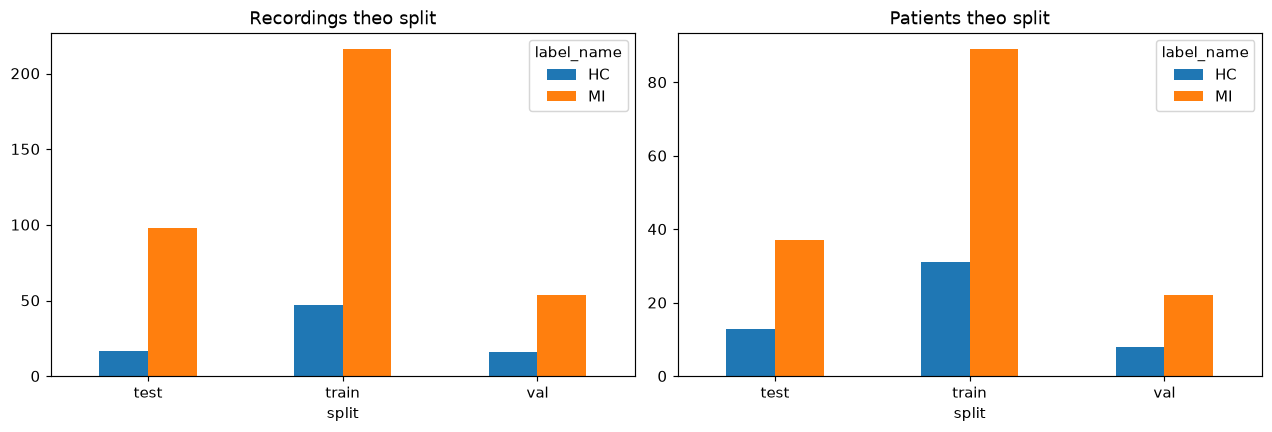

Records: 448 | Patients: 200 | No patient leakage: OK


In [7]:
display(CX_SPLIT.head(8))
display(CX_SPLIT.groupby(["split","label_name"]).agg(records=("record_id","size"),patients=("patient_id","nunique")).reset_index())
fig,ax=plt.subplots(1,2,figsize=(12,4),layout="constrained")
pd.crosstab(CX_SPLIT.split,CX_SPLIT.label_name).plot.bar(ax=ax[0],rot=0,title="Recordings theo split")
CX_SPLIT.drop_duplicates("patient_id").groupby(["split","label_name"]).size().unstack(fill_value=0).plot.bar(ax=ax[1],rot=0,title="Patients theo split")
cx_show(fig,"input_split_distribution")
print("Records:",len(CX_SPLIT),"| Patients:",CX_SPLIT.patient_id.nunique(),"| No patient leakage: OK")

## 4. Đọc header và raw Frank XYZ của một record

Input: CX_DEMO_ID (record base không đuôi). load_xyz dùng WFDB để tìm đúng Frank X/Y/Z, chỉ đọc ba kênh này ở đơn vị mV; không dùng ECG II để tìm QRS và không biến đổi ECG 12 lead thành Frank. .hea tham chiếu các file signal; không tự đọc .xyz như CSV.

Output: raw XYZ (N×3), fs, units/channel metadata, diagnosis chỉ để hiển thị. Time ở hình này là giây tính từ đầu recording; các bước median về sau dùng ms tương đối với anchor QRS = 0. Đây là hai hệ thời gian khác nhau.

,record_id,fs_hz,samples,loaded_seconds,full_seconds,channels,diagnosis
0,patient104/s0306lre,1000.0,30000,30.0,115.2,"vx, vy, vz",Healthy control


,Frank X (mV),Frank Y (mV),Frank Z (mV)
0,-0.3415,-0.6980,0.0095
1,-0.3380,-0.6985,0.0095
2,-0.3370,-0.6960,0.0065
3,-0.3360,-0.6940,0.0075
4,-0.3355,-0.6925,0.0085
5,-0.3360,-0.6975,0.0030
6,-0.3345,-0.6975,0.0000
7,-0.3350,-0.6880,0.0045
8,-0.3355,-0.6875,0.0080
9,-0.3345,-0.6870,0.0080


s0306lre 15 1000 115200
s0306lre.dat 16 2000 16 0 62 15467 0 i
s0306lre.dat 16 2000 16 0 -2297 -30341 0 ii
s0306lre.dat 16 2000 16 0 -2359 10974 0 iii
s0306lre.dat 16 2000 16 0 1117 -30040 0 avr
s0306lre.dat 16 2000 16 0 1211 30813 0 avl
s0306lre.dat 16 2000 16 0 -2328 -9810 0 avf
s0306lre.dat 16 2000 16 0 332 -501 0 v1
s0306lre.dat 16 2000 16 0 516 -9601 0 v2
s0306lre.dat 16 2000 16 0 1146 11360 0 v3
s0306lre.dat 16 2000 16 0 258 -32228 0 v4
s0306lre.dat 16 2000 16 0 -765 23180 0 v5
s0306lre.dat 16 2000 16 0 24 -1985 0 v6
s0306lre.xyz 16 2000 16 0 -683 -12818 0 vx
s0306lre.xyz 16 2000 16 0 -1396 18309 0 vy
s0306lre.xyz 16 2000 16 0 19 -28760 0 vz

# age: 58
# sex: male
# ECG date: 13/07/1992

# Diagnose:
# Reason for admission: Healthy control
# Acute infarction (localization): no
# Former infarction (localization): no
# Additional diagnoses: no
# Smoker: unknown
# Number of coronary vessels involved: unknown
# Infarction date (acute): n/a
# Previous infarction (1) date: n/a
# Previou

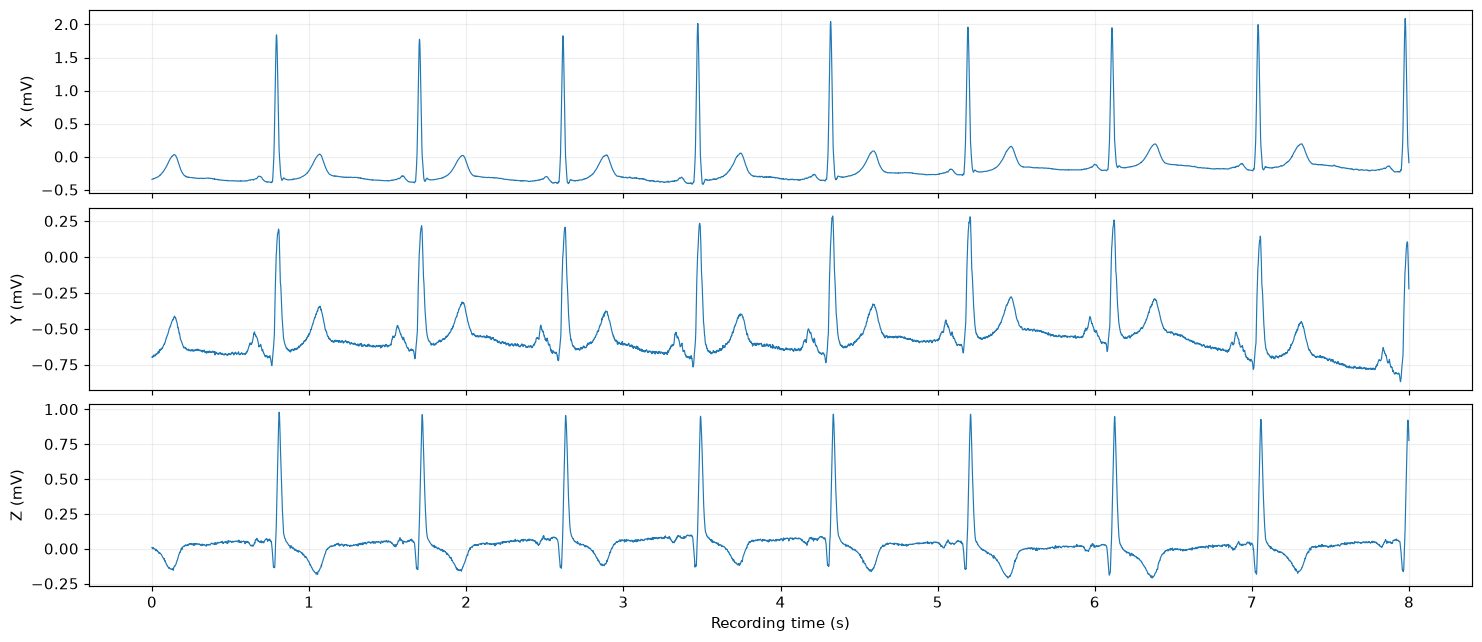

In [8]:
cx_raw_started=time.perf_counter()
cx_raw=load_xyz(CX_DATA_ROOT/CX_DEMO_ID,CX_V1_CFG.seconds)
cx_raw_seconds=time.perf_counter()-cx_raw_started
cx_fs=cx_raw["fs"];cx_raw_xyz=cx_raw["xyz"]
display(pd.DataFrame([dict(record_id=CX_DEMO_ID,fs_hz=cx_fs,samples=len(cx_raw_xyz),
    loaded_seconds=len(cx_raw_xyz)/cx_fs,full_seconds=cx_raw["header"].sig_len/cx_fs,
    channels=", ".join(cx_raw["channels"]),diagnosis=cx_raw["diagnosis"])]))
display(pd.DataFrame(cx_raw_xyz[:10],columns=["Frank X (mV)","Frank Y (mV)","Frank Z (mV)"]))
print((CX_DATA_ROOT/CX_DEMO_ID).with_suffix(".hea").read_text(encoding="latin-1")[:1800])
n=min(len(cx_raw_xyz),int(8*cx_fs)); t=np.arange(n)/cx_fs
fig,ax=plt.subplots(3,1,figsize=(14,6),sharex=True,layout="constrained")
for j in range(3): ax[j].plot(t,cx_raw_xyz[:n,j],lw=.8);ax[j].set_ylabel("XYZ"[j]+" (mV)");ax[j].grid(alpha=.2)
ax[-1].set_xlabel("Recording time (s)");cx_show(fig,"raw_XYZ")

## 5. QC tín hiệu trước lọc — nhìn lỗi, giữ hình thái bệnh lý

Input raw XYZ. Output input-quality masks cho invalid/saturation/dropout/spike/motion-suspect và thống kê RMS. Flags là heuristic; ST hoặc T khác hình thái do MI không tự động bị coi là nhiễu. load_xyz từ chối NaN/Inf thay vì thay bằng 0.

Hình trên là raw; bảng này cho biết các đoạn nào có dấu hiệu lỗi. Nếu có ít dữ liệu, tạo median có thể thất bại và record phải được giữ trong error table.

In [9]:
cx_quality=assess_input_quality(cx_raw_xyz,cx_fs,CX_V1_CFG)
cx_masks={k:np.asarray(cx_quality.get(k,np.zeros(len(cx_raw_xyz),bool)),bool) for k in ("invalid_mask","spike_mask","dropout_mask","saturation_mask","motion_suspect_mask")}
cx_masks["qc_any_mask"]=np.logical_or.reduce(list(cx_masks.values()))
display(pd.DataFrame([dict(mask=k,samples=int(v.sum()),percent=100*float(v.mean())) for k,v in cx_masks.items()]))
display(pd.DataFrame({"axis":list("XYZ"),"RMS_mV":cx_quality.get("rms_mV",np.full(3,np.nan)),
    "baseline_center_range_mV":cx_quality.get("baseline_center_range_mV",np.full(3,np.nan))}))
print("Input flags:",cx_quality["flags"])

,mask,samples,percent
0,invalid_mask,0,0.0
1,spike_mask,0,0.0
2,dropout_mask,0,0.0
3,saturation_mask,0,0.0
4,motion_suspect_mask,0,0.0
5,qc_any_mask,0,0.0


,axis,RMS_mV,baseline_center_range_mV
0,X,0.477922,0.53025
1,Y,1.384044,1.36600
2,Z,0.199641,0.30250


Input flags: []


## 6. Tiền xử lý: morphology và detection là hai nhánh

Input raw → morphology FIR giữ băng thông, notch auto theo evidence; detection band-pass dùng tìm nhịp. Giữ cấu hình V1 để thay đổi T là yếu tố so sánh duy nhất. Không dùng detection signal để tính loop/features.

Output hai mảng cùng N×3 và diagnostics. Overlay giúp thấy ảnh hưởng lọc; RMS difference là lượng tín hiệu bị thay đổi, không phải noise-removal accuracy. PSD cho thấy năng lượng theo tần số; ST/T và drift có thể cùng nằm tần số thấp.

morphology_mode                                                    fir
notch_applied                                                    False
notch_channels                                                      []
powerline_status                                    noise_not_detected
notch_reason         Auto chỉ lọc từng trục có bằng chứng đủ theo h...
rms_difference_uV    [1.350562780571581, 1.8280378118150808, 1.4954...
warnings             [Các ngưỡng PSD/persistence/quiet là heuristic...
Name: preprocessing, dtype: object

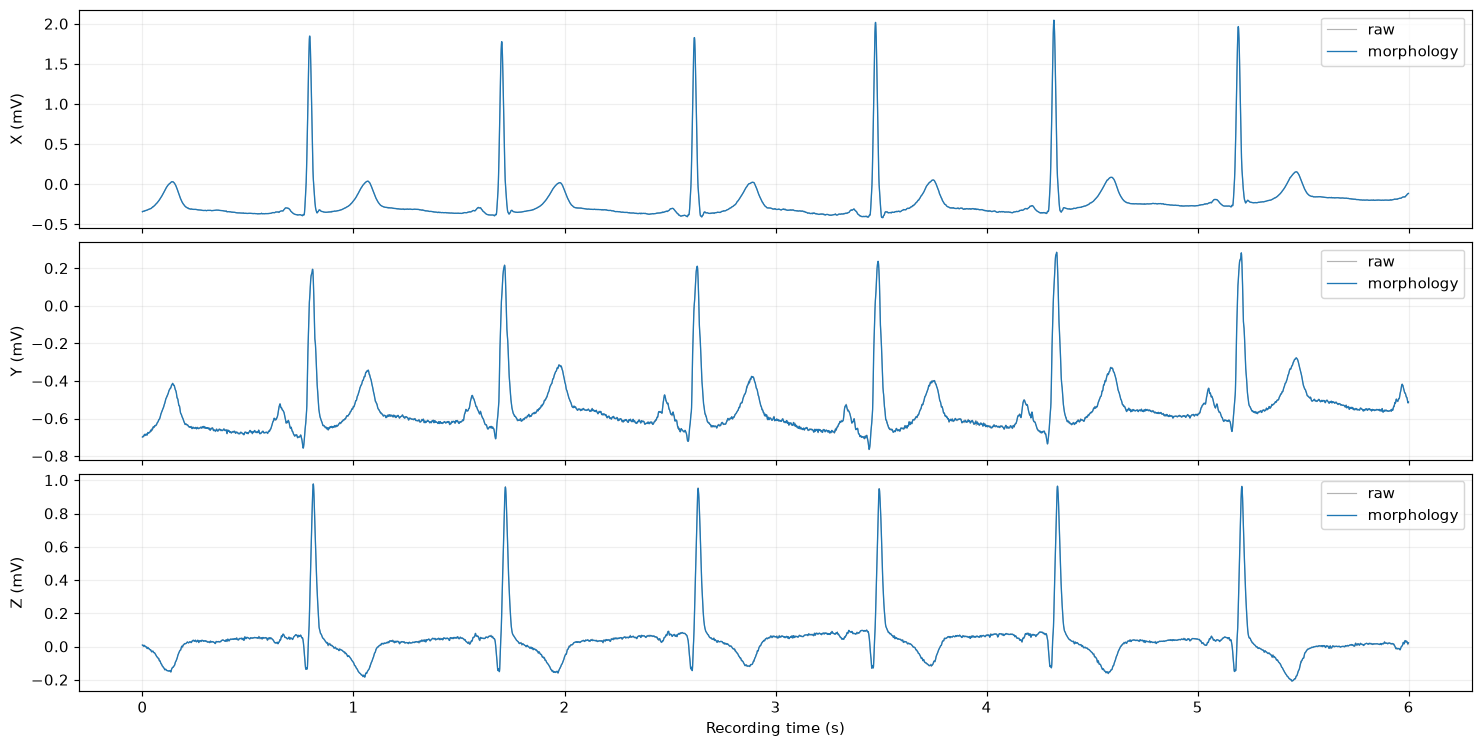

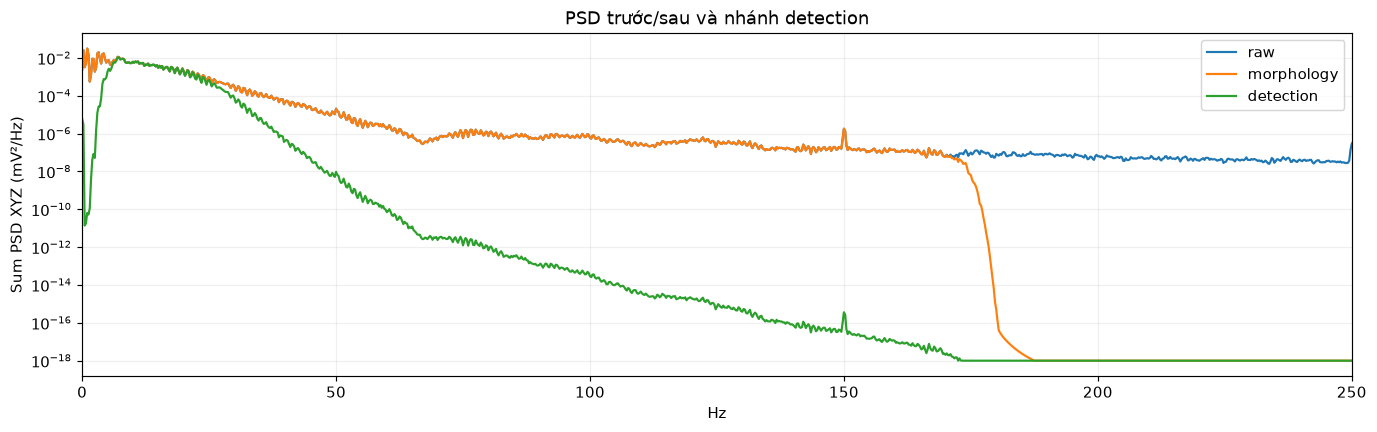

In [10]:
cx_started=time.perf_counter()
cx_morph,cx_detection,cx_prep=preprocess_xyz(cx_raw_xyz,cx_fs,CX_V1_CFG,return_diagnostics=True)
cx_preprocess_seconds=time.perf_counter()-cx_started
display(pd.Series({k:cx_prep.get(k) for k in ("morphology_mode","notch_applied","notch_channels",
    "powerline_status","notch_reason","rms_difference_uV","warnings")},name="preprocessing"))
n=min(len(cx_raw_xyz),int(6*cx_fs));t=np.arange(n)/cx_fs
fig,ax=plt.subplots(3,1,figsize=(14,7),sharex=True,layout="constrained")
for j in range(3):
    ax[j].plot(t,cx_raw_xyz[:n,j],color="0.7",lw=.8,label="raw")
    ax[j].plot(t,cx_morph[:n,j],lw=.9,label="morphology")
    ax[j].set_ylabel("XYZ"[j]+" (mV)");ax[j].legend();ax[j].grid(alpha=.2)
ax[-1].set_xlabel("Recording time (s)");cx_show(fig,"raw_vs_morphology")
fig,ax=plt.subplots(figsize=(13,4),layout="constrained")
for a,name in ((cx_raw_xyz,"raw"),(cx_morph,"morphology"),(cx_detection,"detection")):
    f,p=welch_xyz(a,cx_fs,CX_V1_CFG);ax.semilogy(f,np.maximum(p.sum(axis=1),1e-18),label=name)
ax.set(xlim=(0,min(250,cx_fs/2)),xlabel="Hz",ylabel="Sum PSD XYZ (mV²/Hz)",title="PSD trước/sau và nhánh detection")
ax.legend();ax.grid(alpha=.2);cx_show(fig,"preprocessing_PSD")

## 7. Envelope và QRS anchors trực tiếp từ VCG

Input detection XYZ. Detector dùng RMS tổng bình phương, tích phân cửa sổ cấu hình (mặc định 80 ms), ngưỡng thích nghi và refractory. Tinh chỉnh anchor trên morphology magnitude; anchor là mốc QRS VCG, không gọi là R peak ground truth của ECG II.

Output anchors (sample raw), envelope/threshold và RR. Hình đầu xem đếm nhịp/false candidates; RR plot/histogram hỗ trợ tìm missed beat/ectopy, chưa thay thế QRS reference annotations.

,anchors,RR_median_ms,HR_from_median_RR,RR_min_ms,RR_max_ms,flags
0,31,956.0,62.761506,845.0,1042.0,


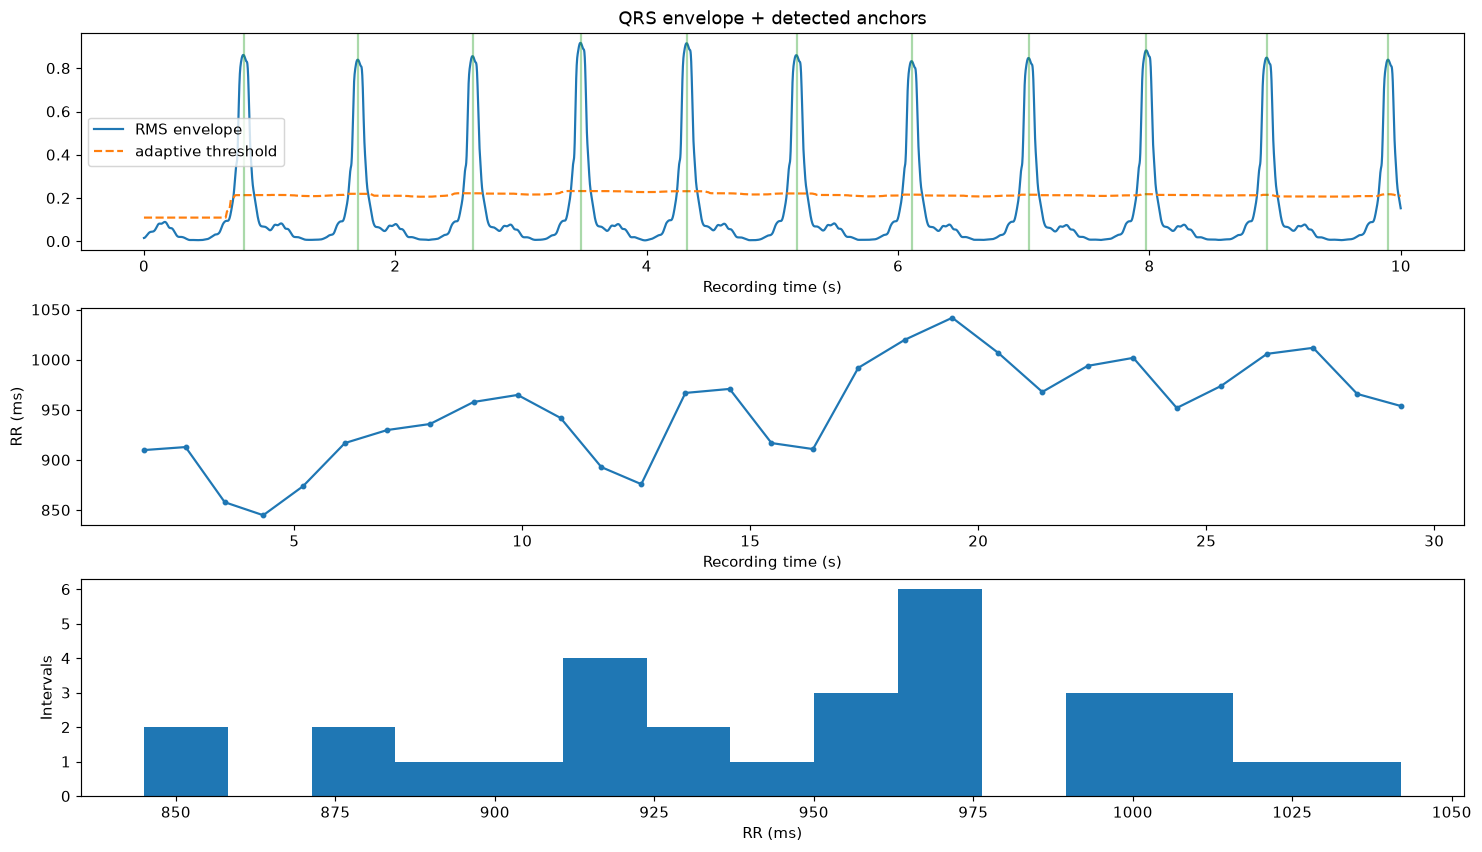

In [11]:
cx_started=time.perf_counter()
cx_detector=detect_qrs_anchors(cx_morph,cx_detection,cx_fs,CX_V1_CFG)
cx_detection_seconds=time.perf_counter()-cx_started
anchors=cx_detector["anchors"];rr=cx_detector["rr"]
display(pd.DataFrame([dict(anchors=len(anchors),RR_median_ms=np.median(rr)*1000,
    HR_from_median_RR=60/np.median(rr),RR_min_ms=rr.min()*1000,RR_max_ms=rr.max()*1000,
    flags=";".join(cx_detector["flags"]))]))
fig,ax=plt.subplots(3,1,figsize=(14,8),layout="constrained")
n=min(len(cx_morph),int(10*cx_fs));t=np.arange(n)/cx_fs
ax[0].plot(t,cx_detector["envelope"][:n],label="RMS envelope")
ax[0].plot(t,cx_detector["threshold"][:n],ls="--",label="adaptive threshold")
for p in anchors[anchors<n]: ax[0].axvline(p/cx_fs,color="tab:green",alpha=.4)
ax[0].set(xlabel="Recording time (s)",title="QRS envelope + detected anchors");ax[0].legend()
ax[1].plot(anchors[1:]/cx_fs,rr*1000,"o-",ms=3);ax[1].set(xlabel="Recording time (s)",ylabel="RR (ms)")
ax[2].hist(rr*1000,bins=15);ax[2].set(xlabel="RR (ms)",ylabel="Intervals")
cx_show(fig,"QRS_anchors_RR")

## 8. Chọn beat, trừ baseline PQ, tạo median

Input morphology + anchors + input QC. Cửa sổ beat phụ thuộc median RR. Loại beat không đủ cửa sổ, RR cực khác hoặc lỗi dữ liệu; giữ hình thái khác kèm cờ review. PQ của từng beat là vùng ít biến thiên, không phải annotation PQ chuẩn.

Output beats đã căn baseline, beat_qc (lý do giữ/loại), median XYZ và PQ của median. Không co giãn thời gian nên velocity giữ đơn vị mV/s. Dải xám là nhiều beats, đường đậm median; nếu tách hai cụm hình thái thì đọc flags, không chỉ nhìn median trơn.

,sample,reason,included,correlation,morphology_status,pq_warning,pq_on,pq_off,pq_mean_speed_mV_s,pq_radius95_mV
0,793,edge,False,NaN,not_assessed,,NaN,NaN,NaN,NaN
1,1703,used,True,0.999061,similar,,74.0,99.0,1.771363,0.009946
2,2616,used,True,0.998559,similar,,60.0,85.0,1.446903,0.009397
3,3474,used,True,0.998934,similar,,62.0,87.0,1.760141,0.010622
4,4319,used,True,0.999071,similar,,60.0,85.0,1.408276,0.008395
5,5193,used,True,0.998249,similar,,61.0,86.0,1.027742,0.005838
6,6110,used,True,0.998015,similar,,60.0,85.0,0.839499,0.004557
7,7040,used,True,0.996940,similar,,60.0,85.0,1.517332,0.010385
8,7976,used,True,0.998910,similar,,64.0,89.0,1.467081,0.005844
9,8934,used,True,0.999305,similar,,60.0,85.0,1.443702,0.009217


,,beats
included,reason,
False,edge,2
True,used,29


used: 29 excluded: 2 PQ slice: (60, 85) flags: []


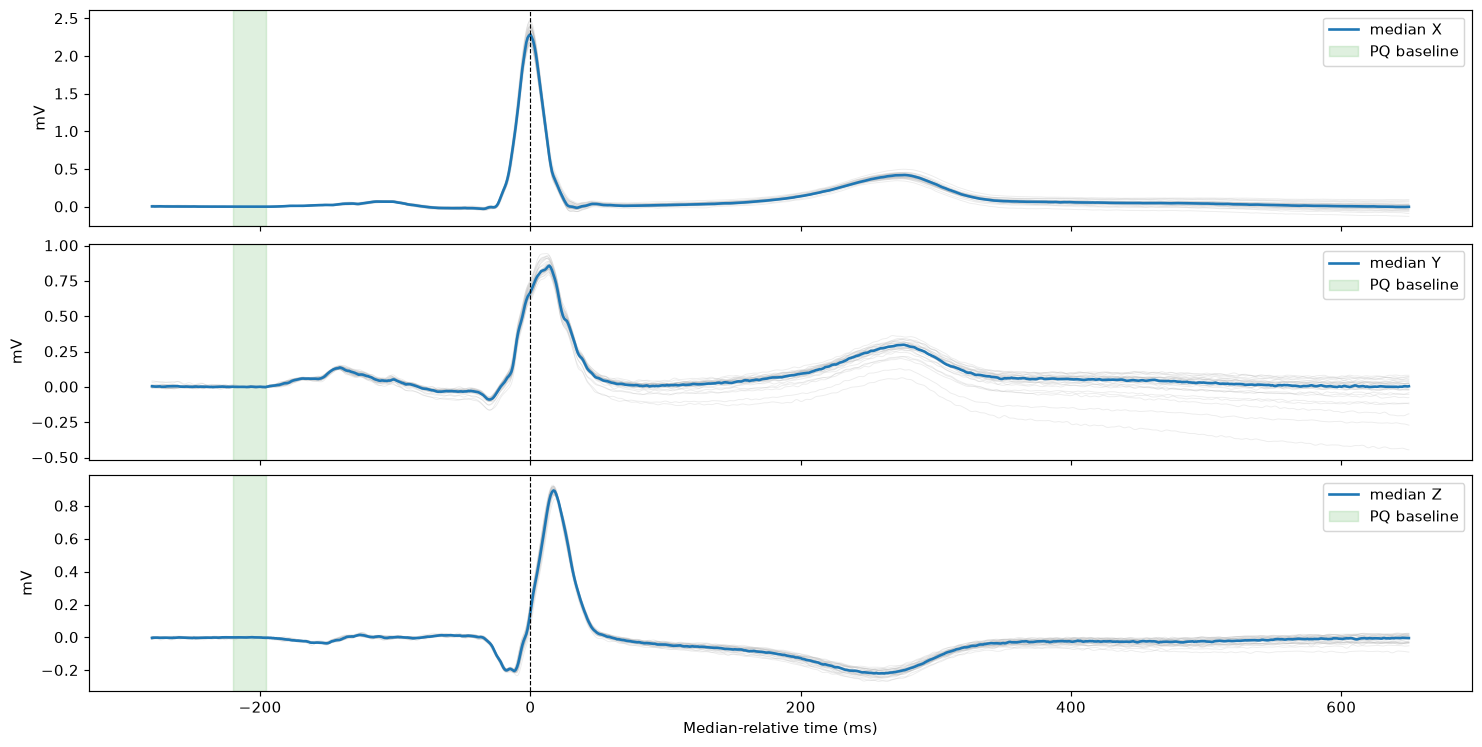

In [12]:
cx_started=time.perf_counter()
cx_rep=representative_beat(cx_morph,anchors,cx_fs,CX_V1_CFG,quality=cx_prep["input_quality"])
cx_rep_seconds=time.perf_counter()-cx_started
display(cx_rep["beat_qc"])
display(cx_rep["beat_qc"].groupby(["included","reason"],dropna=False).size().rename("beats").to_frame())
print("used:",cx_rep["n_used"],"excluded:",cx_rep["n_excluded"],"PQ slice:",cx_rep["pq"],"flags:",cx_rep["quality_flags"])
fig,ax=plt.subplots(3,1,figsize=(14,7),sharex=True,layout="constrained")
for j in range(3):
    for beat in cx_rep["beats"]:ax[j].plot(cx_rep["time_ms"],beat[:,j],color="0.7",alpha=.25,lw=.6)
    ax[j].plot(cx_rep["time_ms"],cx_rep["xyz"][:,j],lw=1.8,label="median "+"XYZ"[j])
    pq0,pq1=cx_rep["pq"];ax[j].axvspan(cx_rep["time_ms"][pq0],cx_rep["time_ms"][pq1-1],color="tab:green",alpha=.15,label="PQ baseline")
    ax[j].axvline(0,color="black",ls="--",lw=.8);ax[j].set_ylabel("mV");ax[j].legend()
ax[-1].set_xlabel("Median-relative time (ms)");cx_show(fig,"median_beats_PQ")
common_flags=sorted(set(cx_detector["flags"]+cx_rep["quality_flags"]+cx_prep.get("warnings",[])))
if cx_rep["n_used"]<5: common_flags.append("few_representative_beats")
if cx_rep["n_excluded"]/len(anchors)>.4: common_flags.append("many_excluded_beats")
cx_demo=dict(record_id=CX_DEMO_ID,raw=cx_raw,fs=cx_fs,morph=cx_morph,detection=cx_detection,
    preprocessing=cx_prep,detector=cx_detector,rep=cx_rep,common_flags=sorted(set(common_flags)),
    shared_seconds=cx_raw_seconds+cx_preprocess_seconds+cx_detection_seconds+cx_rep_seconds)
assert np.array_equal(cx_rep["time_ms"],(np.arange(len(cx_rep["xyz"]))-cx_rep["anchor"])*1000/cx_fs)

## 9. QRS boundaries cố định và chạy các candidate

Input cùng median và RR. V1 tìm QRS bằng tốc độ spatial_speed và đoạn yên quanh cụm hoạt động. Cùng QRS-on/QRS-off được cấp cho V2/C/V3; V1 T marks chỉ được dùng trong chính nhánh V1 và consensus, không được đưa vào V2.

Cell này tính và giữ toàn bộ trace của ba candidate một lần để các cell 10–14 soi chi tiết cùng snapshot, không lặp lại tính toán khác cấu hình. Bảng QRS kiểm tra duration/anchor; không có QRS reference nên chưa báo sensitivity của detector.

,boundary,sample,ms
0,qrs_on,249,-31.0
1,qrs_off,328,48.0
2,t_on,460,180.0
3,t_peak,553,273.0
4,t_off,609,329.0


,method,native_status,algorithm_seconds,flags
0,V1,detected,0.005464,
1,V2,detected,0.103060,
2,C,detected,0.001192,


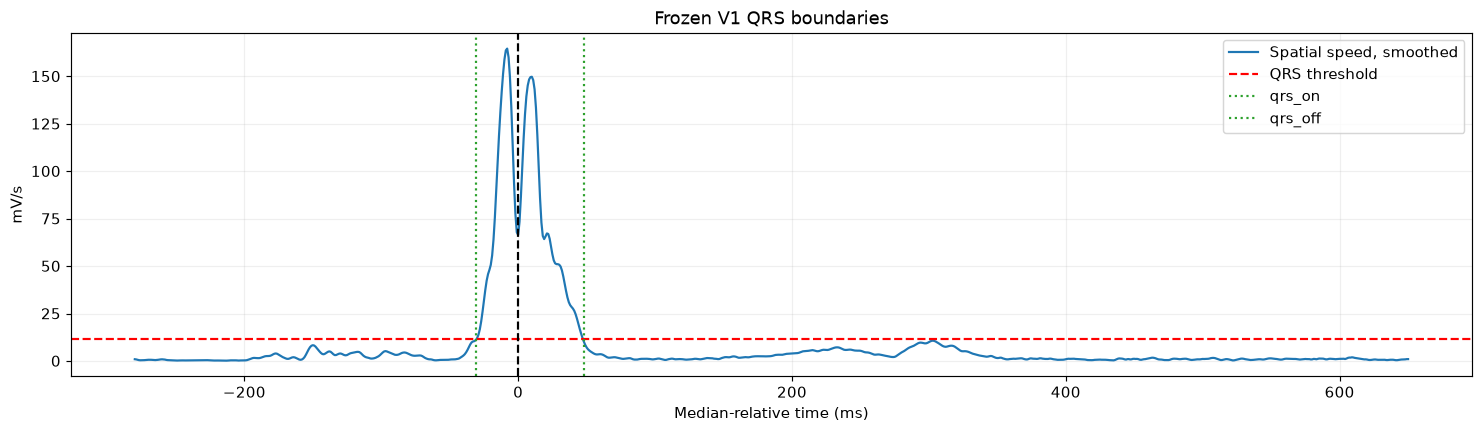

In [13]:
cx_demo_results=cx_candidates(cx_demo)
cx_qtrace=cx_demo_results["V1"]["trace"]
display(pd.DataFrame([dict(boundary=k,sample=cx_qtrace[k],ms=cx_ms(cx_qtrace[k],cx_demo))
    for k in ("qrs_on","qrs_off","t_on","t_peak","t_off")]))
display(pd.DataFrame([dict(method=m,native_status=b["status"],algorithm_seconds=b["algorithm_seconds"],
    flags=";".join(b["flags"])) for m,b in cx_demo_results.items()]))
fig,ax=plt.subplots(figsize=(14,4),layout="constrained")
ax.plot(cx_rep["time_ms"],cx_qtrace["smooth_speed"],label="Spatial speed, smoothed")
ax.axhline(cx_qtrace["q_threshold"],color="red",ls="--",label="QRS threshold")
for key in ("qrs_on","qrs_off"):
    if cx_index(cx_qtrace[key],len(cx_rep["xyz"])):ax.axvline(cx_ms(cx_qtrace[key],cx_demo),color="tab:green",ls=":",label=key)
ax.axvline(0,color="black",ls="--");ax.set(xlabel="Median-relative time (ms)",ylabel="mV/s",title="Frozen V1 QRS boundaries")
ax.legend();ax.grid(alpha=.2);cx_show(fig,"QRS_boundaries_speed")

## 10. V1 — T-on tiếp tuyến ST, T-off tiếp tuyến TP và kiểm tra threshold

Input magnitude median trong cửa sổ sau QRS; ST/TP làm mức tham chiếu hai tiếp tuyến. Output t_on/t_off và cả các candidate tangent/threshold để thấy lý do bất đồng. Nếu TP không rõ hoặc không đủ slope, giữ unresolved/review.

Hình 3 tầng dùng đúng hàm plot_delineation của V1: XYZ + PQ/TP, tốc độ QRS, magnitude T + tiếp tuyến/threshold. Đối chiếu các bước 12–16 trong notebook 05. Không coi PQ=TP mặc định; ST khác nền có thể do bệnh lý.

t_method           tangent_on+tangent_end
t_search                       (348, 880)
st_level                          0.03476
t_end_baseline                   0.077967
tp                             (692, 717)
t_threshold                      0.044855
t_end_threshold                  0.115939
t_rise_index                          509
t_fall_index                          581
t_tangent_on                          460
t_threshold_on                        372
t_tangent_off                         609
t_threshold_off                       622
flags                                  []
dtype: object

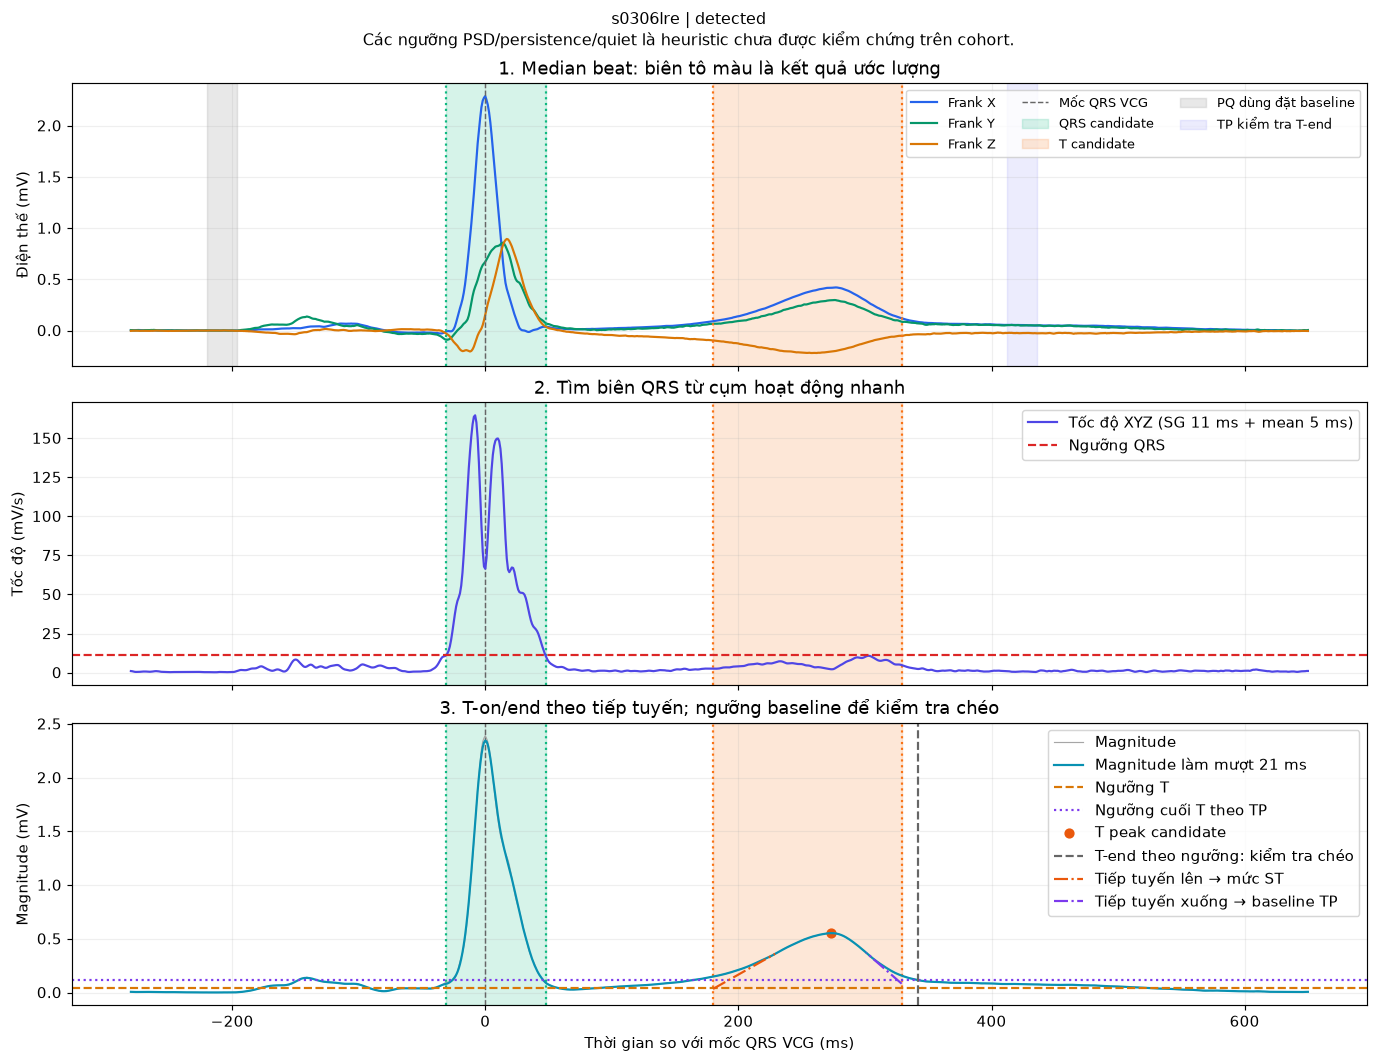

In [14]:
display(pd.Series({k:cx_qtrace.get(k) for k in (
    "t_method","t_search","st_level","t_end_baseline","tp","t_threshold","t_end_threshold",
    "t_rise_index","t_fall_index","t_tangent_on","t_threshold_on","t_tangent_off","t_threshold_off","flags")}))
cx_v1_plot=dict(rep=cx_rep,boundaries=cx_qtrace,raw=cx_raw,
    flags=cx_demo["common_flags"]+cx_qtrace["flags"],status=cx_demo_results["V1"]["status"])
cx_show(plot_delineation(cx_v1_plot),"V1_tangent_threshold_trace")

## 11. V2 — cửa sổ T và wavelet quadratic-spline scales 3/4/5

Input cùng median, QRS và RR; V2 tự định cửa sổ tìm T theo thuật toán của nó. Cửa sổ V1 và V2 có thể khác: giữ native choices và in ra rõ, không tự đồng nhất search window rồi gọi là cùng phương pháp.

Output wavelet XYZ từng scale, filter delay/alignment, search/rms interval. Wavelet ở đây tạo slope/extrema để delineation; T loop cuối vẫn cắt từ **median XYZ gốc**, không cắt từ wavelet. Các adaptation về fs, RMS trên median hữu hạn và border support được mô tả trong METHOD_REPRODUCTION.

,scale,taps,delay_samples,support_radius_samples,alignment
0,3,152,74.0,65,exact_integer_delay
1,4,216,106.0,97,exact_integer_delay
2,5,344,170.0,161,exact_integer_delay


search_window                                                      [380, 880]
rms_interval                                                       [280, 930]
rms_interval_complete_rr                                                False
rms_note                    Available anchor-to-end median substitutes ful...
selected_scale                                                              4
failure_reason                                                               
review_flags                                                               []
dtype: object

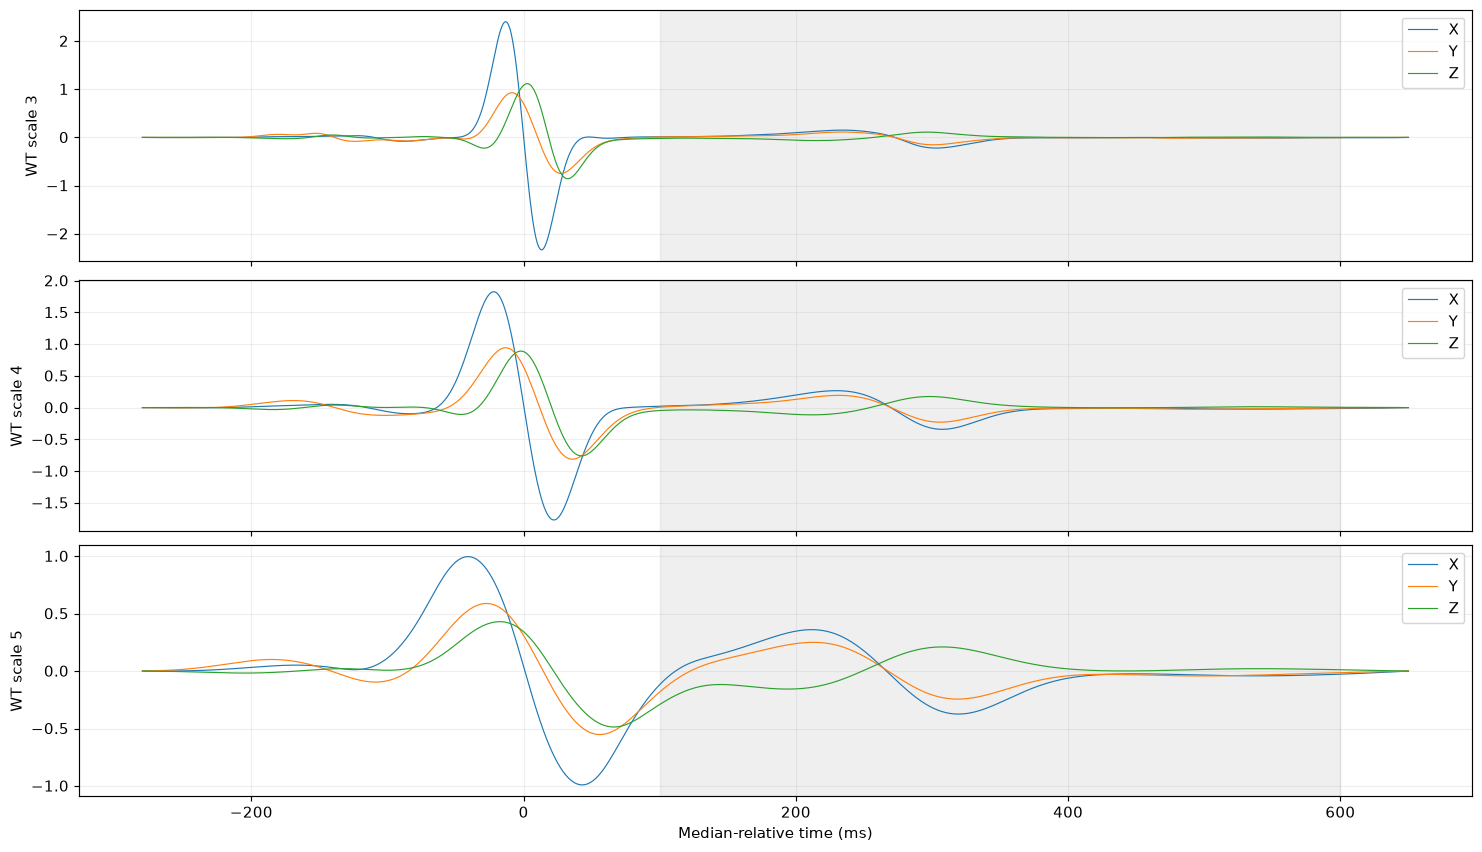

In [15]:
cx_v2_trace=cx_demo_results["V2"]["trace"]
if cx_v2_trace.get("wavelets"):
    display(pd.DataFrame([dict(scale=k,taps=len(v["coefficients"]),delay_samples=v["delay_samples"],
        support_radius_samples=v["support_radius_samples"],alignment=v["alignment"])
        for k,v in cx_v2_trace["filter_bank"].items()]))
    display(pd.Series({k:cx_v2_trace.get(k) for k in ("search_window","rms_interval",
        "rms_interval_complete_rr","rms_note","selected_scale","failure_reason","review_flags")}))
    fig,axes=plt.subplots(3,1,figsize=(14,8),sharex=True,layout="constrained")
    for ax,scale in zip(axes,(3,4,5)):
        for j in range(3):ax.plot(cx_rep["time_ms"],cx_v2_trace["wavelets"][scale][:,j],label="XYZ"[j],lw=.8)
        if cx_v2_trace.get("search_window"):
            a,b=cx_v2_trace["search_window"];ax.axvspan(cx_rep["time_ms"][a],cx_rep["time_ms"][b],color="0.5",alpha=.12)
        ax.set_ylabel(f"WT scale {scale}");ax.legend();ax.grid(alpha=.2)
    axes[-1].set_xlabel("Median-relative time (ms)");cx_show(fig,"V2_wavelet_scales")
else: print("V2 không có wavelet trace:",cx_demo_results["V2"]["flags"])

## 12. V2 — single-lead initialization, TLS riêng onset và offset

Input WT XYZ. Mỗi trục tìm extrema/zero-crossings và morphology. Có single-lead T hợp lệ mới khởi tạo TLS: SVD tìm hướng 3D phù hợp vùng wavelet; nhánh onset và offset có hướng riêng, không dùng chung một hướng cho mọi hình thái.

Output bảng single-lead, history từng vòng, direction, fit quality và derived waveform. Candidate sample của mỗi vòng, vòng được chọn và stop_reason đều được giữ. Dừng thuật toán khác với “đã hội tụ”; nếu dừng do không cải thiện hoặc hết iterations thì xem flags.

,axis,wavelet_scale,wave_detected,morphology_type,t_on_candidate_sample,t_off_candidate_sample,detection_status,failure_reason
0,X,4,True,positive,430,625,detected,
1,Y,4,True,positive,427,623,detected,
2,Z,4,True,negative,402,619,detected,


boundary                                                         t_on
chosen_iteration                                                    2
direction           [0.7873119161421422, 0.5686276251312931, -0.23...
stop_reason            boundary_change_strictly_less_than_two_samples
converged                                                        True
review_flags                                                       []
dtype: object

boundary                                                        t_off
chosen_iteration                                                    1
direction           [0.7716541848719324, 0.5263010554145475, -0.35...
stop_reason                 no_extremum_improvement_previous_retained
converged                                                       False
review_flags                                                       []
dtype: object

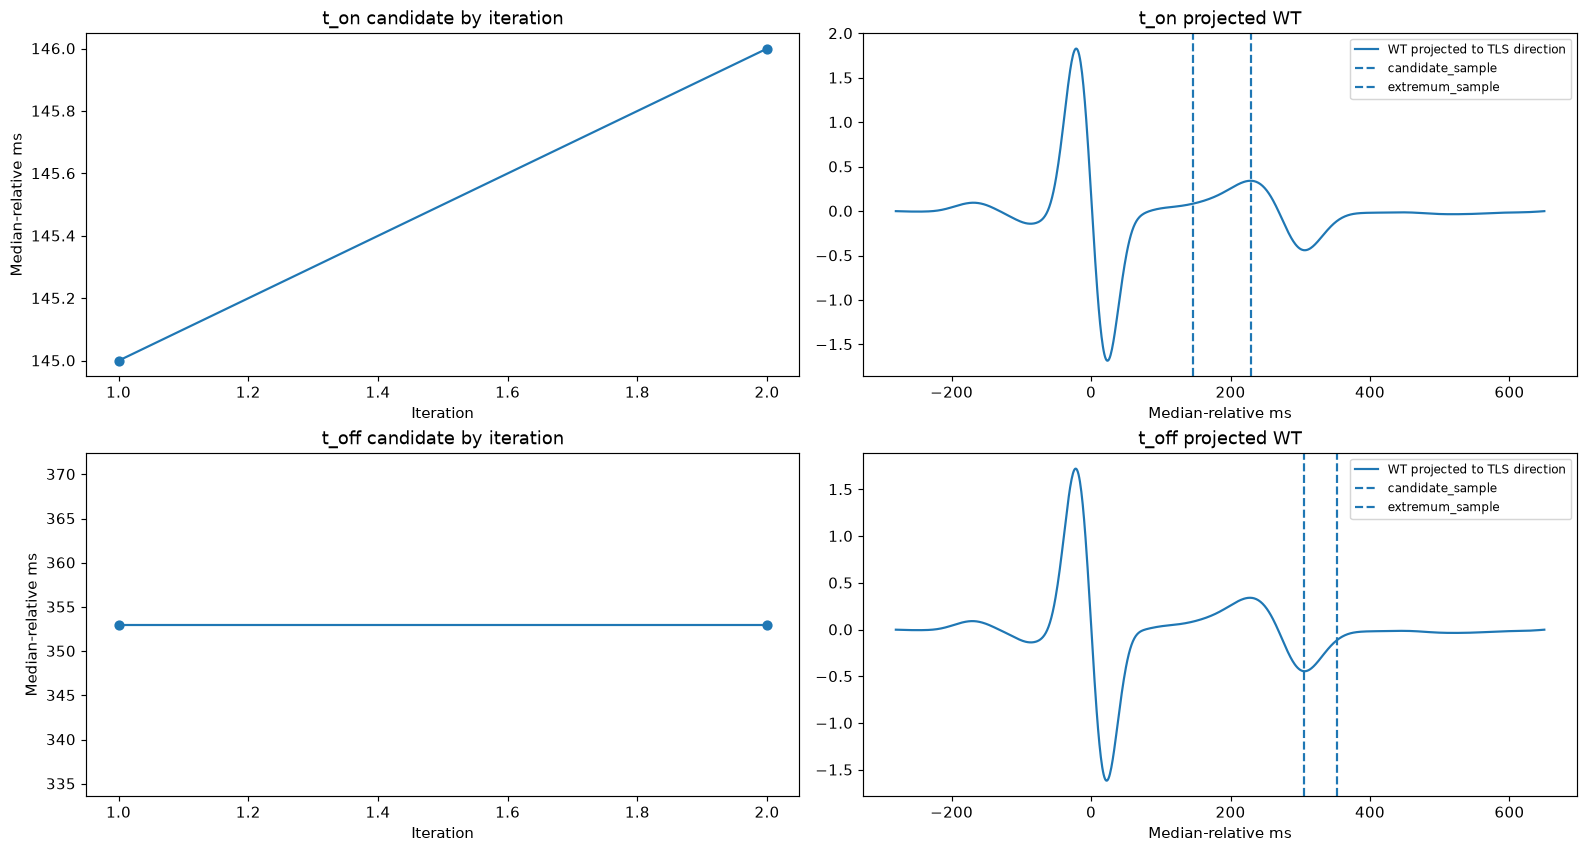

,boundary,iteration,window_start,window_end,status,direction,center,singular_values,fit_quality,orthogonal_residual_rms,accepted,candidate_sample,stop_reason,extremum_sample,extremum_amplitude,morphology_type,derived_index,boundary_threshold
0,t_on,1,380,880,ok,"[0.7716541848719324, 0.5263010554145475, -0.35...","[-0.0018888475982332027, -0.001129719316542131...","[3.93835029517107, 0.5637575635330664, 0.13158...",0.978850,0.025864,True,425,,508,0.341477,positive,0,0.085369
1,t_on,2,364,508,ok,"[0.7873119161421422, 0.5686276251312931, -0.23...","[0.10507505533370928, 0.0690631574036114, -0.0...","[1.2552191191345001, 0.19868820369039134, 0.01...",0.975378,0.016562,True,426,boundary_change_strictly_less_than_two_samples,509,0.342139,positive,1,0.085535
2,t_off,1,380,880,ok,"[0.7716541848719324, 0.5263010554145475, -0.35...","[-0.0018888475982332027, -0.001129719316542131...","[3.93835029517107, 0.5637575635330664, 0.13158...",0.978850,0.025864,True,633,,586,0.444639,positive,0,0.111160
3,t_off,2,586,694,ok,"[0.7816314198780546, 0.514474825900112, -0.352...","[-0.11914799834077462, -0.0754175444362676, 0....","[1.5606347659671673, 0.0469200857542825, 0.021...",0.998900,0.004960,False,633,no_extremum_improvement_previous_retained,586,0.444578,positive,1,0.111144


In [16]:
cx_sl=cx_v2_trace.get("single_leads",[])
if cx_sl:
    slcols=["axis","wavelet_scale","wave_detected","morphology_type","t_on_candidate_sample",
            "t_off_candidate_sample","detection_status","failure_reason"]
    display(pd.DataFrame(cx_sl).reindex(columns=slcols))
cx_history=[]
fig,axes=plt.subplots(2,2,figsize=(15,8),layout="constrained")
for row,boundary in enumerate(("t_on","t_off")):
    branch=cx_v2_trace.get("branches",{}).get(boundary,{})
    for entry in branch.get("history",[]):
        cx_history.append({**{k:v for k,v in entry.items() if k != "wave"}, "boundary":boundary})
    history=branch.get("history",[])
    x=[e["iteration"] for e in history];y=[cx_ms(e.get("candidate_sample"),cx_demo) for e in history]
    axes[row,0].plot(x,y,"o-");axes[row,0].set(title=boundary+" candidate by iteration",xlabel="Iteration",ylabel="Median-relative ms")
    chosen=branch.get("chosen_iteration")
    if chosen:
        entry=history[chosen-1];derived=branch["derived_history"][entry["derived_index"]]
        axes[row,1].plot(cx_rep["time_ms"],derived,label="WT projected to TLS direction")
        for k in ("candidate_sample","extremum_sample"):
            if cx_index(entry.get(k),len(cx_rep["xyz"])):
                axes[row,1].axvline(cx_ms(entry[k],cx_demo),ls="--",label=k)
        axes[row,1].legend(fontsize=8)
        display(pd.Series(dict(boundary=boundary,chosen_iteration=chosen,direction=branch.get("direction"),
            stop_reason=branch.get("stop_reason"),converged=branch.get("converged"),
            review_flags=branch.get("review_flags"))))
    else: axes[row,1].text(.1,.5,"Không có projected boundary; giữ unresolved",transform=axes[row,1].transAxes)
    axes[row,1].set(title=boundary+" projected WT",xlabel="Median-relative ms")
cx_show(fig,"V2_TLS_iterations_projections")
display(pd.DataFrame(cx_history))
CX_RESULTS["demo_V2_TLS_history"]=pd.DataFrame(cx_history)

## 13. C — magnitude/baseline threshold để kiểm tra chéo

Input cùng median và QRS-off. Làm mượt magnitude, tìm peak trong cửa sổ, rồi tìm đoạn đủ yên 20 ms ở hai phía dưới mức baseline + max(3×noise, 8% peak amplitude). Output threshold crossings.

Tên “derivative candidate” ở bản cũ dễ gây hiểu nhầm: nhánh này thực tế dùng magnitude + threshold, không dùng derivative slope để chọn T-on/off. Notebook gọi C/magnitude-threshold cho đúng. Nó không độc lập với V1 vì dùng cùng magnitude/PQ baseline, cần xem option ablation.

status    detected
t_on           372
t_off          801
peaks        [553]
flags           []
dtype: object

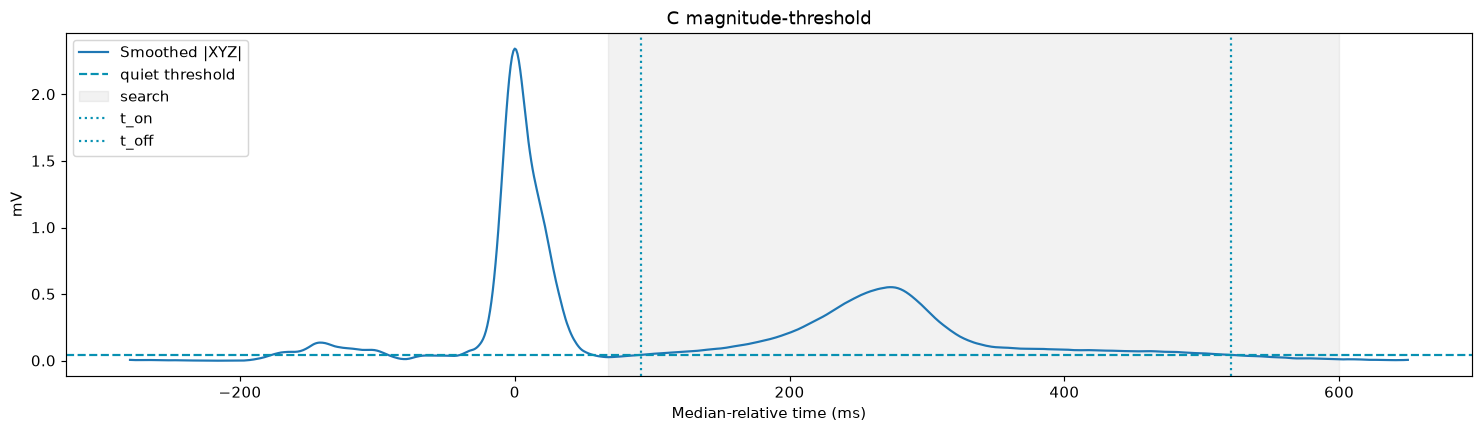

In [17]:
cx_c=cx_demo_results["C"];tr=cx_c["trace"]
display(pd.Series({k:cx_c[k] for k in ("status","t_on","t_off","peaks","flags")}))
if "smooth" in tr:
    fig,ax=plt.subplots(figsize=(14,4),layout="constrained")
    ax.plot(cx_rep["time_ms"],tr["smooth"],label="Smoothed |XYZ|")
    if "threshold" in tr: ax.axhline(tr["threshold"],color=CX_COLORS["C"],ls="--",label="quiet threshold")
    a,b=tr["search"];ax.axvspan(cx_rep["time_ms"][a],cx_rep["time_ms"][b],color="0.5",alpha=.1,label="search")
    for k in ("t_on","t_off"):
        if cx_index(cx_c[k],len(cx_rep["xyz"])):ax.axvline(cx_ms(cx_c[k],cx_demo),color=CX_COLORS["C"],ls=":",label=k)
    ax.set(xlabel="Median-relative time (ms)",ylabel="mV",title="C magnitude-threshold")
    ax.legend();cx_show(fig,"C_threshold_crossings")
else: print("C unresolved trước bước threshold:",cx_c["flags"])

## 14. V3 — consensus của cả cặp biên và bảng phiếu cụ thể

Input candidate V1/V2/C với status, flags, peaks. Chỉ candidate có pair đúng thứ tự mới được bỏ phiếu. Cùng một nhóm phải đồng ý cả hai biên. Hai biên riêng lẻ có phiếu từ hai nhóm khác nhau không đủ để tạo interval được chấp nhận.

Output median onset/offset, voters, std/range (ms), flags. Spread nhỏ không phải độ bất định thống kê hay xác suất đúng; các method có chung giả định có thể cùng sai. Mỗi flags của voter được giữ để accepted screening không che mất ca cần review.

In [18]:
cx_demo_results["V3"]=cx_consensus(cx_demo,cx_demo_results)
cx_cons=cx_demo_results["V3"]
display(pd.Series({k:v for k,v in cx_cons.items() if k!="trace"}))
display(pd.Series(cx_cons["trace"],name="joint consensus diagnostics"))
cx_boundary_table=pd.DataFrame([dict(method=m,native_status=b["status"],valid_pair=cx_order(cx_demo,b),
    T_on_ms=cx_ms(b.get("t_on"),cx_demo),T_off_ms=cx_ms(b.get("t_off"),cx_demo),
    selected_as_voter=m in cx_cons["trace"].get("voters",[]),flags=";".join(b["flags"]))
    for m,b in cx_demo_results.items()])
display(cx_boundary_table)
CX_RESULTS["demo_boundaries"]=cx_boundary_table

method                                          V3
status                                  unresolved
qrs_on                                         249
qrs_off                                        328
t_on                                          None
t_off                                         None
peaks                                           []
flags                [no_joint_boundary_agreement]
algorithm_seconds                         0.000434
dtype: object

usable          [V1, V2, C]
tolerance_ms           25.0
min_votes                 2
Name: joint consensus diagnostics, dtype: object

,method,native_status,valid_pair,T_on_ms,T_off_ms,selected_as_voter,flags
0,V1,detected,True,180.0,329.0,False,
1,V2,detected,True,146.0,353.0,False,
2,C,detected,True,92.0,521.0,False,
3,V3,unresolved,False,NaN,NaN,False,no_joint_boundary_agreement


## 15. Visual tất cả method trên cùng XYZ và cùng trục thời gian

Input cùng median; mỗi hàng là một method với hai đường onset/offset và interval tô màu khi valid. Giữ hàng unresolved để không tạo ấn tượng mọi method đều thành công. Vùng tô chỉ là estimate.

Đối chiếu với hình riêng V1 ở bước 10 và projected WT ở bước 12 để giải thích vì sao mốc đổi. Không dùng đường V3 làm ground truth để chấm V1/V2.

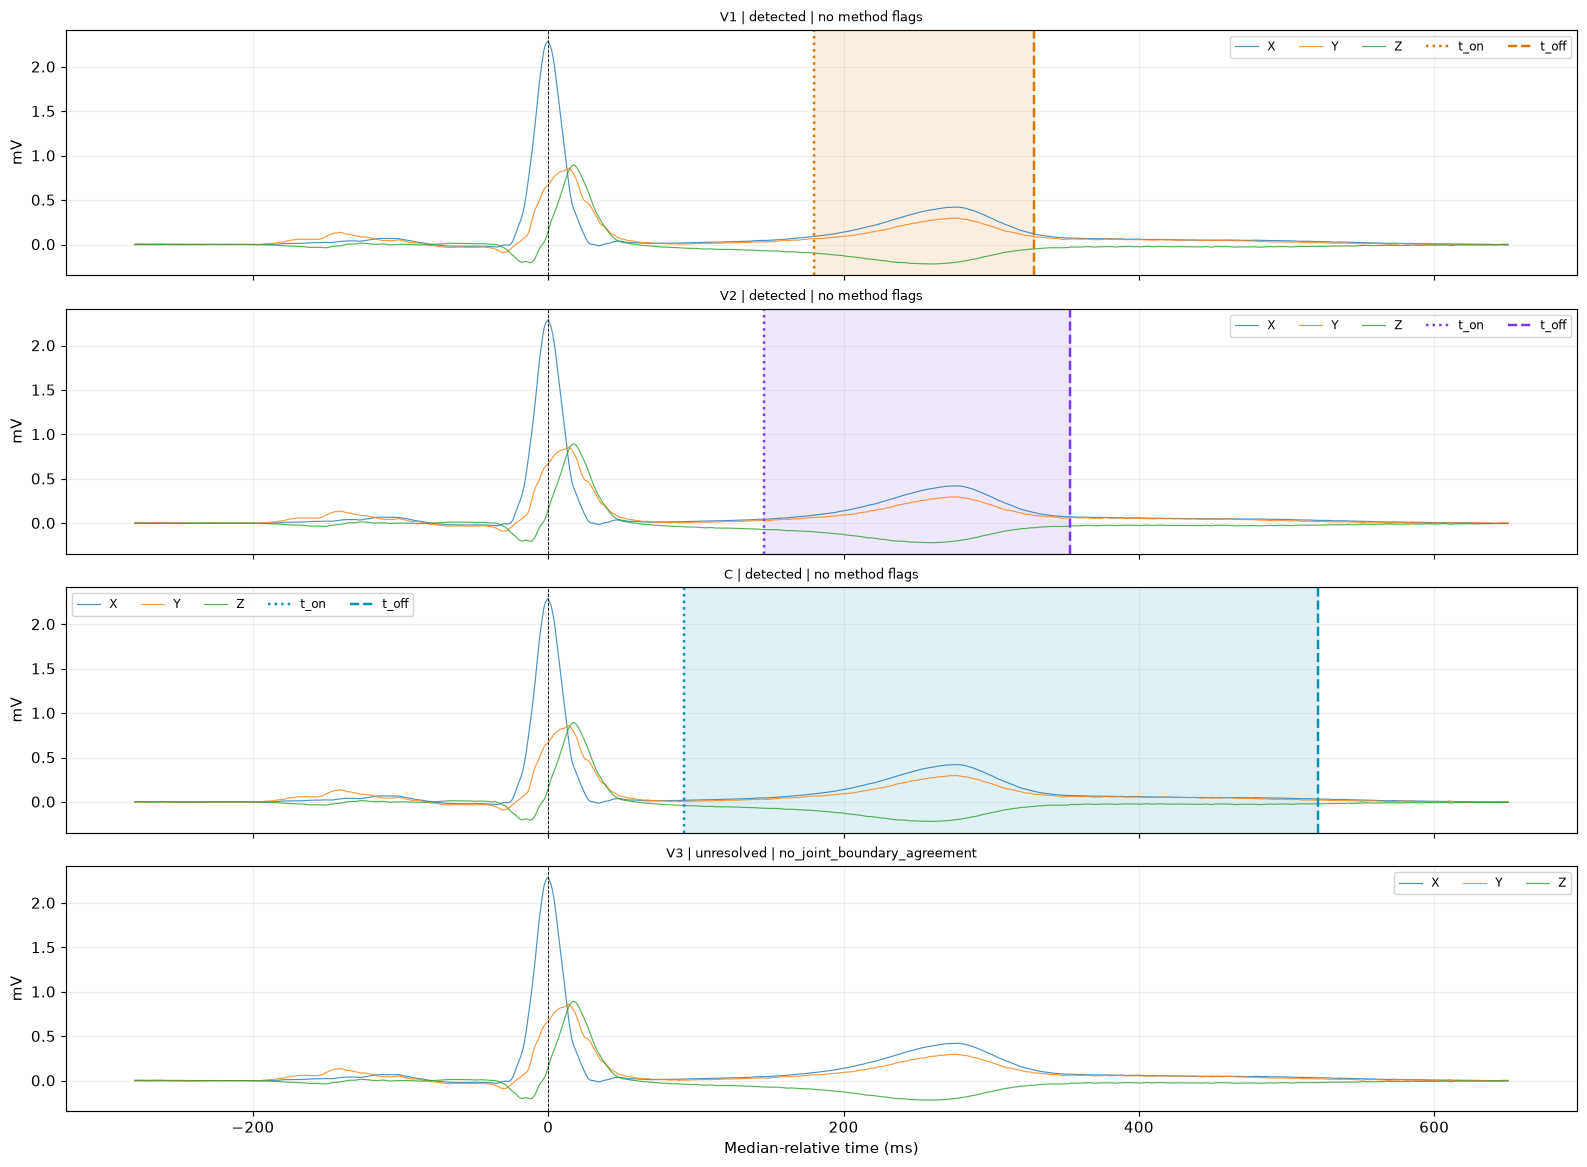

In [19]:
fig,axes=plt.subplots(4,1,figsize=(15,11),sharex=True,sharey=True,layout="constrained")
for ax,(m,b) in zip(axes,cx_demo_results.items()):
    for j in range(3):ax.plot(cx_rep["time_ms"],cx_rep["xyz"][:,j],lw=.8,alpha=.8,label="XYZ"[j])
    for key,style in (("t_on",":"),("t_off","--")):
        if cx_index(b.get(key),len(cx_rep["xyz"])):ax.axvline(cx_ms(b[key],cx_demo),color=CX_COLORS[m],ls=style,lw=1.7,label=key)
    if cx_order(cx_demo,b):ax.axvspan(cx_ms(b["t_on"],cx_demo),cx_ms(b["t_off"],cx_demo),color=CX_COLORS[m],alpha=.12)
    ax.set_title(m+" | "+b["status"]+" | "+("; ".join(b["flags"]) or "no method flags"),fontsize=9)
    ax.axvline(0,color="black",ls="--",lw=.6);ax.set_ylabel("mV");ax.legend(ncol=5,fontsize=8);ax.grid(alpha=.2)
axes[-1].set_xlabel("Median-relative time (ms)");cx_show(fig,"all_methods_same_XYZ")

## 16. Cắt loop thật sự và phân biệt candidate / accepted

Input native-sample endpoints. Slice dùng XYZ[on:off+1], gồm cả hai endpoint. Duration dùng (off−on)/fs, còn số samples là off−on+1 — không đánh đồng hai đại lượng.

Mọi valid candidate được giữ loop để chẩn đoán và so sánh; accepted là cờ riêng. Với V3 needs_review/unresolved, loop có thể được xem như candidate nếu order hợp lệ, nhưng **accepted T features bị mask ở bảng xuất riêng**, không tính thành accepted coverage.

,method,native_status,valid_pair,accepted,duration_ms,flags
0,V1,detected,True,True,149.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
1,V2,detected,True,True,207.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
2,C,detected,True,False,429.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
3,V3,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...


,method,QRS_samples,T_samples,accepted
0,V1,80,150,True
1,V2,80,208,True
2,C,80,430,False
3,V3,80,0,False


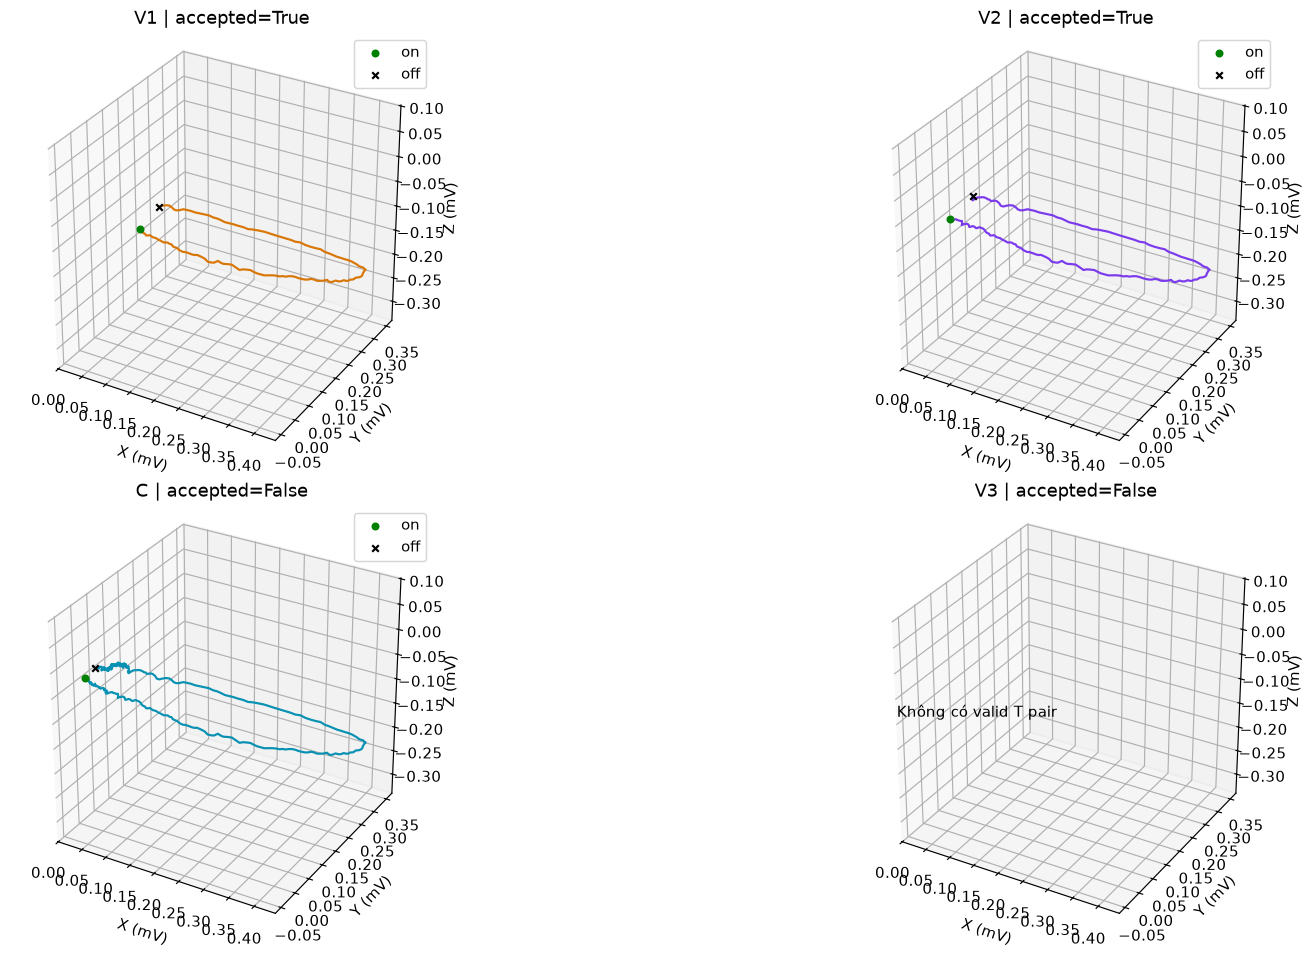

In [20]:
cx_demo_assets={};cx_feature_rows=[]
for m,b in cx_demo_results.items():
    row,asset=cx_evaluate(cx_demo,b);cx_demo_assets[m]=asset;cx_feature_rows.append(row)
display(pd.DataFrame(cx_feature_rows)[["method","native_status","valid_pair","accepted","duration_ms","flags"]])
display(pd.DataFrame([dict(method=m,QRS_samples=0 if a["qrs_loop"] is None else len(a["qrs_loop"]),
    T_samples=0 if a["t_loop"] is None else len(a["t_loop"]),accepted=a["accepted"])
    for m,a in cx_demo_assets.items()]))
fig=plt.figure(figsize=(16,9),layout="constrained")
all_loops=[a["t_loop"] for a in cx_demo_assets.values() if a["t_loop"] is not None]
pts=np.vstack(all_loops) if all_loops else np.zeros((1,3))
mid=(pts.min(axis=0)+pts.max(axis=0))/2;radius=max(np.ptp(pts,axis=0).max()/2,1e-3)*1.1
for pos,(m,a) in enumerate(cx_demo_assets.items(),1):
    ax=fig.add_subplot(2,2,pos,projection="3d");loop=a["t_loop"]
    if loop is not None:
        ax.plot(*loop.T,color=CX_COLORS[m]);ax.scatter(*loop[0],color="green",label="on");ax.scatter(*loop[-1],color="black",marker="x",label="off");ax.legend()
    else: ax.text2D(.1,.5,"Không có valid T pair",transform=ax.transAxes)
    ax.set(xlim=(mid[0]-radius,mid[0]+radius),ylim=(mid[1]-radius,mid[1]+radius),
        zlim=(mid[2]-radius,mid[2]+radius),xlabel="X (mV)",ylabel="Y (mV)",zlabel="Z (mV)",
        title=m+" | accepted="+str(a["accepted"]))
    ax.set_box_aspect((1,1,1))
cx_show(fig,"T_loops_3D_same_limits")

## 17. PCA, mặt phẳng loop và 12 features

Input QRS/T cut và spatial speed tính trên **toàn median trước khi cắt** để giảm edge effects. PCA fit riêng mỗi loop, tính Area bằng shoelace đóng cuối về đầu. QRS Arc là đường mở trong PCA; MaxVec đo theo gốc PQ trong XYZ; velocity mV/s. PCA riêng không dùng để so vị trí tương đối hoặc góc QRS–T.

Output 7 QRS + 5 T features. PCA variance 2D là lượng phương sai được giữ, không là “chất lượng T”. Feature T missing giữ NaN. Các feature QRS phải giống nhau ở mọi method; phần đánh giá cuối assert điều này.

,unit,V1,V2,C,V3
QRS_Arc,mV,5.892343,5.892343,5.892343,5.892343
QRS_Area,mV²,2.076441,2.076441,2.076441,2.076441
QRS_MaxVec,mV,2.391030,2.391030,2.391030,2.391030
QRS_MaxCentroidDistance,mV,1.673200,1.673200,1.673200,1.673200
QRS_MaxVel,mV/s,170.154227,170.154227,170.154227,170.154227
QRS_MeanVel,mV/s,74.685192,74.685192,74.685192,74.685192
QRS_StdVel,mV/s,48.794393,48.794393,48.794393,48.794393
T_MaxVec,mV,0.552880,0.552880,0.552880,NaN
T_Area,mV²,0.027437,0.030707,0.032669,NaN
T_MaxVel,mV/s,11.059858,11.059858,11.059858,NaN


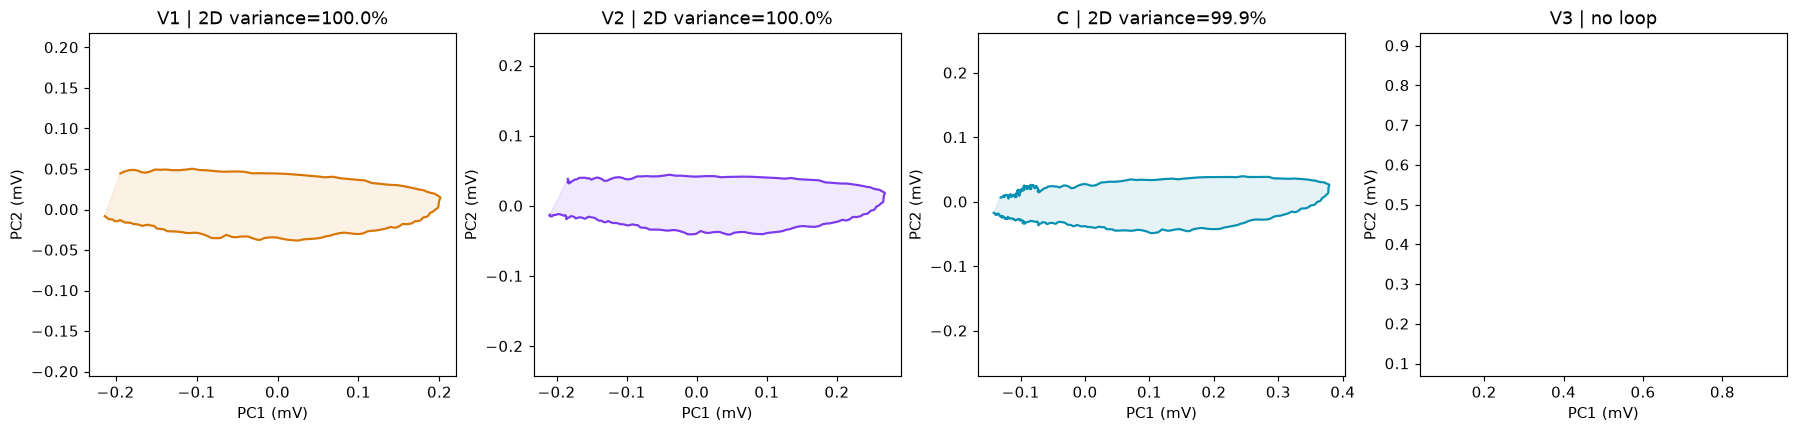

In [21]:
cx_feature_table=pd.DataFrame({m:a["features"] for m,a in cx_demo_assets.items()}).reindex(FEATURE_NAMES)
cx_feature_table.insert(0,"unit",[("mV²" if "Area" in f else "mV/s" if "Vel" in f else "mV") for f in FEATURE_NAMES])
display(cx_feature_table)
fig,axes=plt.subplots(1,4,figsize=(17,4),layout="constrained")
for ax,(m,a) in zip(axes,cx_demo_assets.items()):
    p=project_pca(a["t_loop"])
    if p:
        ax.plot(*p["xy"].T,color=CX_COLORS[m]);ax.fill(*p["xy"].T,color=CX_COLORS[m],alpha=.1)
        ax.set_title(f"{m} | 2D variance={100*p['variance']:.1f}%")
    else: ax.set_title(m+" | no loop")
    ax.set(xlabel="PC1 (mV)",ylabel="PC2 (mV)");ax.set_aspect("equal",adjustable="datalim")
cx_show(fig,"T_PCA_separate_planes")
CX_RESULTS["demo_feature_values"]=cx_feature_table.reset_index(names="feature")

## 18. Đánh giá cùng giao thức và các option

Từ đây dùng nguyên bộ cell shared được thêm vào cuối 05 và 09. Bắt đầu bằng bảng coverage/tất cả ca, sau đó paired comparison, robustness, sensitivity, ablation, provenance, ML tùy chọn và export. Bật cohort ở cell cấu hình đầu rồi Restart & Run All; các hình chi tiết trước đó vẫn dùng demo.

Các phép perturbation mặc định chỉ chạy trên một demo để bạn kiểm tra logic trước. Để suy rộng cohort cần chạy thiết kế nhiều record/patient và giữ đủ mẫu số; không báo số demo thành chỉ số toàn bộ dataset.

## Đánh giá đồng bộ V1 / V2 / V3 — đọc kết quả theo đúng mẫu số

Mọi method được chạy trên cùng median XYZ, QRS, RR, đơn vị mV và thời gian tương đối ms. C là nhánh threshold kiểm tra chéo. Hai loại kết quả luôn được giữ: **candidate** có biên hợp lệ về hình học và **accepted** qua màn kiểm tra chung + cờ phương pháp. Accepted ở đây là heuristic screening, chưa là nhãn đúng.

| Chỉ số | Mẫu số / cách tính | Cách đọc |
|---|---|---|
| Onset/offset/pair coverage | Số trả được mốc / tất cả record đã thử | Có đo được hay không; giữ cả ca lỗi |
| Valid pair | QRS-on < anchor < QRS-off < T-on < T-off, peaks nằm trong T | Kiểm tra logic |
| Accepted rate | Valid + duration trong 60–400 ms + không cờ | Cùng màn kiểm tra; không phải accuracy |
| Feature completeness | Đủ 12 số hữu hạn / tất cả record | Đủ số khác với đủ chất lượng |
| Pairwise delta | B − A trên đúng các record cùng có cặp biên | Bias, median absolute difference, p90; không gọi MAE với truth |
| Temporal IoU / Dice | Độ chồng khoảng liên tục giữa endpoints | Agreement của khoảng T, không phải segmentation accuracy |
| Bland–Altman | Mean delta ± 1.96 SD delta | Limits of agreement, không phải CI của bias |
| Stability | Cùng Gaussian noise/seeds cho mọi method | Validity retention, status flip, boundary jitter |
| Sensitivity | Dịch riêng onset/offset và dịch cả khoảng | Hệ quả lên features, ghi lại ca shift không hợp lệ |
| Morphology proxies | Closure, PCA variance, amplitude/PQ noise proxy | Mô tả; loop không kín vẫn có thể là thật |
| Runtime | Candidate stage và total dependency cost | V3 gồm mọi nhánh; máy/cache ảnh hưởng |
| Patient CI | Bootstrap theo patient, giữ mọi record trong patient | Tôn trọng repeated measurements |

Đọc coverage trên tất cả ca trước, sau đó mới đọc delta trên common pairs. Mặc định chạy toàn bộ manifest, tách riêng train/valid/test; nếu đổi limit thì chỉ kết luận cho tập con đã chọn. Không chỉnh option dựa trên test.

In [22]:
# Đánh giá toàn manifest; record demo phía trên chỉ dùng giải thích từng bước.
cx_assert_split(CX_SPLIT)
cx_demo=cx_load_state(CX_DEMO_ID); cx_demo_results=cx_all(cx_demo)
cx_demo_rows=pd.DataFrame(cx_record_rows(cx_demo,cx_demo_results)).merge(
    CX_SPLIT[['record_id','label_name','split']],on='record_id',validate='many_to_one')
cx_cohort=pd.DataFrame(); cx_errors=pd.DataFrame(columns=['record_id','error'])
cx_selected=cx_select_records() if CX_RUN_COHORT else CX_SPLIT[CX_SPLIT.record_id.eq(CX_DEMO_ID)].copy()
if CX_RUN_COHORT:
    cx_cohort,cx_errors,cx_selected=cx_run_cohort()
    cx_cohort=cx_cohort.merge(CX_SPLIT[['record_id','label_name','split']],on='record_id',validate='many_to_one')
cx_eval=cx_cohort if CX_RUN_COHORT else cx_demo_rows
assert not cx_eval.duplicated(['record_id','method']).any()
assert len(cx_eval)==len(cx_selected)*len(CX_METHODS)
for method,g in cx_eval.groupby('method'):
    assert set(g.record_id)==set(cx_selected.record_id), 'Khác tập record giữa các method'
cx_coverage=cx_split_summary(cx_eval)
cx_manifest_counts=cx_selected.groupby(['split','label_name']).agg(records=('record_id','size'),patients=('patient_id','nunique')).reset_index()
display(cx_manifest_counts); display(cx_coverage); display(cx_errors)
print('Tổng record:',len(cx_selected),'/',len(CX_SPLIT),'| protocol:',CX_PROTOCOL_ID)
print('Metric tách riêng train/valid/test. Cache runtime là thời gian lần tính đầu, không phải benchmark mới.')
cx_own_rows=cx_eval[cx_eval.method.eq(CX_FOCUS_METHOD)].copy()
cx_own_summary=cx_coverage[cx_coverage.method.eq(CX_FOCUS_METHOD)].copy()
display(Markdown('### Đánh giá riêng '+CX_FOCUS_METHOD+' trên từng split'))
display(cx_own_summary)
cx_own_by_label=pd.concat([cx_summary(g).assign(split=s,label_name=l)
    for (s,l),g in cx_own_rows.groupby(['split','label_name'])],ignore_index=True)
display(cx_own_by_label)
cx_preview(cx_own_rows[['record_id','split','label_name','native_status','valid_pair','accepted','duration_ms','flags']])
CX_RESULTS.update(demo_rows=cx_demo_rows,cohort=cx_cohort,errors=cx_errors,selected_records=cx_selected,
    manifest_counts=cx_manifest_counts,coverage=cx_coverage,own_record_results=cx_own_rows,
    own_summary=cx_own_summary,own_summary_by_label=cx_own_by_label)


Baseline 1/448 | cache 0 | failures 0
Baseline 10/448 | cache 0 | failures 0
Baseline 20/448 | cache 0 | failures 0
Baseline 30/448 | cache 0 | failures 0
Baseline 40/448 | cache 0 | failures 0
Baseline 50/448 | cache 0 | failures 0
Baseline 60/448 | cache 0 | failures 0
Baseline 70/448 | cache 0 | failures 0
Baseline 80/448 | cache 0 | failures 0
Baseline 90/448 | cache 0 | failures 0
Baseline 100/448 | cache 0 | failures 0
Baseline 110/448 | cache 0 | failures 0
Baseline 120/448 | cache 0 | failures 0
Baseline 130/448 | cache 0 | failures 0
Baseline 140/448 | cache 0 | failures 0
Baseline 150/448 | cache 0 | failures 0
Baseline 160/448 | cache 0 | failures 0
Baseline 170/448 | cache 0 | failures 1
Baseline 180/448 | cache 0 | failures 2
Baseline 190/448 | cache 0 | failures 2
Baseline 200/448 | cache 0 | failures 2
Baseline 210/448 | cache 0 | failures 2
Baseline 220/448 | cache 0 | failures 2
Baseline 230/448 | cache 0 | failures 2
Baseline 240/448 | cache 0 | failures 2
Baseline 25

,split,label_name,records,patients
0,test,HC,17,13
1,test,MI,98,37
2,train,HC,47,31
3,train,MI,216,89
4,val,HC,16,8
5,val,MI,54,22


,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90,split
0,V1,115,50,115,100.000000,115,100.000000,115,100.000000,115,100.000000,114,99.130435,114,99.130435,115,100.000000,0,115,150.0,184.2,115,0.234428,0.575683,115,0.998295,0.999508,115,0.003218,0.005558,115,0.374786,0.531600,test
1,V2,115,50,90,78.260870,113,98.260870,90,78.260870,90,78.260870,90,78.260870,90,78.260870,90,78.260870,0,90,211.0,244.3,90,0.217161,0.530839,90,0.998012,0.999450,115,0.108124,0.139348,115,0.479010,0.675481,test
2,C,115,50,7,6.086957,51,44.347826,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,0,4,242.5,341.6,4,0.088773,0.094892,4,0.997745,0.999191,115,0.001448,0.002251,115,0.378175,0.533421,test
3,V3,115,50,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,0,4,180.0,214.8,4,0.395287,0.566463,4,0.998459,0.999090,115,0.000105,0.000204,115,0.481337,0.677399,test
4,V1,263,120,259,98.479087,260,98.859316,259,98.479087,259,98.479087,257,97.718631,257,97.718631,259,98.479087,3,259,151.0,185.0,259,0.294763,0.673471,259,0.998035,0.999504,260,0.003796,0.005994,260,0.404485,0.526926,train
5,V2,263,120,177,67.300380,243,92.395437,176,66.920152,176,66.920152,176,66.920152,176,66.920152,176,66.920152,3,176,208.0,240.0,176,0.212160,0.609432,176,0.997803,0.999390,260,0.111935,0.168739,260,0.521878,0.684123,train
6,C,263,120,19,7.224335,110,41.825095,14,5.323194,14,5.323194,10,3.802281,10,3.802281,14,5.323194,3,14,284.5,435.3,14,0.055867,0.136965,14,0.999279,0.999822,260,0.001665,0.002551,260,0.405950,0.531357,train
7,V3,263,120,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,3,10,182.0,206.4,10,0.221501,0.562096,10,0.999290,0.999667,260,0.000108,0.000209,260,0.523996,0.688530,train
8,V1,70,30,67,95.714286,67,95.714286,67,95.714286,67,95.714286,67,95.714286,67,95.714286,67,95.714286,2,67,158.0,187.0,67,0.236489,0.618817,67,0.998442,0.999584,68,0.003171,0.004742,68,0.333950,0.396406,val
9,V2,70,30,47,67.142857,62,88.571429,46,65.714286,46,65.714286,46,65.714286,46,65.714286,46,65.714286,2,46,220.0,254.5,46,0.163002,0.566214,46,0.998703,0.999549,68,0.101705,0.124868,68,0.437496,0.506949,val


,record_id,error
0,patient079/s0256lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
1,patient079/s0257lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
2,patient033/s0157lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
3,patient038/s0162lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
4,patient292/s0555_re,ValueError: Không đủ 3 beat sau kiểm tra biên/...


Tổng record: 448 / 448 | protocol: 5689e262aabaf89b
Metric tách riêng train/valid/test. Cache runtime là thời gian lần tính đầu, không phải benchmark mới.


### Đánh giá riêng V3 trên từng split

,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90,split
3,V3,115,50,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,0,4,180.0,214.8,4,0.395287,0.566463,4,0.998459,0.999090,115,0.000105,0.000204,115,0.481337,0.677399,test
7,V3,263,120,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,3,10,182.0,206.4,10,0.221501,0.562096,10,0.999290,0.999667,260,0.000108,0.000209,260,0.523996,0.688530,train
11,V3,70,30,1,1.428571,1,1.428571,1,1.428571,1,1.428571,1,1.428571,1,1.428571,1,1.428571,2,1,224.0,224.0,1,0.121511,0.121511,1,0.997249,0.997249,68,0.000100,0.000168,68,0.438932,0.508481,val


,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90,split,label_name
0,V3,17,13,1,5.882353,1,5.882353,1,5.882353,1,5.882353,1,5.882353,1,5.882353,1,5.882353,0,1,225.0,225.0,1,0.278580,0.278580,1,0.999303,0.999303,17,0.000098,0.000121,17,0.435020,0.553695,test,HC
1,V3,98,37,3,3.061224,3,3.061224,3,3.061224,3,3.061224,3,3.061224,3,3.061224,3,3.061224,0,3,169.0,186.6,3,0.511995,0.574244,3,0.998324,0.998540,98,0.000109,0.000205,98,0.490031,0.688311,test,MI
2,V3,47,31,1,2.127660,1,2.127660,1,2.127660,1,2.127660,1,2.127660,1,2.127660,1,2.127660,0,1,219.0,219.0,1,0.063998,0.063998,1,0.999483,0.999483,47,0.000101,0.000203,47,0.420344,0.507202,train,HC
3,V3,216,89,9,4.166667,9,4.166667,9,4.166667,9,4.166667,9,4.166667,9,4.166667,9,4.166667,3,9,178.0,198.6,9,0.362442,0.565358,9,0.999226,0.999678,213,0.000112,0.000227,213,0.545090,0.698762,train,MI
4,V3,16,8,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,16,0.000102,0.000158,16,0.412283,0.480634,val,HC
5,V3,54,22,1,1.851852,1,1.851852,1,1.851852,1,1.851852,1,1.851852,1,1.851852,1,1.851852,2,1,224.0,224.0,1,0.121511,0.121511,1,0.997249,0.997249,52,0.000099,0.000178,52,0.443517,0.513372,val,MI


448 dòng; hiển thị 16; bảng đầy đủ được lưu CSV.


,record_id,split,label_name,native_status,valid_pair,accepted,duration_ms,flags
3,patient150/s0287lre,test,HC,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
7,patient002/s0015lre,test,MI,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
11,patient104/s0306lre,train,HC,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
15,patient001/s0010_re,train,MI,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
19,patient117/s0291lre,val,HC,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
23,patient003/s0017lre,val,MI,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
27,patient165/s0322lre,test,HC,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
31,patient004/s0020are,test,MI,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
35,patient105/s0303lre,train,HC,detected,True,True,219.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
39,patient001/s0014lre,train,MI,unresolved,False,False,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...


### Visual coverage, missingness và phân bố interval

Cột xanh là valid pair, cột đỏ là accepted theo cùng màn kiểm tra. Nếu chênh lệch lớn, xem bảng flags bên dưới. Histogram chỉ có ca valid; coverage ở bên trái cho biết số ca đã bị thiếu. Cùng duration không đủ chứng minh cùng onset/offset.

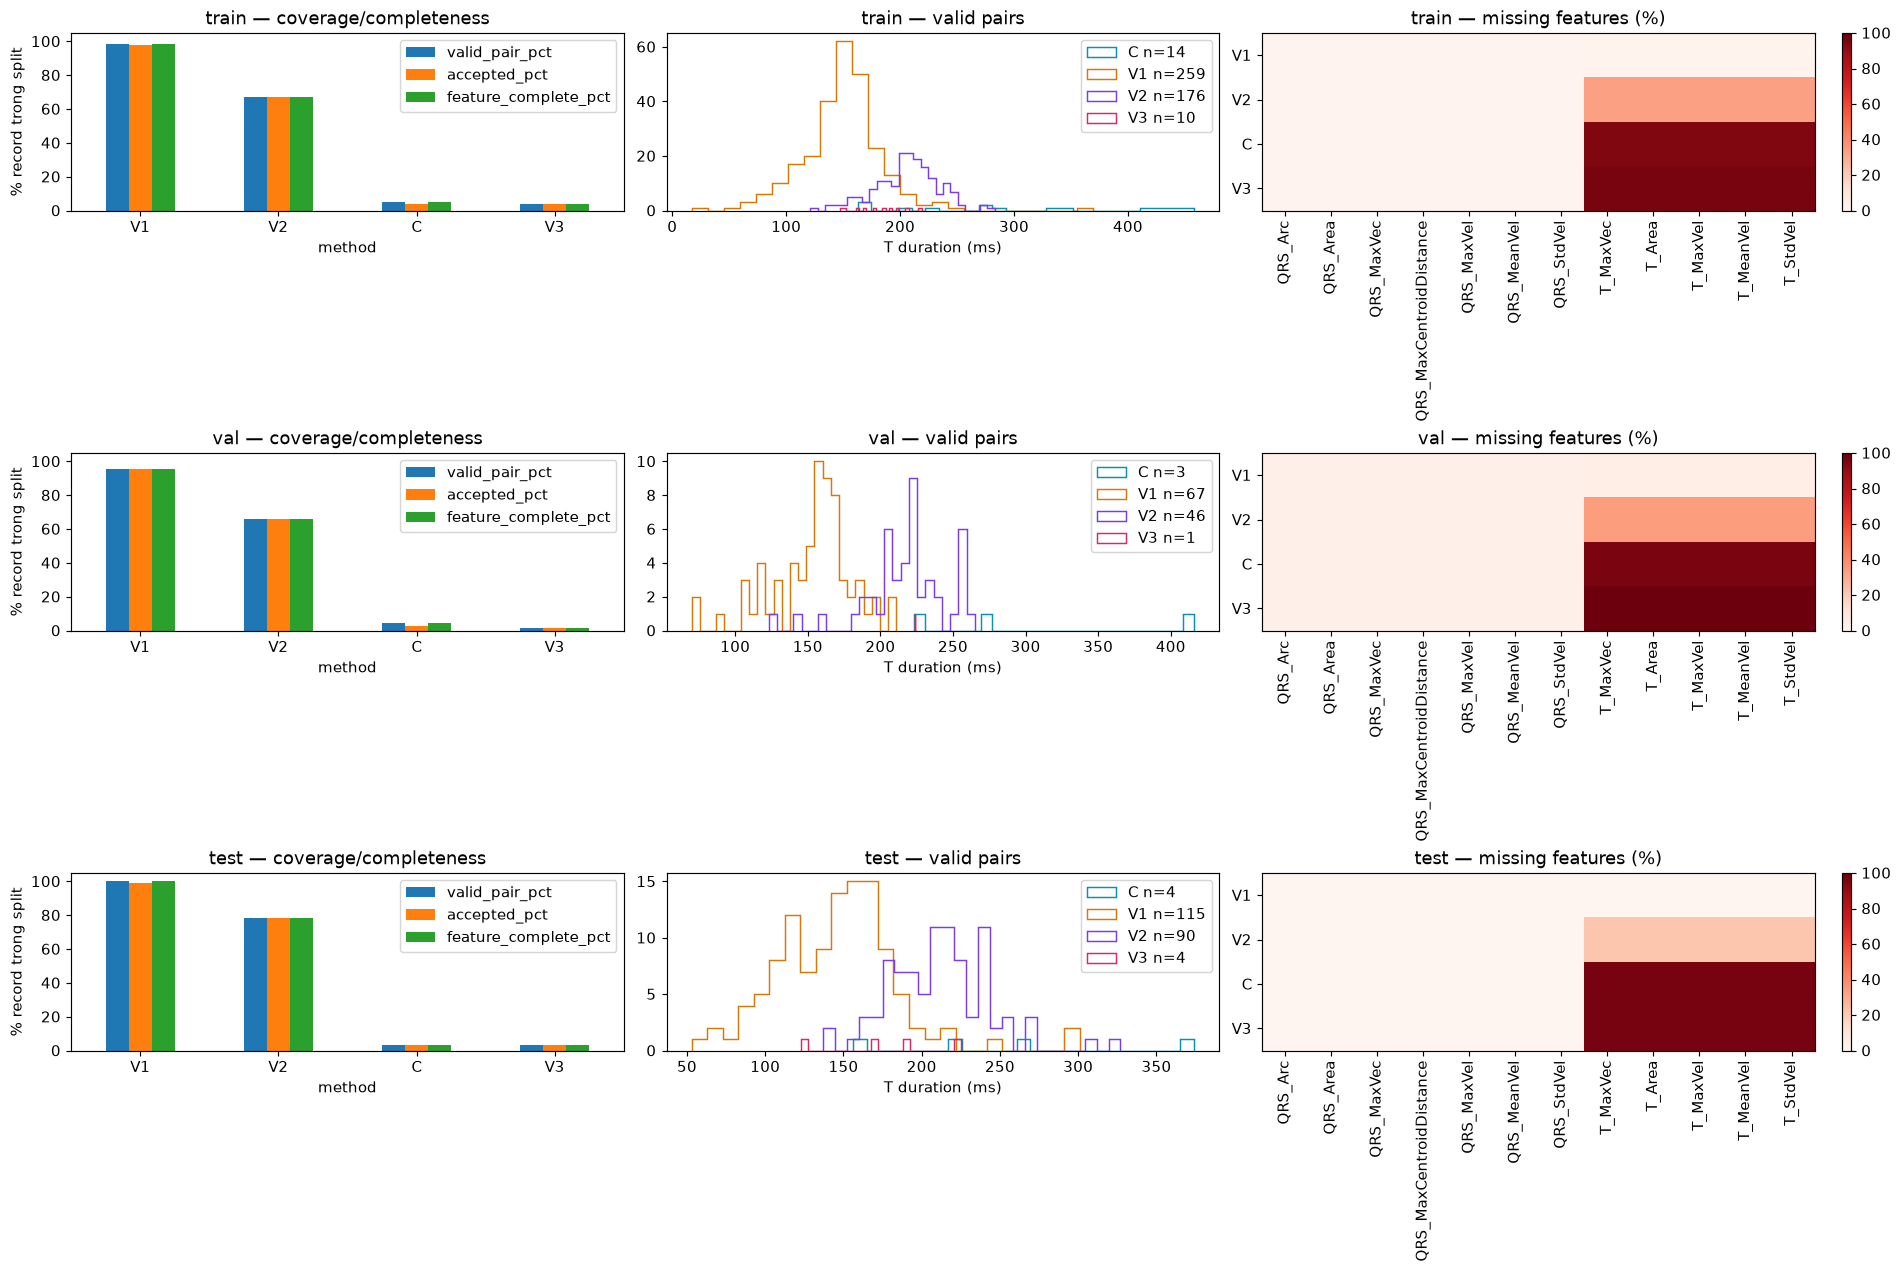

,method,split,label_name,attempted,patients,valid,accepted,feature_complete
0,C,test,HC,17,13,0,0,0
1,C,test,MI,98,37,4,4,4
2,C,train,HC,47,31,8,4,8
3,C,train,MI,216,89,6,6,6
4,C,val,HC,16,8,0,0,0
5,C,val,MI,54,22,3,2,3
6,V1,test,HC,17,13,17,17,17
7,V1,test,MI,98,37,98,97,98
8,V1,train,HC,47,31,47,47,47
9,V1,train,MI,216,89,212,210,212


,split,method,flag,records
0,test,C,Các ngưỡng PSD/persistence/quiet là heuristic ...,115
3,test,C,invalid_or_missing_T_pair,111
14,test,C,threshold_crossing_missing,111
2,test,C,different_morphology_retained_review,26
9,test,C,powerline_inconclusive_review,22
...,...,...,...,...
190,val,V3,Không đủ khoảng ít hoạt động/độ dài/span để ki...,3
192,val,V3,input_or_pipeline_error,2
195,val,V3,many_excluded_beats,2
202,val,V3,rr_irregular,2


In [23]:
cx_splits=[s for s in ('train','val','test') if s in set(cx_eval.split)]
fig,axes=plt.subplots(len(cx_splits),3,figsize=(18,4*len(cx_splits)),squeeze=False,layout='constrained')
for s,ax in zip(cx_splits,axes):
    part=cx_eval[cx_eval.split.eq(s)]; summary=cx_coverage[cx_coverage.split.eq(s)]
    summary.set_index('method')[['valid_pair_pct','accepted_pct','feature_complete_pct']].plot.bar(ax=ax[0],rot=0)
    ax[0].set(ylabel='% record trong split',ylim=(0,105),title=s+' — coverage/completeness')
    for m,g in part.groupby('method'):
        x=pd.to_numeric(g.duration_ms,errors='coerce').dropna()
        if len(x): ax[1].hist(x,bins=25,histtype='step',label=f'{m} n={len(x)}',color=CX_COLORS[m])
    ax[1].set(xlabel='T duration (ms)',title=s+' — valid pairs')
    if ax[1].has_data(): ax[1].legend()
    missing=part.groupby('method')[FEATURE_NAMES].agg(lambda x:100*x.isna().mean()).reindex(CX_METHODS)
    im=ax[2].imshow(missing.to_numpy(dtype=float),aspect='auto',vmin=0,vmax=100,cmap='Reds')
    ax[2].set(yticks=range(len(missing)),yticklabels=missing.index,xticks=range(len(FEATURE_NAMES)),
              xticklabels=FEATURE_NAMES,title=s+' — missing features (%)')
    ax[2].tick_params(axis='x',rotation=90);fig.colorbar(im,ax=ax[2])
cx_show(fig,'coverage_missingness_by_split')
cx_subgroups=cx_eval.groupby(['method','split','label_name'],dropna=False).agg(
    attempted=('record_id','size'),patients=('patient_id','nunique'),valid=('valid_pair','sum'),
    accepted=('accepted','sum'),feature_complete=('feature_complete','sum')).reset_index()
display(cx_subgroups)
cx_flags=cx_eval.assign(flag=cx_eval['flags'].fillna('').str.split(';')).explode('flag')
cx_flags=cx_flags[cx_flags.flag.ne('')].groupby(['split','method','flag']).size().rename('records').reset_index()
display(cx_flags.sort_values(['split','method','records'],ascending=[True,True,False]))
CX_RESULTS.update(flags=cx_flags,coverage_by_label=cx_subgroups)


### Chênh lệch từng cặp, Bland–Altman và overlap

Ở mọi cột delta, dấu dương nghĩa là method bên phải đặt mốc muộn hơn method bên trái. Ví dụ V1→V3 onset +20 ms là onset V3 muộn hơn 20 ms. Median absolute delta là khoảng cách giữa hai phương pháp, không phải sai số với nhãn thật. Với một record không tính được SD/limits đáng tin; đợi cohort.

Các feature QRS phải giữ nguyên giữa V1/V2/C/V3 vì chưa thay QRS hay preprocessing. Bảng pairwise đầy đủ còn có các cột chênh lệch từng feature, relative delta và Spearman trên paired valid records.

**Nếu hình ít điểm hoặc trống:** xem `valid_pairs` trong bảng cell 48 và `valid_pair/flags` ở cell 44–46. Một demo chỉ có 1 điểm cho mỗi cặp hợp lệ; V3 unresolved sẽ không có điểm cho các cặp chứa V3. Hình mới vẽ tất cả cặp có dữ liệu, kèm tên và số điểm; vùng không có dữ liệu được ghi rõ, không thay NaN bằng 0.

,split,left,right,attempted_pairs,valid_pairs,both_accepted,median_iou,median_dice,t_on_ms_median_abs,t_off_ms_median_abs,duration_median_abs_difference_ms
0,test,V1,V2,115,90,89,0.661993,0.796626,41.0,27.0,73.0
1,test,V1,C,115,4,4,0.541971,0.700941,48.0,64.5,112.5
2,test,V1,V3,115,4,4,0.896423,0.945352,10.5,10.0,18.5
3,test,V2,C,115,4,4,0.742307,0.851161,16.5,41.0,43.0
4,test,V2,V3,115,4,4,0.916818,0.956594,9.0,7.0,15.0
5,test,C,V3,115,1,1,0.923077,0.960000,7.0,6.0,13.0
6,train,V1,V2,263,176,175,0.694608,0.819786,39.0,27.0,63.0
7,train,V1,C,263,14,10,0.499975,0.666123,66.0,35.5,148.5
8,train,V1,V3,263,10,10,0.874761,0.933170,12.0,10.5,21.0
9,train,V2,C,263,12,8,0.618706,0.764423,43.5,67.5,88.5


,left,right,attempted_pairs,valid_pairs,both_accepted,t_on_ms_bias,t_on_ms_median_signed,t_on_ms_median_abs,t_on_ms_p90_abs,t_on_ms_sd,t_on_ms_loa_low,t_on_ms_loa_high,t_on_ms_within_10ms_pct,t_on_ms_within_20ms_pct,t_on_ms_within_25ms_pct,t_on_ms_within_40ms_pct,t_on_ms_within_50ms_pct,t_off_ms_bias,t_off_ms_median_signed,t_off_ms_median_abs,...,T_MaxVec_median_abs_delta,T_MaxVec_median_relative_delta_pct,T_MaxVec_spearman,T_Area_paired_n,T_Area_median_abs_delta,T_Area_median_relative_delta_pct,T_Area_spearman,T_MaxVel_paired_n,T_MaxVel_median_abs_delta,T_MaxVel_median_relative_delta_pct,T_MaxVel_spearman,T_MeanVel_paired_n,T_MeanVel_median_abs_delta,T_MeanVel_median_relative_delta_pct,T_MeanVel_spearman,T_StdVel_paired_n,T_StdVel_median_abs_delta,T_StdVel_median_relative_delta_pct,T_StdVel_spearman,split
0,V1,V2,115,90,89,-36.900000,-39.5,41.0,59.1,28.595611,-92.947398,19.147398,0.000000,4.444444,8.888889,48.888889,74.444444,30.244444,27.0,27.0,...,0.0,0.0,0.999095,90,0.001691,16.296561,0.971108,90,0.0,0.0,0.959567,90,0.494671,-15.374065,0.979948,90,0.106402,6.694502,0.938923,test
1,V1,C,115,4,4,-46.500000,-48.0,48.0,65.9,21.641010,-88.916380,-4.083620,0.000000,0.000000,25.000000,50.000000,50.000000,80.250000,64.5,64.5,...,0.0,0.0,1.000000,4,0.000894,8.151191,1.000000,4,0.0,0.0,1.000000,4,1.069771,-19.790606,0.800000,4,0.114785,8.159943,1.000000,test
2,V1,V3,115,4,4,-13.750000,-10.5,10.5,23.6,10.500000,-34.330000,6.830000,50.000000,75.000000,75.000000,100.000000,100.000000,14.250000,10.0,10.0,...,0.0,0.0,1.000000,4,0.000713,7.073352,1.000000,4,0.0,0.0,1.000000,4,0.099923,-3.504249,1.000000,4,0.017785,1.719140,1.000000,test
3,V2,C,115,4,4,-6.250000,-1.0,16.5,33.1,26.986108,-59.142771,46.642771,0.000000,75.000000,75.000000,100.000000,100.000000,49.250000,31.5,41.0,...,0.0,0.0,1.000000,4,0.000176,-0.554129,1.000000,4,0.0,0.0,1.000000,4,0.447489,-8.187942,0.800000,4,0.057120,-0.162067,1.000000,test
4,V2,V3,115,4,4,9.000000,9.0,9.0,11.7,2.943920,3.229916,14.770084,50.000000,100.000000,100.000000,100.000000,100.000000,-7.250000,-7.0,7.0,...,0.0,0.0,1.000000,4,0.000563,-3.952865,1.000000,4,0.0,0.0,1.000000,4,0.116454,4.705380,1.000000,4,0.035054,-2.771372,1.000000,test
5,C,V3,115,1,1,-7.000000,-7.0,7.0,7.0,NaN,NaN,NaN,100.000000,100.000000,100.000000,100.000000,100.000000,6.000000,6.0,6.0,...,0.0,0.0,NaN,1,0.000060,-0.710721,NaN,1,0.0,0.0,NaN,1,0.171172,-4.470772,NaN,1,0.064574,4.377343,NaN,test
6,V1,V2,263,176,175,-29.642045,-36.0,39.0,56.5,29.750625,-87.953271,28.669180,5.681818,14.204545,17.045455,55.113636,81.818182,28.659091,26.5,27.0,...,0.0,0.0,0.999987,176,0.001924,14.056664,0.978715,176,0.0,0.0,0.996163,176,0.476808,-14.273043,0.976014,176,0.101102,6.142005,0.969245,train
7,V1,C,263,14,10,-70.571429,-66.0,66.0,119.6,48.037989,-164.725886,23.583029,0.000000,0.000000,28.571429,35.714286,42.857143,78.071429,35.5,35.5,...,0.0,0.0,1.000000,14,0.000883,10.622424,0.991209,14,0.0,0.0,1.000000,14,0.958856,-25.803547,0.709890,14,0.124084,7.092200,0.916484,train
8,V1,V3,263,10,10,-18.500000,-12.0,12.0,41.3,16.787892,-51.404269,14.404269,30.000000,70.000000,70.000000,70.000000,100.000000,11.300000,10.5,10.5,...,0.0,0.0,1.000000,10,0.000853,7.288715,1.000000,10,0.0,0.0,1.000000,10,0.192826,-5.387338,0.915152,10,0.052942,2.536393,1.000000,train
9,V2,C,263,12,8,-39.333333,-43.5,43.5,81.5,55.614474,-148.337702,69.671035,8.333333,25.000000,33.333333,50.000000,58.333333,57.250000,57.0,67.5,...,0.0,0.0,1.000000,12,0.000188,-0.485623,0.986014,12,0.0,0.0,1.000000,12,0.554507,-14.798253,0.769231,12,0.055414,2.043773,0.986014,train


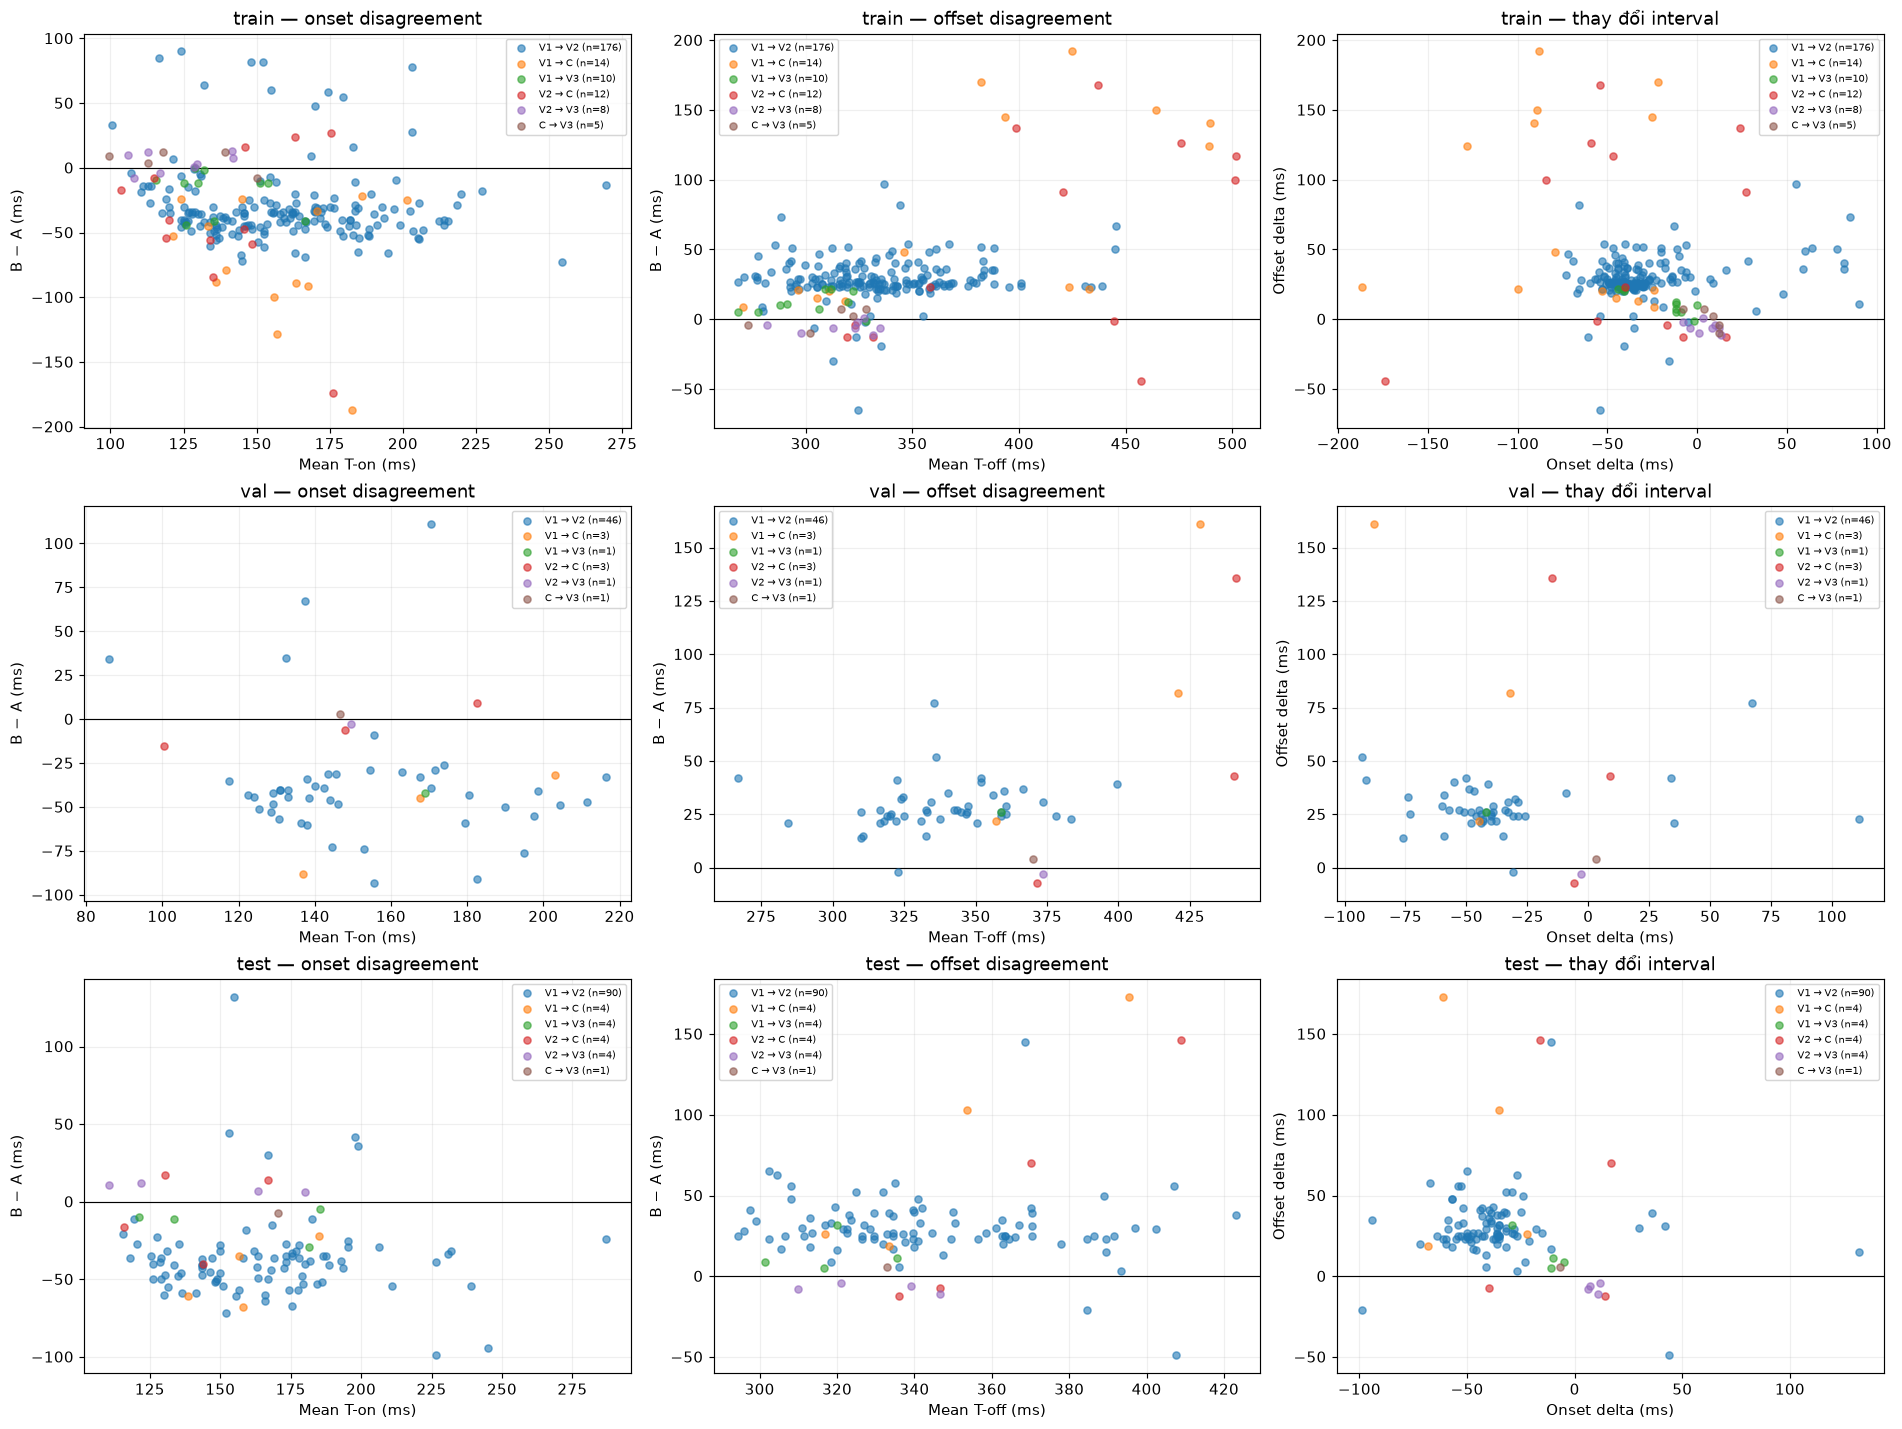

,method,metric,estimate,low,high,patients,note,split
0,C,accepted_rate,0.034783,0.000000,0.079590,50,95% percentile patient-cluster bootstrap; desc...,test
1,V1,accepted_rate,0.991304,0.970857,1.000000,50,95% percentile patient-cluster bootstrap; desc...,test
2,V2,accepted_rate,0.782609,0.674792,0.876339,50,95% percentile patient-cluster bootstrap; desc...,test
3,V3,accepted_rate,0.034783,0.007752,0.072658,50,95% percentile patient-cluster bootstrap; desc...,test
4,C,accepted_rate,0.038023,0.015728,0.060892,120,95% percentile patient-cluster bootstrap; desc...,train
5,V1,accepted_rate,0.977186,0.959440,0.992728,120,95% percentile patient-cluster bootstrap; desc...,train
6,V2,accepted_rate,0.669202,0.597614,0.734665,120,95% percentile patient-cluster bootstrap; desc...,train
7,V3,accepted_rate,0.038023,0.016061,0.064133,120,95% percentile patient-cluster bootstrap; desc...,train
8,C,accepted_rate,0.028571,0.000000,0.068993,30,95% percentile patient-cluster bootstrap; desc...,val
9,V1,accepted_rate,0.957143,0.890315,1.000000,30,95% percentile patient-cluster bootstrap; desc...,val


In [24]:
cx_pairs_list=[]; cx_details_list=[]
for split,g in cx_eval.groupby('split',sort=False):
    summary,details=cx_pairwise(g)
    cx_pairs_list.append(summary.assign(split=split))
    if not details.empty: cx_details_list.append(details.assign(split=split))
cx_pairs=pd.concat(cx_pairs_list,ignore_index=True)
cx_pair_details=pd.concat(cx_details_list,ignore_index=True) if cx_details_list else pd.DataFrame()
base_cols=['split','left','right','attempted_pairs','valid_pairs','both_accepted','median_iou','median_dice',
           't_on_ms_median_abs','t_off_ms_median_abs','duration_median_abs_difference_ms']
display(cx_pairs.reindex(columns=base_cols));display(cx_pairs)
fig,axes=plt.subplots(len(cx_splits),3,figsize=(18,4.5*len(cx_splits)),squeeze=False,layout='constrained')
for split,axs in zip(cx_splits,axes):
    part=cx_pair_details[cx_pair_details.split.eq(split)] if not cx_pair_details.empty else pd.DataFrame()
    if not part.empty:
        for j,((a,b),g) in enumerate(part.groupby(['left','right'],sort=False)):
            color=plt.get_cmap('tab10')(j%10); label=f'{a} → {b} (n={len(g)})'
            for ax,x,y in ((axs[0],g.on_mean_ms,g.on_delta_ms),(axs[1],g.off_mean_ms,g.off_delta_ms),
                           (axs[2],g.on_delta_ms,g.off_delta_ms)):
                ax.scatter(x,y,s=24,alpha=.6,color=color,label=label,zorder=5)
        for ax in axs:ax.legend(fontsize=7)
    else:
        for ax in axs:ax.text(.5,.5,'Không có cặp biên hợp lệ chung.\nXem valid_pairs và flags.',ha='center',va='center',transform=ax.transAxes)
    for ax in axs:ax.axhline(0,color='black',lw=.8);ax.grid(alpha=.2)
    axs[0].set(xlabel='Mean T-on (ms)',ylabel='B − A (ms)',title=split+' — onset disagreement')
    axs[1].set(xlabel='Mean T-off (ms)',ylabel='B − A (ms)',title=split+' — offset disagreement')
    axs[2].set(xlabel='Onset delta (ms)',ylabel='Offset delta (ms)',title=split+' — thay đổi interval')
cx_show(fig,'pairwise_boundary_deltas_by_split')
for feature in [f for f in FEATURE_NAMES if f.startswith('QRS_')]:
    assert cx_eval.pivot(index='record_id',columns='method',values=feature).nunique(axis=1,dropna=True).le(1).all(), feature
cx_ci=pd.concat([cx_patient_ci(g).assign(split=s) for s,g in cx_eval.groupby('split',sort=False)],ignore_index=True)
display(cx_ci)
CX_RESULTS.update(pairwise_summary=cx_pairs,pairwise_details=cx_pair_details,patient_bootstrap_ci=cx_ci)


### Cùng nhiễu, cùng seeds: V1/V2/C/V3 có đổi quyết định không?

Noise thêm vào **median beat**, giữ nguyên anchors/RR/PQ/QRS detector raw; vì vậy đây là stability của tầng delineation. Scale noise = 0.5/1/2% robust scale XYZ, không phải SNR sinh lý đã biết. Báo cáo cả lần mất biên; delta chỉ tính khi trước và sau đều valid. Một phương pháp luôn thất bại không được xem là ổn định vì delta NaN.

Option bootstrap lấy mẫu lại các beat đã giữ rồi tạo median mới kiểm tra thêm độ phụ thuộc vào beat selection. Nó chưa chạy lại toàn bộ raw preprocessing và không đại diện biến thiên giữa bệnh nhân.

**Cách xem hình:** hai ô đầu là jitter có điều kiện trên những lần cả trước/sau nhiễu đều có biên hợp lệ. Ô thứ ba cho biết bao nhiêu % lần đủ điều kiện tính jitter. Đường ở 0 ms nghĩa là có đo và mốc không đổi; thiếu đường/NaN nghĩa là thiếu cặp đo, không phải thuật toán hoàn hảo.
**Phạm vi:** mặc định tất cả record đã chọn; bảng và ba ô hình lặp riêng train/valid/test. `records`, `repetitions`, `paired_n` cho biết mẫu số. Input lỗi vẫn giữ các lần thử nhưng jitter để NaN.


stability 1/448 | cache 0 | failures 0
stability 10/448 | cache 0 | failures 0
stability 20/448 | cache 0 | failures 0
stability 30/448 | cache 0 | failures 0
stability 40/448 | cache 0 | failures 0
stability 50/448 | cache 0 | failures 0
stability 60/448 | cache 0 | failures 0
stability 70/448 | cache 0 | failures 0
stability 80/448 | cache 0 | failures 0
stability 90/448 | cache 0 | failures 0
stability 100/448 | cache 0 | failures 0
stability 110/448 | cache 0 | failures 0
stability 120/448 | cache 0 | failures 0
stability 130/448 | cache 0 | failures 0
stability 140/448 | cache 0 | failures 0
stability 150/448 | cache 0 | failures 0
stability 160/448 | cache 0 | failures 0
stability 170/448 | cache 0 | failures 1
stability 180/448 | cache 0 | failures 2
stability 190/448 | cache 0 | failures 2
stability 200/448 | cache 0 | failures 2
stability 210/448 | cache 0 | failures 2
stability 220/448 | cache 0 | failures 2
stability 230/448 | cache 0 | failures 2
stability 240/448 | cache 0

,method,level,seed,sigma_mV,base_valid,perturbed_valid,accepted,native_status,status_changed,on_delta_ms,off_delta_ms,record_id,patient_id,split,label_name,abs_on_delta_ms,abs_off_delta_ms
0,V1,0.005,0,0.000217,True,True,True,detected,0.0,0.0,3.0,patient150/s0287lre,patient150,test,HC,0.0,3.0
1,V2,0.005,0,0.000217,True,True,True,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
2,C,0.005,0,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
3,V3,0.005,0,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
4,V1,0.005,1,0.000217,True,True,True,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
5,V2,0.005,1,0.000217,True,True,True,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
6,C,0.005,1,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
7,V3,0.005,1,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
8,V1,0.005,2,0.000217,True,True,True,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
9,V2,0.005,2,0.000217,True,True,True,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0


,split,method,level,records,repetitions,base_valid,retained_valid,accepted,status_flip_rate,paired_n,on_median_abs_ms,off_median_abs_ms,on_p90_abs_ms,off_p90_abs_ms,paired_pct,valid_retention_pct
0,test,C,0.005,115,575,20,20,20,0.000000,20,0.0,0.0,0.1,0.0,3.478261,100.000000
1,test,C,0.010,115,575,20,21,21,0.001739,20,0.0,0.0,1.0,0.0,3.478261,100.000000
2,test,C,0.020,115,575,20,24,24,0.006957,20,0.0,0.0,1.0,1.0,3.478261,100.000000
3,test,V1,0.005,115,575,575,575,570,0.000000,575,0.0,0.0,1.0,1.0,100.000000,100.000000
4,test,V1,0.010,115,575,575,575,570,0.000000,575,0.0,0.0,1.0,1.0,100.000000,100.000000
5,test,V1,0.020,115,575,575,575,569,0.000000,575,0.0,0.0,1.0,2.0,100.000000,100.000000
6,test,V2,0.005,115,575,450,447,447,0.005217,447,0.0,0.0,0.0,0.0,77.739130,99.333333
7,test,V2,0.010,115,575,450,447,447,0.005217,447,0.0,0.0,0.4,0.0,77.739130,99.333333
8,test,V2,0.020,115,575,450,448,448,0.010435,446,0.0,0.0,1.0,0.0,77.565217,99.111111
9,test,V3,0.005,115,575,20,20,20,0.000000,20,0.0,0.0,1.0,0.0,3.478261,100.000000


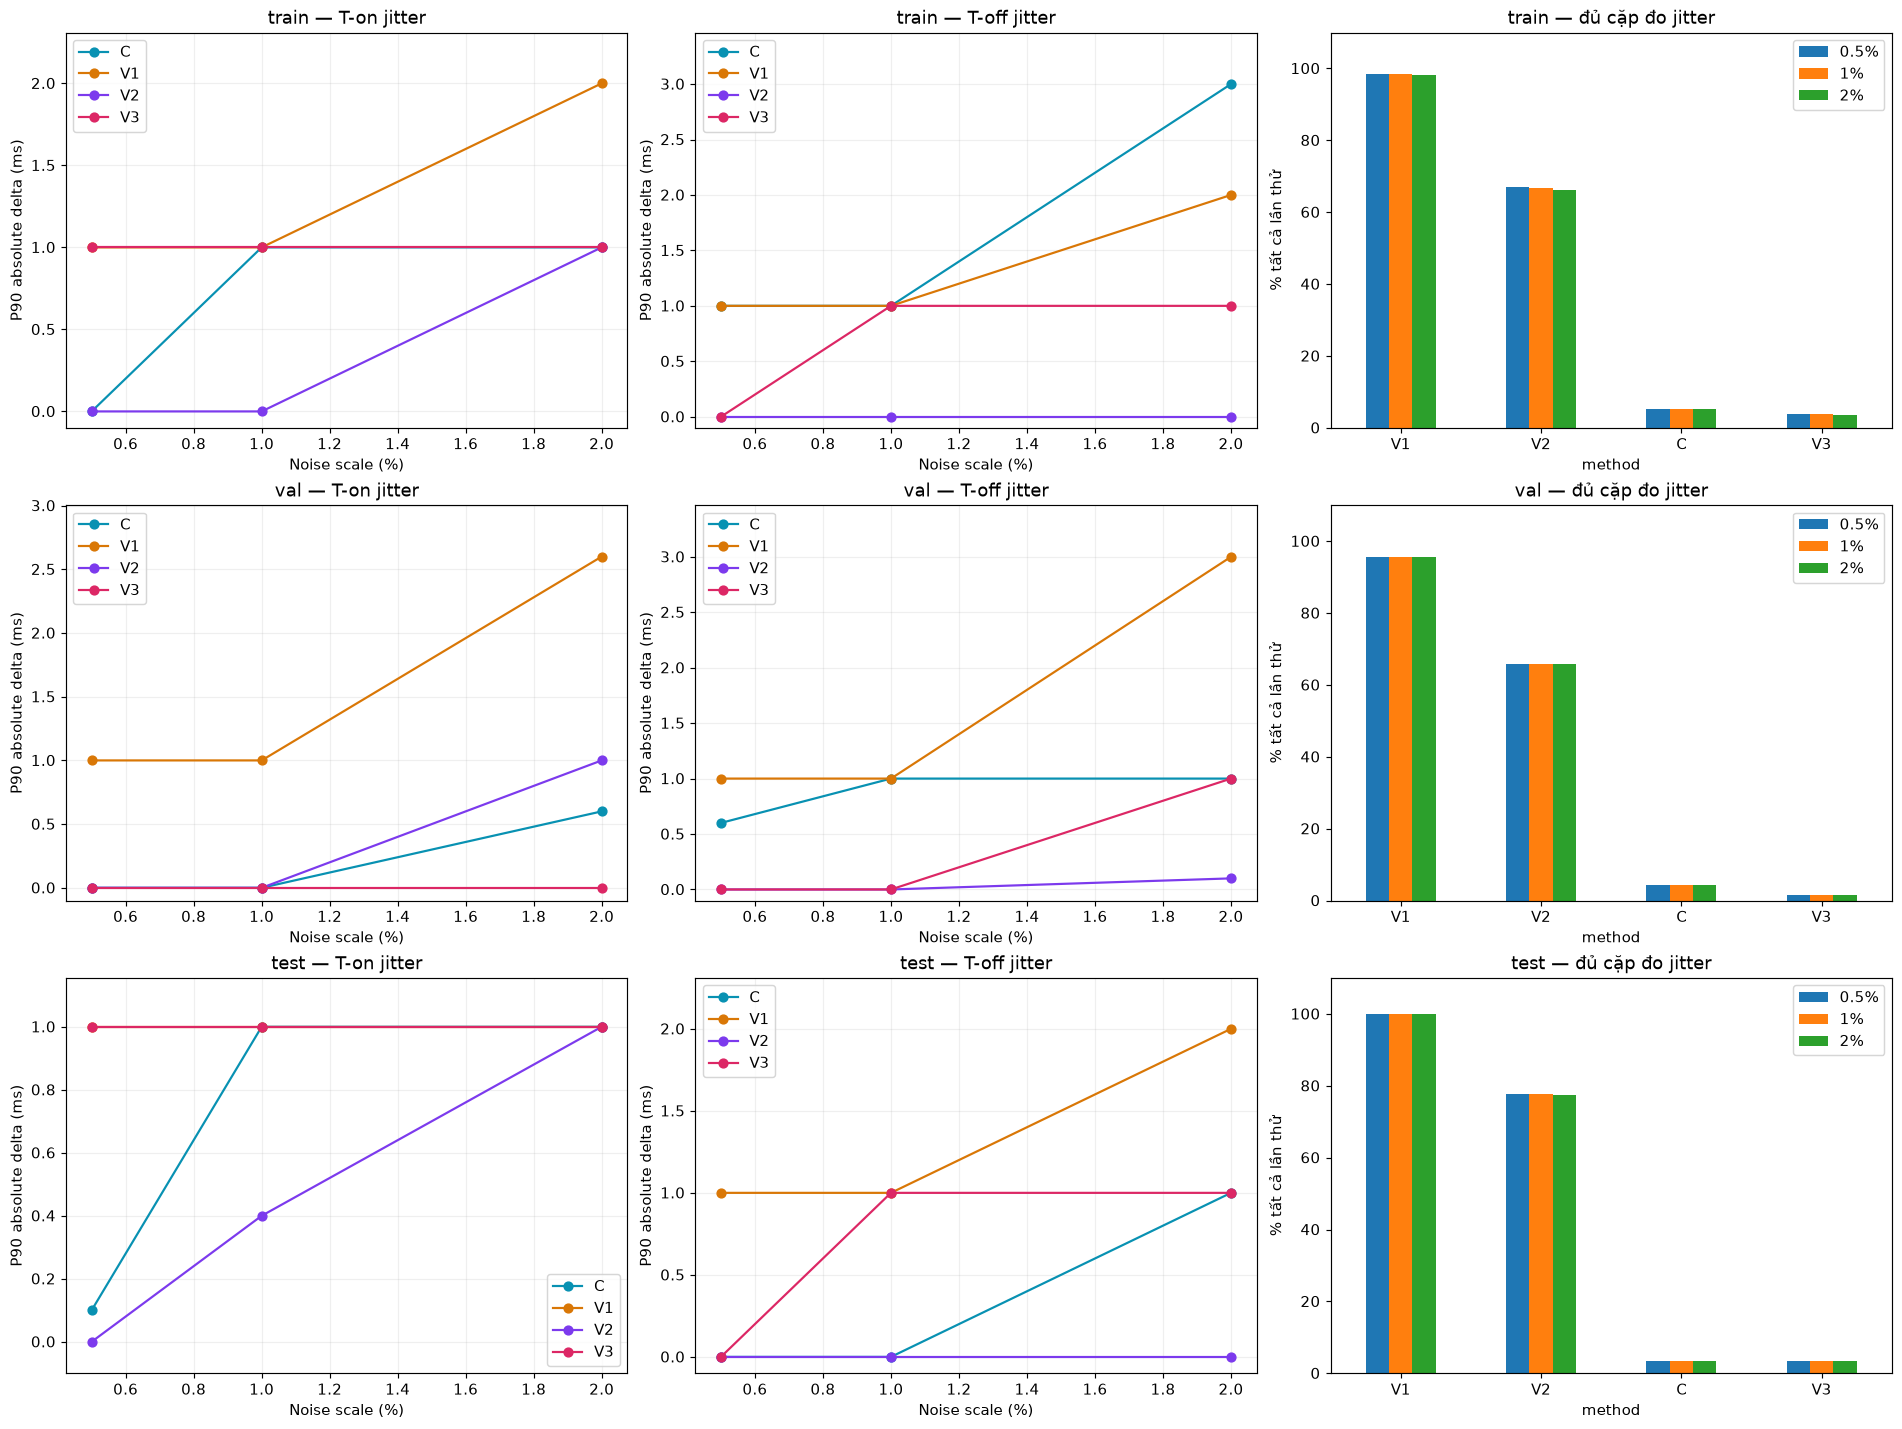

Jitter=0 có cặp đo; NaN không phải 0. valid_retention_pct dùng mẫu số base_valid.


,split,method,records,repetitions,paired_n,onset_p90_ms,offset_p90_ms
0,test,C,115,1150,25,8.6,17.2
1,test,V1,115,1150,1144,11.0,8.0
2,test,V2,115,1150,875,6.0,4.0
3,test,V3,115,1150,19,7.4,3.0
4,train,C,263,2630,106,7.5,27.5
5,train,V1,263,2630,2576,12.0,8.0
6,train,V2,263,2630,1710,5.0,4.0
7,train,V3,263,2630,64,4.0,4.0
8,val,C,70,700,18,21.3,11.5
9,val,V1,70,700,665,10.6,9.0


In [25]:
cx_stability=pd.DataFrame(); cx_beat_bootstrap=pd.DataFrame()
if CX_RUN_STABILITY:
    cx_stability,stability_errors=cx_run_task('stability',cx_selected)
    CX_RESULTS['stability_errors']=stability_errors
if CX_RUN_BOOTSTRAP:
    cx_beat_bootstrap,bootstrap_errors=cx_run_task('bootstrap',cx_selected)
    CX_RESULTS['bootstrap_errors']=bootstrap_errors
if not cx_stability.empty:
    for column in ('on_delta_ms','off_delta_ms','status_changed'):
        cx_stability[column]=pd.to_numeric(cx_stability[column],errors='coerce')
    cx_stability['abs_on_delta_ms']=cx_stability.on_delta_ms.abs()
    cx_stability['abs_off_delta_ms']=cx_stability.off_delta_ms.abs()
    cx_preview(cx_stability)
    stability_summary=cx_stability.groupby(['split','method','level']).agg(
        records=('record_id','nunique'),repetitions=('seed','size'),base_valid=('base_valid','sum'),
        retained_valid=('perturbed_valid','sum'),accepted=('accepted','sum'),status_flip_rate=('status_changed','mean'),
        paired_n=('on_delta_ms','count'),on_median_abs_ms=('abs_on_delta_ms','median'),
        off_median_abs_ms=('abs_off_delta_ms','median'),on_p90_abs_ms=('abs_on_delta_ms',lambda s:s.quantile(.9)),
        off_p90_abs_ms=('abs_off_delta_ms',lambda s:s.quantile(.9))).reset_index()
    stability_summary['paired_pct']=100*stability_summary.paired_n/stability_summary.repetitions
    stability_summary['valid_retention_pct']=100*stability_summary.paired_n/stability_summary.base_valid.replace(0,np.nan)
    display(stability_summary)
    fig,axes=plt.subplots(len(cx_splits),3,figsize=(18,4.5*len(cx_splits)),squeeze=False,layout='constrained')
    for split,axs in zip(cx_splits,axes):
        part=stability_summary[stability_summary.split.eq(split)]
        for ax,metric,title in ((axs[0],'on_p90_abs_ms','T-on jitter'),(axs[1],'off_p90_abs_ms','T-off jitter')):
            plotted=False
            for m,g in part.groupby('method',sort=False):
                good=np.isfinite(g[metric])
                if good.any():ax.plot(g.loc[good,'level']*100,g.loc[good,metric],'o-',color=CX_COLORS[m],label=m);plotted=True
            if plotted: ax.legend();ax.set_ylim(bottom=-.1,top=max(1.,ax.get_ylim()[1]*1.1))
            else: ax.text(.5,.5,'Jitter NaN: không có cặp đo hợp lệ.',ha='center',transform=ax.transAxes)
            ax.set(xlabel='Noise scale (%)',ylabel='P90 absolute delta (ms)',title=split+' — '+title);ax.grid(alpha=.2)
        pairing=part.pivot(index='method',columns='level',values='paired_pct').reindex(CX_METHODS)
        pairing.columns=[f'{100*float(v):g}%' for v in pairing.columns]
        pairing.plot.bar(ax=axs[2],rot=0)
        axs[2].set(ylim=(0,110),ylabel='% tất cả lần thử',title=split+' — đủ cặp đo jitter')
    cx_show(fig,'delineation_stability_by_split')
    print('Jitter=0 có cặp đo; NaN không phải 0. valid_retention_pct dùng mẫu số base_valid.')
    CX_RESULTS['stability_summary']=stability_summary
if not cx_beat_bootstrap.empty:
    for column in ('on_delta_ms','off_delta_ms'):
        cx_beat_bootstrap[column]=pd.to_numeric(cx_beat_bootstrap[column],errors='coerce')
        cx_beat_bootstrap['abs_'+column]=cx_beat_bootstrap[column].abs()
    bootstrap_summary=cx_beat_bootstrap.groupby(['split','method']).agg(
        records=('record_id','nunique'),repetitions=('repeat','size'),paired_n=('valid','sum'),
        onset_p90_ms=('abs_on_delta_ms',lambda s:s.quantile(.9)),offset_p90_ms=('abs_off_delta_ms',lambda s:s.quantile(.9))).reset_index()
    display(bootstrap_summary);CX_RESULTS['beat_bootstrap_summary']=bootstrap_summary
CX_RESULTS.update(stability=cx_stability,beat_bootstrap=cx_beat_bootstrap)


### Dịch biên ±5/10/20 ms và đo lại features

Chạy cùng tập shift cho mọi method có valid interval. Có 3 kiểu: chỉ onset, chỉ offset, hoặc dịch cả interval. Mỗi ca không còn đúng thứ tự hoặc loại peak ra ngoài đều giữ dòng invalid và NaN; không âm thầm clip vào mảng. Relative change dùng |baseline feature| ở mẫu số; baseline gần 0 được ghi NaN để tránh tỷ lệ khổng lồ vô nghĩa.

Heatmap chỉ hiển thị median |relative change| của các scenario valid, còn bảng invalid cho biết mẫu đã mất. Các feature có đơn vị khác nhau được xem riêng; không cộng Area, MaxVec và Velocity thành một thang tổng.
**Phạm vi:** tất cả record/method, kể cả baseline không có T (giữ invalid + lý do). Heatmap tách theo split, bảng scenario dùng khóa record/method/shift trước khi đếm, không đếm mỗi feature thành một lần thử.


sensitivity 1/448 | cache 0 | failures 0
sensitivity 10/448 | cache 0 | failures 0
sensitivity 20/448 | cache 0 | failures 0
sensitivity 30/448 | cache 0 | failures 0
sensitivity 40/448 | cache 0 | failures 0
sensitivity 50/448 | cache 0 | failures 0
sensitivity 60/448 | cache 0 | failures 0
sensitivity 70/448 | cache 0 | failures 0
sensitivity 80/448 | cache 0 | failures 0
sensitivity 90/448 | cache 0 | failures 0
sensitivity 100/448 | cache 0 | failures 0
sensitivity 110/448 | cache 0 | failures 0
sensitivity 120/448 | cache 0 | failures 0
sensitivity 130/448 | cache 0 | failures 0
sensitivity 140/448 | cache 0 | failures 0
sensitivity 150/448 | cache 0 | failures 0
sensitivity 160/448 | cache 0 | failures 0
sensitivity 170/448 | cache 0 | failures 1
sensitivity 180/448 | cache 0 | failures 2
sensitivity 190/448 | cache 0 | failures 2
sensitivity 200/448 | cache 0 | failures 2
sensitivity 210/448 | cache 0 | failures 2
sensitivity 220/448 | cache 0 | failures 2
sensitivity 230/448 | 

,method,scenario,on_shift_ms,off_shift_ms,represented_on_shift_ms,represented_off_shift_ms,valid,reason,feature,baseline,value,delta,abs_delta,relative_delta_pct,record_id,patient_id,split,label_name
0,V1,baseline,0,0,0.0,0.0,True,,QRS_Arc,5.163720,5.163720,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
1,V1,baseline,0,0,0.0,0.0,True,,QRS_Area,0.270612,0.270612,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
2,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxVec,2.412297,2.412297,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
3,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxCentroidDistance,1.435421,1.435421,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
4,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxVel,213.122252,213.122252,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
5,V1,baseline,0,0,0.0,0.0,True,,QRS_MeanVel,83.751363,83.751363,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
6,V1,baseline,0,0,0.0,0.0,True,,QRS_StdVel,51.293480,51.293480,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
7,V1,baseline,0,0,0.0,0.0,True,,T_MaxVec,0.674714,0.674714,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
8,V1,baseline,0,0,0.0,0.0,True,,T_Area,0.011304,0.011304,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
9,V1,baseline,0,0,0.0,0.0,True,,T_MaxVel,12.934495,12.934495,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC


,split,method,valid,reason,record_scenarios
0,test,C,False,invalid_baseline,2109
1,test,C,True,,76
2,test,V1,False,order_peak_or_array_boundary,12
3,test,V1,True,,2173
4,test,V2,False,invalid_baseline,475
5,test,V2,True,,1710
6,test,V3,False,invalid_baseline,2109
7,test,V3,True,,76
8,train,C,False,input_or_pipeline_error,57
9,train,C,False,invalid_baseline,4674


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.258795,0.0,1.889172,1.872483
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.164817,0.0,1.712691,1.242236
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.636633,0.0,1.335833,0.556174
V3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.015725,0.0,1.644490,1.544672


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.074821,0.0,1.885552,1.880585
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.076893,0.0,1.579736,1.060096
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903609,0.0,0.872689,0.449244
V3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.547043,0.0,1.413805,0.761800


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.250106,0.0,1.874808,1.875050
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.078104,0.0,1.645141,1.124690
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.567271,0.0,1.347539,0.981558
V3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.485288,0.0,1.673811,1.440695


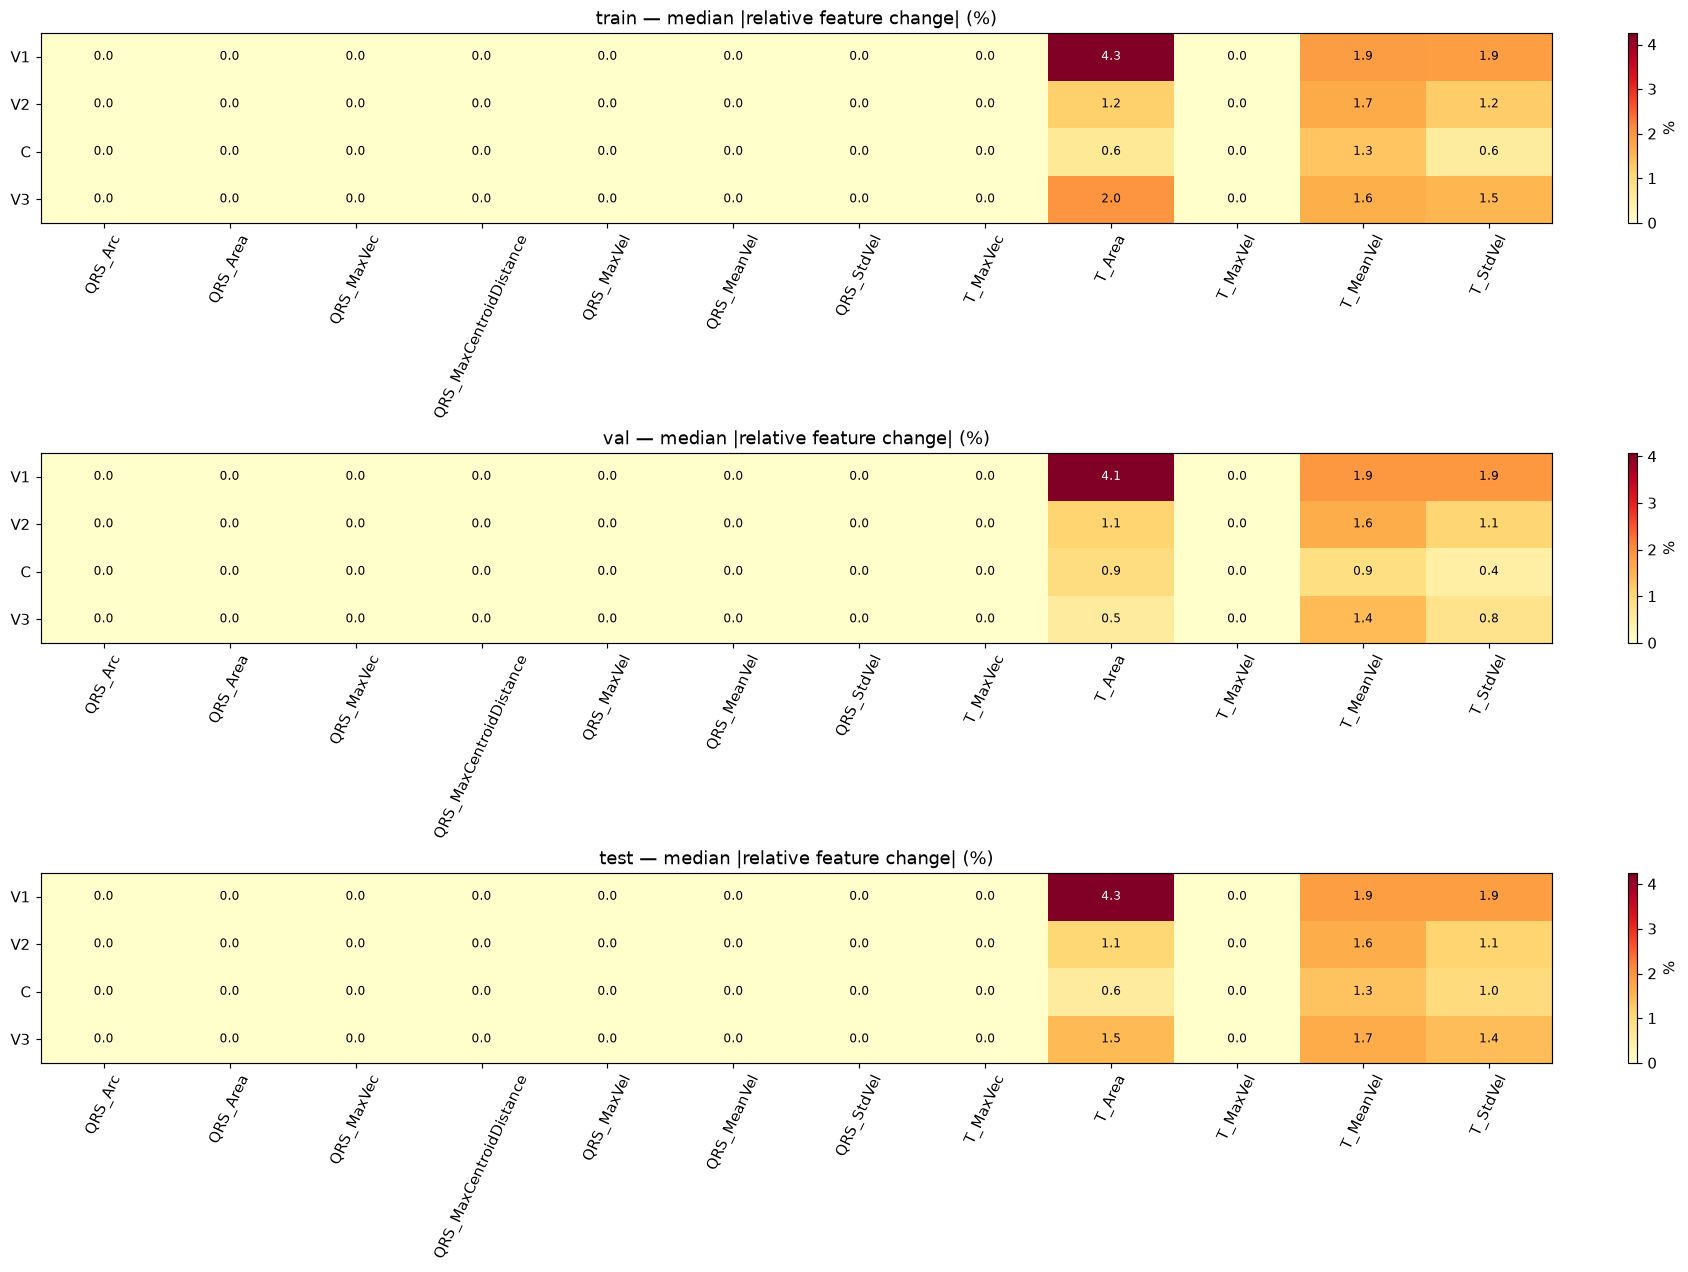

In [26]:
cx_sens=pd.DataFrame()
if CX_RUN_SENSITIVITY:
    cx_sens,sensitivity_errors=cx_run_task('sensitivity',cx_selected)
    CX_RESULTS['sensitivity_errors']=sensitivity_errors
if not cx_sens.empty:
    for column in ('relative_delta_pct','abs_delta'):cx_sens[column]=pd.to_numeric(cx_sens[column],errors='coerce')
    cx_preview(cx_sens)
    scenarios=cx_sens[['record_id','split','method','scenario','on_shift_ms','off_shift_ms','valid','reason']].drop_duplicates()
    scenario_summary=scenarios.groupby(['split','method','valid','reason'],dropna=False).size().rename('record_scenarios').reset_index()
    display(scenario_summary)
    vis=cx_sens[cx_sens.scenario.ne('baseline') & cx_sens.valid].copy()
    vis['abs_relative_pct']=vis.relative_delta_pct.abs()
    fig,axes=plt.subplots(len(cx_splits),1,figsize=(16,4*len(cx_splits)),squeeze=False,layout='constrained')
    grids=[]
    for split,ax in zip(cx_splits,axes[:,0]):
        part=vis[vis.split.eq(split)]
        grid=part.pivot_table(index='method',columns='feature',values='abs_relative_pct',aggfunc='median').reindex(index=CX_METHODS,columns=FEATURE_NAMES)
        grids.append(grid.reset_index().assign(split=split));display(grid)
        values=grid.to_numpy(dtype=float); finite=values[np.isfinite(values)]
        vmax=max(float(finite.max()),1e-6) if len(finite) else 1.
        cmap=plt.get_cmap('YlOrRd').copy();cmap.set_bad('#e5e7eb')
        im=ax.imshow(np.ma.masked_invalid(values),aspect='auto',cmap=cmap,vmin=0,vmax=vmax)
        for (row,col),value in np.ndenumerate(values):
            ax.text(col,row,f'{value:.1f}' if np.isfinite(value) else 'N/A',ha='center',va='center',fontsize=8,
                    color='white' if np.isfinite(value) and value>.65*vmax else 'black')
        ax.set(yticks=range(len(grid)),yticklabels=grid.index,xticks=range(len(grid.columns)),xticklabels=grid.columns,
               title=split+' — median |relative feature change| (%)')
        ax.tick_params(axis='x',rotation=65);fig.colorbar(im,ax=ax,label='%')
    cx_show(fig,'feature_boundary_sensitivity_by_split')
    CX_RESULTS.update(sensitivity_scenarios=scenario_summary,sensitivity_heatmap=pd.concat(grids,ignore_index=True))
CX_RESULTS['feature_sensitivity']=cx_sens


### Các option consensus và ablation

So sánh complete-link tolerance 10/25/40 ms × [2/3 phiếu, 3/3 phiếu, V1+V2, V2+C, V1+C]. Cùng một nhóm phải đồng ý **cả onset và offset**. Không ghép onset từ nhóm A với offset từ nhóm B. Tolerance kiểm tra max–min, tránh hiện tượng nối chuỗi 0→20→40 ms rồi nhận cả ba ở ngưỡng 25 ms.

V1+C có tương quan vì cùng magnitude/baseline; coverage cao của cặp này không phải bằng chứng độc lập. Bảng demo giải thích tác động cấu hình; chỉ thí nghiệm lựa chọn trên train/valid, khóa cấu hình trước khi báo cáo test. Không tự chọn “option tốt nhất” theo agreement.
**Mặc định:** sweep toàn bộ train và valid đã chọn, báo cáo riêng từng split; không chạy sweep test, không tự thay cấu hình V3 đang dùng cho báo cáo cuối.


In [27]:
# Bảng một ca giải thích cơ chế; sweep chỉ trên tập phát triển.
cx_option_rows=cx_options(cx_demo,cx_demo_results)
cx_preview(cx_option_rows[['option','native_status','valid_pair','accepted','duration_ms','votes','flags']])
cx_sweep=pd.DataFrame()
if CX_RUN_COHORT_OPTIONS:
    development=cx_selected[cx_selected.split.isin(['train','val'])].copy()
    if not development.empty:
        cx_sweep,option_errors=cx_run_task('options',development)
        option_summary=cx_sweep.groupby(['split','option']).agg(attempted=('record_id','size'),
            patients=('patient_id','nunique'),valid=('valid_pair','sum'),accepted=('accepted','sum')).reset_index()
        display(option_summary)
        CX_RESULTS.update(cohort_option_summary=option_summary,cohort_option_errors=option_errors)
print('Không sweep test. Default V3 đã khóa tại setup; không tự chọn option theo kết quả test.')
CX_RESULTS.update(demo_options=cx_option_rows,cohort_option_sweep=cx_sweep)


15 dòng; hiển thị 15; bảng đầy đủ được lưu CSV.


,option,native_status,valid_pair,accepted,duration_ms,votes,flags
0,V1+V2+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
1,V1+V2+C | votes=3 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
2,V1+V2 | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
3,V2+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
4,V1+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
5,V1+V2+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
6,V1+V2+C | votes=3 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
7,V1+V2 | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
8,V2+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
9,V1+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...


options 1/333 | cache 0 | failures 0
options 10/333 | cache 0 | failures 0
options 20/333 | cache 0 | failures 0
options 30/333 | cache 0 | failures 0
options 40/333 | cache 0 | failures 0
options 50/333 | cache 0 | failures 0
options 60/333 | cache 0 | failures 0
options 70/333 | cache 0 | failures 0
options 80/333 | cache 0 | failures 0
options 90/333 | cache 0 | failures 0
options 100/333 | cache 0 | failures 0
options 110/333 | cache 0 | failures 0
options 120/333 | cache 0 | failures 1
options 130/333 | cache 0 | failures 2
options 140/333 | cache 0 | failures 2
options 150/333 | cache 0 | failures 2
options 160/333 | cache 0 | failures 2
options 170/333 | cache 0 | failures 2
options 180/333 | cache 0 | failures 2
options 190/333 | cache 0 | failures 3
options 200/333 | cache 0 | failures 4
options 210/333 | cache 0 | failures 4
options 220/333 | cache 0 | failures 4
options 230/333 | cache 0 | failures 4
options 240/333 | cache 0 | failures 4
options 250/333 | cache 0 | failures

,split,option,attempted,patients,valid,accepted
0,train,V1+C | votes=2 | tol=10ms,263,120,0,0
1,train,V1+C | votes=2 | tol=25ms,263,120,2,2
2,train,V1+C | votes=2 | tol=40ms,263,120,3,3
3,train,V1+V2 | votes=2 | tol=10ms,263,120,1,1
4,train,V1+V2 | votes=2 | tol=25ms,263,120,5,5
5,train,V1+V2 | votes=2 | tol=40ms,263,120,86,86
6,train,V1+V2+C | votes=2 | tol=10ms,263,120,1,1
7,train,V1+V2+C | votes=2 | tol=25ms,263,120,10,10
8,train,V1+V2+C | votes=2 | tol=40ms,263,120,89,89
9,train,V1+V2+C | votes=3 | tol=10ms,263,120,0,0


Không sweep test. Default V3 đã khóa tại setup; không tự chọn option theo kết quả test.


### So sánh các feature CSV V1/V2 có sẵn và kiểm tra provenance

Các CSV trong data/features là kết quả đã xuất, giúp kiểm tra cohort và missingness mà không cần raw. Chúng không tự động là cùng lần chạy hiện tại: phiên bản code, preprocessing và median có thể khác. Bảng dưới chỉ kiểm kê, không trộn chúng vào kết quả V3. Chỉ đối chiếu giá trị từng record khi median/cấu hình được kiểm chứng cùng nguồn.

Nếu outputs/vcg_full_evaluation/artifacts đã được tạo bởi V1, có thể kiểm tra chính median của demo với artifact V1. Hash dưới đây dùng bytes float64 của median; khác với SHA256 của toàn file NPZ. Không so hai loại hash với nhau.

**Đọc bảng provenance:** `status=verified` nghĩa là đã đọc và kiểm tra artifact; chỉ `same_median=True` mới cho phép so trực tiếp trên cùng median. `artifact_error` hiển thị lỗi đọc/kiểm tra, không được hiểu là đạt. JSON artifact được đọc bằng UTF-8 trên Windows.

**Bản cell 56 hiện tại bắt đầu bằng `V3 CELL 56 — revision 2`.** Nó đọc JSON bằng `encoding="utf-8-sig"` trực tiếp trong notebook và đọc NPZ với `allow_pickle=False`. Bảng CSV liệt kê đủ 6 file, phân biệt file thiếu, sai schema và lỗi đọc; bảng provenance luôn ghi rõ trạng thái. Nếu cell bạn đang mở còn `from scripts.vcg_reference_metrics import load_median`, hãy mở lại notebook từ ổ đĩa để nhận cell mới.

In [28]:
# V3 CELL 56 — revision 2: đọc JSON/NPZ ngay trong notebook, UTF-8 tường minh.
# Không dùng import/reload reader bên ngoài; mỗi file lỗi có status + thông báo riêng.
cx_inventory_rows=[]
for version in ("v1","v2"):
    for split in ("train","valid","test"):
        path=CX_ROOT/"data/features"/version/(split+"_features.csv")
        row=dict(version=version,split=split,path=str(path),status="missing",
                 rows=np.nan,patients=np.nan,complete_12=np.nan,missing_columns="",error="")
        if path.is_file():
            try:
                frame=pd.read_csv(path,encoding="utf-8-sig")
                required=["patient_id",*FEATURE_NAMES]
                missing_columns=[c for c in required if c not in frame.columns]
                row.update(rows=len(frame),csv_sha256=cx_file_hash(path),
                           missing_columns=";".join(missing_columns))
                if missing_columns:
                    row.update(status="schema_error",error="Thiếu cột: "+", ".join(missing_columns))
                else:
                    numeric=frame.loc[:,FEATURE_NAMES].apply(pd.to_numeric,errors="coerce")
                    row.update(status="ok",patients=frame["patient_id"].nunique(),
                               complete_12=int(np.isfinite(numeric.to_numpy(dtype=float)).all(axis=1).sum()))
            except (OSError,ValueError,pd.errors.ParserError) as exc:
                row.update(status="read_error",error=type(exc).__name__+": "+str(exc))
        cx_inventory_rows.append(row)
cx_tracked=pd.DataFrame(cx_inventory_rows)
display(cx_tracked)
print("CSV ok:",int(cx_tracked.status.eq("ok").sum()),"/",len(cx_tracked),
      "| schema/read error:",int(cx_tracked.status.isin(["schema_error","read_error"]).sum()))

artifact_root=CX_ROOT/"outputs/vcg_full_evaluation/artifacts"
stem=CX_DEMO_ID.replace("/","_")
json_path=artifact_root/(stem+".json")
npz_path=artifact_root/(stem+".npz")
cx_provenance=dict(record_id=CX_DEMO_ID,status="missing_artifact",same_median=None,
    json_path=str(json_path),npz_path=str(npz_path),error="")
if json_path.is_file() and npz_path.is_file():
    try:
        artifact=json.loads(json_path.read_text(encoding="utf-8-sig"))
        if artifact.get("record_id")!=CX_DEMO_ID:
            raise ValueError("Artifact record_id không khớp record demo.")
        if artifact.get("time_reference")!="median_relative_ms":
            raise ValueError("Artifact không dùng tọa độ median_relative_ms.")
        saved_fs=float(artifact["fs"])
        if not np.isfinite(saved_fs) or saved_fs<=0:
            raise ValueError("Artifact fs phải hữu hạn và dương.")
        saved_anchor=artifact.get("median_anchor_sample")
        with np.load(npz_path,allow_pickle=False) as saved_arrays:
            saved_xyz=np.asarray(saved_arrays["median_xyz"],dtype=float).copy() if "median_xyz" in saved_arrays else None
            saved_time=np.asarray(saved_arrays["time_ms"],dtype=float).copy() if saved_xyz is not None else None
        if saved_xyz is None:
            cx_provenance.update(status="missing_saved_median",same_median=False,
                error="Artifact ghi nhận ca không có median: "+str(artifact.get("error","")))
        else:
            if (saved_xyz.ndim!=2 or saved_xyz.shape[1]!=3 or len(saved_xyz)<2
                    or not np.isfinite(saved_xyz).all()):
                raise ValueError("Median artifact phải có XYZ hữu hạn, shape (N>=2,3).")
            if not cx_index(saved_anchor,len(saved_xyz)):
                raise ValueError("Anchor artifact thiếu hoặc ngoài miền median.")
            expected_time=(np.arange(len(saved_xyz))-int(saved_anchor))*1000/saved_fs
            if (saved_time.shape!=(len(saved_xyz),) or not np.isfinite(saved_time).all()
                    or not np.allclose(saved_time,expected_time,rtol=0,atol=1e-7)):
                raise ValueError("Lưới thời gian artifact không khớp fs/anchor.")
            current=cx_demo["rep"]
            same=(saved_xyz.shape==current["xyz"].shape and saved_fs==cx_demo["fs"]
                  and int(saved_anchor)==current["anchor"]
                  and np.allclose(saved_xyz,current["xyz"],rtol=0,atol=1e-10))
            cx_provenance.update(status="verified",same_median=bool(same),
                current_signal_hash=cx_signal_hash(current["xyz"]),saved_signal_hash=cx_signal_hash(saved_xyz),
                note="Hai hash cùng lấy từ bytes mảng XYZ float64; không dùng hash toàn file NPZ.")
    except (OSError,ValueError,KeyError,TypeError,EOFError) as exc:
        cx_provenance.update(status="artifact_error",same_median=None,
                             error=type(exc).__name__+": "+str(exc))
else:
    cx_provenance["error"]="Thiếu: "+", ".join(str(p) for p in (json_path,npz_path) if not p.is_file())
cx_artifact_check=pd.DataFrame([cx_provenance])
display(cx_artifact_check)
if cx_provenance["status"]=="verified" and cx_provenance["same_median"]:
    print("Đã xác minh: artifact V1 và median demo hiện tại trùng nhau.")
elif cx_provenance["status"]=="verified":
    print("Artifact đọc hợp lệ nhưng KHÁC median hiện tại; không so feature hai nguồn như cùng đầu vào.")
else:
    print("Chưa xác minh được artifact cũ:",cx_provenance["status"],"—",cx_provenance["error"])
    print("Đánh giá live tại cell 44–54 vẫn dùng median hiện tại; không xem provenance cũ là đạt.")
CX_RESULTS.update(tracked_feature_inventory=cx_tracked,artifact_provenance=cx_artifact_check)


,version,split,path,status,rows,patients,complete_12,missing_columns,error,csv_sha256
0,v1,train,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\data\...,ok,263,120,259,,,641bbfe2527e8fb946b552b552a349463b3523705b263c...
1,v1,valid,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\data\...,ok,70,30,67,,,c4becc594f5a433c24ec95186ce4b20c6ba4ae852327d1...
2,v1,test,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\data\...,ok,115,50,115,,,49560bc1f5f2f87bc5afb236c5e046bade9a883a1e0f5a...
3,v2,train,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\data\...,ok,263,120,176,,,637da1b991220708b4ec4472a5348cd9e4a267dd0e30ba...
4,v2,valid,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\data\...,ok,70,30,46,,,03df94faeb10af545220710b94cff8b05a9cf836343872...
5,v2,test,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\data\...,ok,115,50,90,,,c6948355640a76c94199988f73ca3dfc3cde71353a2517...


CSV ok: 6 / 6 | schema/read error: 0


,record_id,status,same_median,json_path,npz_path,error,current_signal_hash,saved_signal_hash,note
0,patient104/s0306lre,verified,True,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outpu...,C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outpu...,,93836b8abbee1af5351f737e3dc3655efb11d1fc2bc318...,93836b8abbee1af5351f737e3dc3655efb11d1fc2bc318...,Hai hash cùng lấy từ bytes mảng XYZ float64; k...


Đã xác minh: artifact V1 và median demo hiện tại trùng nhau.


### Option downstream MI/HC: cùng split, cùng model, cùng feature policy

MI/HC có nhãn nên có thể tính các chỉ số phân loại, nhưng kết quả này chỉ đo tác vụ chẩn đoán, không xác nhận độ đúng biên T. Mặc định CX_RUN_ML=True và cohort đầy đủ với CX_SCOPE="all", CX_COHORT_LIMIT=None. Cấu hình và method được khóa trước khi xem test.

Cùng 12 feature, Logistic Regression class_weight=balanced, median imputer và scaler **fit trên train**. Không đưa ID/diagnosis/QC vào predictor. Mọi method dùng cùng danh sách record theo split, cả ca thiếu feature; thống kê missingness riêng, không lọc mỗi method thành cohort khác. QRS-only là baseline để kiểm tra lợi ích thực sự của phần T. Nếu cả một cột train thiếu hết thì bỏ model có giải thích thay vì tự bịa giá trị.

Các metric: confusion counts, sensitivity, specificity, precision, F1, balanced accuracy, accuracy, MCC, ROC-AUC, AP/PR, Brier, log-loss; kèm patient-level mean-probability cùng threshold 0.5. AP phụ thuộc prevalence; calibration phản ánh pipeline hiện tại và không được điều chỉnh theo test.

""


,method,split,unit,n,prevalence,tn,fp,fn,tp,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1,mcc,roc_auc,average_precision,brier,log_loss
0,QRS_only,test,record,115,0.852174,16,1,26,72,0.765217,0.837935,0.734694,0.941176,0.986301,0.842105,0.498213,0.900360,0.982663,0.168215,0.529961
1,QRS_only,test,patient_mean_probability,50,0.740000,12,1,10,27,0.780000,0.826403,0.729730,0.923077,0.964286,0.830769,0.576855,0.914761,0.970426,0.146292,0.444701
2,QRS_only,val,record,70,0.771429,12,4,10,44,0.800000,0.782407,0.814815,0.750000,0.916667,0.862745,0.510894,0.884259,0.967033,0.151140,0.601700
3,QRS_only,val,patient_mean_probability,30,0.733333,6,2,5,17,0.766667,0.761364,0.772727,0.750000,0.894737,0.829268,0.479687,0.875000,0.960336,0.168668,0.826144
4,V1,test,record,115,0.852174,16,1,23,75,0.791304,0.853241,0.765306,0.941176,0.986842,0.862069,0.529663,0.929772,0.986967,0.153183,0.499663
5,V1,test,patient_mean_probability,50,0.740000,12,1,9,28,0.800000,0.839917,0.756757,0.923077,0.965517,0.848485,0.604180,0.943867,0.977107,0.145969,0.433826
6,V1,val,record,70,0.771429,14,2,11,43,0.814286,0.835648,0.796296,0.875000,0.955556,0.868687,0.588295,0.915509,0.977416,0.129081,0.516236
7,V1,val,patient_mean_probability,30,0.733333,8,0,4,18,0.866667,0.909091,0.818182,1.000000,1.000000,0.900000,0.738549,0.914773,0.973754,0.147650,0.656815
8,V2,test,record,115,0.852174,15,2,23,75,0.782609,0.823830,0.765306,0.882353,0.974026,0.857143,0.488705,0.891357,0.979746,0.162993,0.506869
9,V2,test,patient_mean_probability,50,0.740000,11,2,10,27,0.760000,0.787942,0.729730,0.846154,0.931034,0.818182,0.511798,0.889813,0.958205,0.158304,0.471046


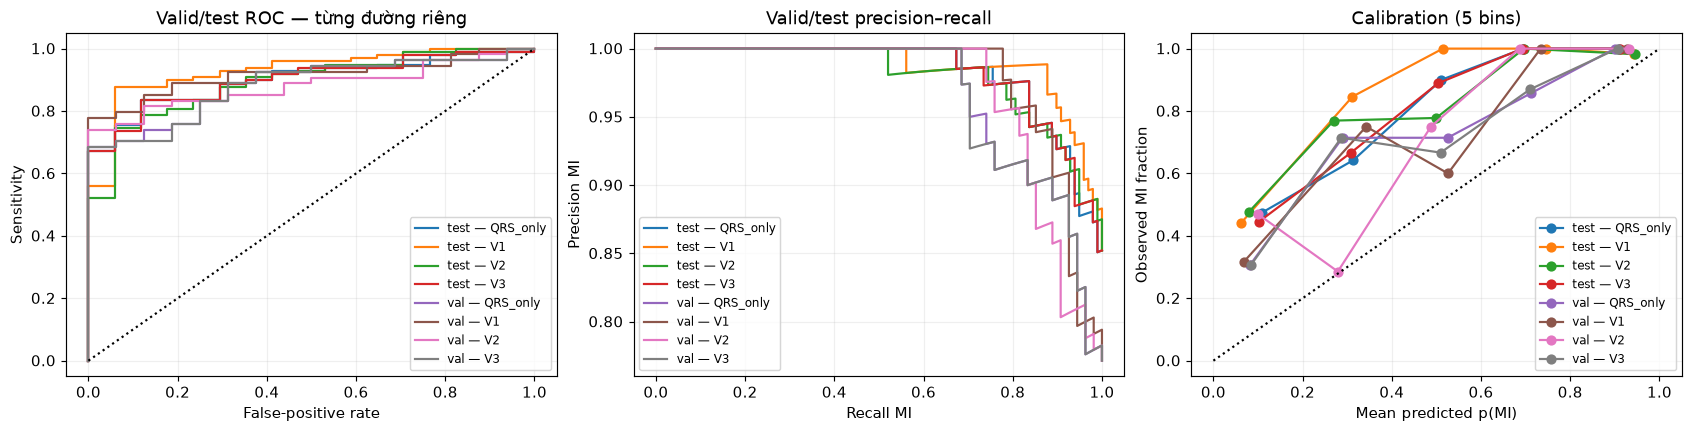

In [29]:
cx_ml_metrics=pd.DataFrame(); cx_ml_predictions=pd.DataFrame()
CX_ML_FEATURE_POLICY="valid"  # valid: candidate hợp lệ; accepted: mask T nếu chưa qua screening
if CX_RUN_ML:
    if not CX_RUN_COHORT or CX_SCOPE!="all" or CX_COHORT_LIMIT is not None:
        raise ValueError("ML cần full cohort: CX_RUN_COHORT=True, CX_SCOPE='all', CX_COHORT_LIMIT=None.")
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (confusion_matrix,accuracy_score,balanced_accuracy_score,
        precision_score,recall_score,f1_score,matthews_corrcoef,roc_auc_score,
        average_precision_score,brier_score_loss,log_loss,roc_curve,precision_recall_curve)
    cx_assert_split(CX_SPLIT)
    metric_rows=[]; pred_rows=[]; ml_skipped=[]
    model_names=("QRS_only","V1","V2","V3")
    for method in model_names:
        source="V1" if method=="QRS_only" else method
        data=cx_cohort[cx_cohort.method.eq(source)].copy()
        if set(data.record_id)!=set(CX_SPLIT.record_id): raise ValueError("Cohort không phủ đúng manifest.")
        feats=[f for f in FEATURE_NAMES if f.startswith("QRS_")] if method=="QRS_only" else FEATURE_NAMES
        if method!="QRS_only" and CX_ML_FEATURE_POLICY=="accepted":
            data.loc[~data.accepted,[f for f in FEATURE_NAMES if f.startswith("T_")]]=np.nan
        elif CX_ML_FEATURE_POLICY not in ("valid","accepted"): raise ValueError("Unknown ML feature policy.")
        train=data[data.split.eq("train")]
        assert set(train.patient_id).isdisjoint(set(data[data.split.isin(["val","test"])].patient_id))
        if train.label_name.nunique()!=2 or train[feats].isna().all().any():
            ml_skipped.append(dict(method=method,reason="train lacks two classes or all-missing feature column"));continue
        model=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),
            LogisticRegression(max_iter=3000,class_weight="balanced",random_state=2026))
        model.fit(train[feats],train.label_name.eq("MI").astype(int))
        for split in ("val","test"):
            part=data[data.split.eq(split)]
            if part.empty: continue
            prob=model.predict_proba(part[feats])[:,list(model.classes_).index(1)]
            for rid,pid,label,p in zip(part.record_id,part.patient_id,part.label_name,prob):
                pred_rows.append(dict(method=method,split=split,record_id=rid,patient_id=pid,
                                      y=int(label=="MI"),probability_mi=float(p)))
    cx_ml_predictions=pd.DataFrame(pred_rows)
    display(pd.DataFrame(ml_skipped))
    CX_RESULTS["ml_skipped"]=pd.DataFrame(ml_skipped)
    def classification_row(method,split,unit,g):
        y=g.y.to_numpy(); prob=g.probability_mi.to_numpy(); pred=(prob>=.5).astype(int)
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        return dict(method=method,split=split,unit=unit,n=len(y),prevalence=float(y.mean()),
            tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),accuracy=accuracy_score(y,pred),
            balanced_accuracy=balanced_accuracy_score(y,pred),sensitivity=tp/(tp+fn) if tp+fn else np.nan,
            specificity=tn/(tn+fp) if tn+fp else np.nan,precision=precision_score(y,pred,zero_division=0),
            f1=f1_score(y,pred,zero_division=0),mcc=matthews_corrcoef(y,pred),
            roc_auc=roc_auc_score(y,prob) if len(np.unique(y))==2 else np.nan,
            average_precision=average_precision_score(y,prob) if len(np.unique(y))==2 else np.nan,
            brier=brier_score_loss(y,prob),log_loss=log_loss(y,prob,labels=[0,1]))
    if not cx_ml_predictions.empty:
        for (m,s),g in cx_ml_predictions.groupby(["method","split"]):
            metric_rows.append(classification_row(m,s,"record",g))
            assert g.groupby("patient_id").y.nunique().max()==1
            patient=g.groupby("patient_id").agg(y=("y","first"),probability_mi=("probability_mi","mean")).reset_index()
            metric_rows.append(classification_row(m,s,"patient_mean_probability",patient))
        cx_ml_metrics=pd.DataFrame(metric_rows)
        display(cx_ml_metrics)
        fig,axes=plt.subplots(1,3,figsize=(16,4),layout="constrained")
        for (split,m),g in cx_ml_predictions.groupby(['split','method']):
            m=split+' — '+m
            if g.y.nunique()<2: continue
            fpr,tpr,_=roc_curve(g.y,g.probability_mi);precision,recall,_=precision_recall_curve(g.y,g.probability_mi)
            axes[0].plot(fpr,tpr,label=m);axes[1].plot(recall,precision,label=m)
            bins=pd.cut(g.probability_mi,np.linspace(0,1,6),include_lowest=True)
            calibration=g.groupby(bins,observed=True).agg(mean_probability=("probability_mi","mean"),
                observed_MI=("y","mean"),n=("y","size"))
            axes[2].plot(calibration.mean_probability,calibration.observed_MI,"o-",label=m)
        axes[0].plot([0,1],[0,1],"k:");axes[2].plot([0,1],[0,1],"k:")
        axes[0].set(xlabel="False-positive rate",ylabel="Sensitivity",title="Valid/test ROC — từng đường riêng")
        axes[1].set(xlabel="Recall MI",ylabel="Precision MI",title="Valid/test precision–recall")
        axes[2].set(xlabel="Mean predicted p(MI)",ylabel="Observed MI fraction",title="Calibration (5 bins)")
        for ax in axes:
            ax.grid(alpha=.2)
            if ax.has_data(): ax.legend(fontsize=8)
        cx_show(fig,"downstream_ML")
else: print("CX_RUN_ML=False; không train model hay đọc test để lựa chọn option.")
CX_RESULTS.update(ml_metrics=cx_ml_metrics,ml_predictions=cx_ml_predictions)

### Export và checklist đọc kết luận

Bật CX_SAVE_REPORTS để ghi CSV + config + fingerprint, selected manifest và review queue vào outputs/vcg_shared_comparison/<notebook>/<run_tag_protocol>. Các file được ghi khi bạn chạy cell này. Đổi CX_RUN_TAG để giữ lại lần chạy cũ. Tất cả bảng candidate giữ nguyên; accepted_features riêng sẽ mask T ở ca chưa accepted, giúp tránh dùng nhầm.

Review queue ưu tiên ca mất biên, nhiều flags và pairwise delta lớn; đó là danh sách kiểm tra bằng mắt, không phải expert labels. Template reference để trống, không sao chép prediction làm ground truth.

Nếu sau này có annotation độc lập, cần cùng beat, time origin, fs, reviewer và nguồn nhãn; khi đó mới tính MAE/RMSE/bias/tolerance accuracy của boundaries hoặc Se/PPV/F1 của event matching. Hiện tại các mục này là “chưa có reference”, không gán bằng 0.

**Cách kết luận:** xem failures/coverage theo MI/HC và split → paired delta/IoU → robustness và feature sensitivity → downstream task nếu bật → xem thủ công ca bất đồng. Coverage, loop closure hoặc agreement cao không đủ để xếp hạng độ đúng T. Các cờ method khác nhau về độ bảo thủ; đọc riêng common_flags và method_flags trước khi dùng accepted rate để so sánh.

In [30]:
cx_review=cx_eval[["record_id","patient_id","split","method","native_status","accepted","flags"]].copy()
if not cx_pair_details.empty:
    disagreement=cx_pair_details.assign(
        max_delta_ms=cx_pair_details[["on_delta_ms","off_delta_ms"]].abs().max(axis=1)
    ).groupby("record_id").max_delta_ms.max()
    cx_review=cx_review.merge(disagreement,on="record_id",how="left")
cx_review=cx_review.sort_values(["accepted","record_id"],ascending=[True,True])
display(cx_review.head(30))
cx_reference=CX_SPLIT[CX_SPLIT.record_id.isin(cx_eval.record_id)][["record_id","patient_id","split"]].copy()
cx_reference["time_reference"]="median_relative_ms"
for name in ("qrs_on_ms","qrs_off_ms","t_on_ms","t_off_ms","reviewer","reference_source"):
    cx_reference[name]=np.nan if name.endswith("_ms") else ""
cx_reference["independent_reference"]=False
CX_RESULTS.update(review_queue=cx_review,reference_template=cx_reference)
cx_packages={p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","matplotlib","wfdb","scikit-learn")}
if CX_SAVE_REPORTS:
    CX_OUT.mkdir(parents=True,exist_ok=True)
    for name,table in CX_RESULTS.items():
        if isinstance(table,pd.DataFrame): table.to_csv(CX_OUT/(name+".csv"),index=False)
    safe_features=cx_eval.copy()
    safe_features.loc[~safe_features.accepted,[f for f in FEATURE_NAMES if f.startswith("T_")]]=np.nan
    safe_features.to_csv(CX_OUT/"accepted_features.csv",index=False)
    (CX_OUT/"config.json").write_text(json.dumps(json_safe(dict(cx_config,
        protocol_id=CX_PROTOCOL_ID,packages=cx_packages,notebook=CX_NOTEBOOK,
        run_tag=CX_RUN_TAG,feature_policy=CX_ML_FEATURE_POLICY)),ensure_ascii=False,indent=2),encoding="utf-8")
    print("Saved:",CX_OUT)
else: print("Chỉ hiển thị. Bật CX_SAVE_REPORTS nếu muốn lưu bảng.")
print("Không có T reference: chưa tính boundary accuracy, MAE/RMSE với truth hoặc QRS event Se/PPV.")
# Báo cáo riêng từng method, cùng schema và cùng split; không thay cohort theo ca thành công.
if CX_SAVE_REPORTS:
    for method in CX_METHODS:
        target=CX_OUT/'methods'/method;target.mkdir(parents=True,exist_ok=True)
        cx_eval[cx_eval.method.eq(method)].to_csv(target/'record_results.csv',index=False)
        cx_coverage[cx_coverage.method.eq(method)].to_csv(target/'summary_by_split.csv',index=False)
        cx_subgroups[cx_subgroups.method.eq(method)].to_csv(target/'summary_by_label_split.csv',index=False)
        for key in ('flags','stability_summary','beat_bootstrap_summary','sensitivity_scenarios','ml_metrics'):
            table=CX_RESULTS.get(key,pd.DataFrame())
            if not table.empty and 'method' in table:table[table.method.eq(method)].to_csv(target/(key+'.csv'),index=False)
    manifest_identity=hashlib.sha256(cx_selected.sort_values('record_id').to_csv(index=False).encode()).hexdigest()
    numeric_columns=['t_on_ms','t_off_ms','duration_ms','valid_pair','accepted',*FEATURE_NAMES]
    canonical=cx_eval.sort_values(['record_id','method']).set_index(['record_id','method'])[numeric_columns]
    manifest=dict(protocol_id=CX_PROTOCOL_ID,selected_manifest_sha256=manifest_identity,
        records=len(cx_selected),method_record_rows=len(cx_eval),focus_method=CX_FOCUS_METHOD,
        split_counts=cx_selected.groupby('split').size().to_dict(),cache=str(CX_CACHE),
        runtime_note='cached times originate from initial computation; not independent runtime benchmark',
        test_policy='fixed protocol only; option sweep restricted to train/val')
    (CX_OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    checks=[]
    for notebook in ('05_QRS_T_Loops_Step_by_Step','09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment','10_VCG_V3_Consensus_T_Delineation'):
        other=CX_ROOT/'outputs/vcg_shared_comparison'/notebook/(CX_RUN_TAG+'_'+CX_PROTOCOL_ID)
        if not (other/'run_manifest.json').is_file():
            checks.append(dict(notebook=notebook,status='chưa chạy/lưu cùng protocol'));continue
        saved=json.loads((other/'run_manifest.json').read_text(encoding='utf-8'))
        same_manifest=saved.get('selected_manifest_sha256')==manifest_identity
        table_path=other/'cohort.csv' if CX_RUN_COHORT else other/'demo_rows.csv'
        equal=False
        if same_manifest and table_path.is_file():
            prior=pd.read_csv(table_path).sort_values(['record_id','method']).set_index(['record_id','method'])[numeric_columns]
            equal=canonical.index.equals(prior.index) and np.allclose(canonical.to_numpy(dtype=float),prior.to_numpy(dtype=float),equal_nan=True,rtol=1e-9,atol=1e-10)
        checks.append(dict(notebook=notebook,same_manifest=same_manifest,same_numerical_results=equal,
                           status='OK' if same_manifest and equal else 'CẦN KIỂM TRA'))
    cx_cross_notebooks=pd.DataFrame(checks);display(cx_cross_notebooks)
    cx_cross_notebooks.to_csv(CX_OUT/'cross_notebook_checks.csv',index=False)
print('Báo cáo riêng notebook này:',CX_FOCUS_METHOD,'| đánh giá chung: V1/V2/C/V3; train/valid/test tách riêng.')


,record_id,patient_id,split,method,native_status,accepted,flags,max_delta_ms
14,patient001/s0010_re,patient001,train,C,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,45.0
15,patient001/s0010_re,patient001,train,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,45.0
37,patient001/s0014lre,patient001,train,V2,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
38,patient001/s0014lre,patient001,train,C,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
39,patient001/s0014lre,patient001,train,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
61,patient001/s0016lre,patient001,train,V2,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
62,patient001/s0016lre,patient001,train,C,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
63,patient001/s0016lre,patient001,train,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
6,patient002/s0015lre,patient002,test,C,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,29.0
7,patient002/s0015lre,patient002,test,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,29.0


Saved: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\10_VCG_V3_Consensus_T_Delineation\full_cohort_01_5689e262aabaf89b
Không có T reference: chưa tính boundary accuracy, MAE/RMSE với truth hoặc QRS event Se/PPV.


,notebook,status,same_manifest,same_numerical_results
0,05_QRS_T_Loops_Step_by_Step,chưa chạy/lưu cùng protocol,NaN,NaN
1,09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment,chưa chạy/lưu cùng protocol,NaN,NaN
2,10_VCG_V3_Consensus_T_Delineation,OK,True,True


Báo cáo riêng notebook này: V3 | đánh giá chung: V1/V2/C/V3; train/valid/test tách riêng.
